# Algebra

Vier Stufen der Algebra, jeweils durchgerechnet mit numpy, scipy, sympy und networkx: Gruppen (eine Verknüpfung, von Verknüpfungstafeln über den Zauberwürfel bis zum Monster und zur Clifford-Gruppe), Ringe und Körper (zwei Verknüpfungen, von ℤₙ über endliche Körper und Reed-Solomon bis zu p-adischen Zahlen und Post-Quanten-Kryptographie), Eigenwerte (lineare Abbildungen über einem Körper, von der Anschauung über numerische Verfahren bis zum Quantencomputer) und Lie-Theorie (Gruppen, die zugleich glatte Räume sind, mit Wurzelsystemen, Darstellungen und Anwendungen in Physik und Quantenrechnen). Daten werden nicht geladen; die Isomere in Schritt 7 zeichnet rdkit. Der Code steht in [`code/algebra/`](https://github.com/deltorobarba/science/tree/main/code/algebra), ein Modul je Teil (`groups.py`, `rings.py`, `eigen.py`, `lie.py`); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Die vier Teile sind eine Leiter: Jede Stufe fügt der vorigen Struktur hinzu.

- **Schritte 1 bis 17, Gruppen:** eine Verknüpfung, die man umkehren kann. Daraus folgen Lagrange, das Zählen von Isomeren, die Bausteine aller endlichen Gruppen und die Symmetrien von Molekülen, Kristallen und Qubits.
- **Schritte 18 bis 32, Ringe und Körper:** zwei Verknüpfungen. Primzahlen, eindeutige Zerlegung, endliche Körper für Fehlerkorrektur und Kryptographie, Galois-Gruppen, die Gleichungen mit Gruppen verbinden.
- **Schritte 33 bis 50, Eigenwerte:** lineare Abbildungen über einem Körper. Eigenvektoren sind die Richtungen, die nur gestreckt werden; sie erklären Potenzen, Schwingungen, Hauptkomponenten, numerische Verfahren und Messwerte in der Quantenmechanik.
- **Schritte 51 bis 66, Lie-Theorie:** Gruppen, die zugleich glatte Räume sind. Ihre Algebra ist lineare Algebra, ihre Wurzeln sind Eigenwerte, und ihre Darstellungen ordnen Spins, Moleküle und Quarks.

Die gemeinsame Lehre: Symmetrie lässt sich rechnen. Was unter einer Gruppe unverändert bleibt (Ordnungen, Spuren, Eigenwerte, Charaktere), ordnet die Fälle, und aus dieser Ordnung folgen Auswahlregeln, Zählformeln und Unmöglichkeitsbeweise.

In [1]:
import sys
import subprocess
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "algebra"
if "google.colab" in sys.modules:                            # in Colab: Pakete installieren, Code aus dem Repository holen
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rdkit"], check=True)
    if not CODE.exists():
        CODE.mkdir(parents=True)
        for f in ["groups.py", "rings.py", "eigen.py", "lie.py"]:
            urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/algebra/{f}", CODE / f)
elif importlib.util.find_spec("rdkit") is None or importlib.util.find_spec("networkx") is None or importlib.util.find_spec("sympy") is None or importlib.util.find_spec("sklearn") is None:
    raise ImportError("Es fehlt eines der Pakete rdkit, networkx, sympy, sklearn; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import groups, rings, eigen, lie

**1. Gruppen: Werkzeuge**

Eine Gruppe ist die Mathematik der Symmetrie. Wann immer man etwas umformen kann, ohne dass sich das Wesentliche ändert (ein Molekül drehen, Teilchen vertauschen, einen Zauberwürfel verdrehen, ein Qubit mit einem Gatter bearbeiten), bilden die Umformungen eine Gruppe: Man kann sie hintereinander ausführen, rückgängig machen, und „nichts tun“ ist auch eine. Aus diesen drei Eigenschaften folgt erstaunlich viel. Zuerst werden Werkzeuge bereitgestellt: endliche Matrixgruppen aus wenigen Erzeugern, Elementordnungen, Verknüpfungstafeln, Zentrum und Konjugationsklassen; für Permutationen sympy.

Die Ausgabe meldet die Werkzeuge bereit; Permutationsgruppen rechnet sympy mit dem Schreier-Sims-Algorithmus.

In [2]:
groups.load()

Werkzeuge bereit: Matrixgruppen, Ordnungen, Verknüpfungstafeln, Invarianten, Einfachheitstest


**2. Verknüpfungstafeln kleiner Gruppen**

Vier Gruppen mit sechs oder acht Elementen: die Drehungen ℤ₆, die Vertauschungen S₃ von drei Dingen, die Symmetrien D₄ des Quadrats und die Quaternionengruppe Q₈ aus den Pauli-Matrizen. Jede Tafel zeigt das Produkt a·b als Farbe.

Alle vier Tafeln sind lateinische Quadrate: Jede Farbe kommt in jeder Zeile und Spalte genau einmal vor, weil man in einer Gruppe immer zurückrechnen kann. Nur die Tafel von ℤ₆ ist an der Diagonale gespiegelt gleich; die Gruppe ist abelsch, bei den anderen hängt das Ergebnis von der Reihenfolge ab.

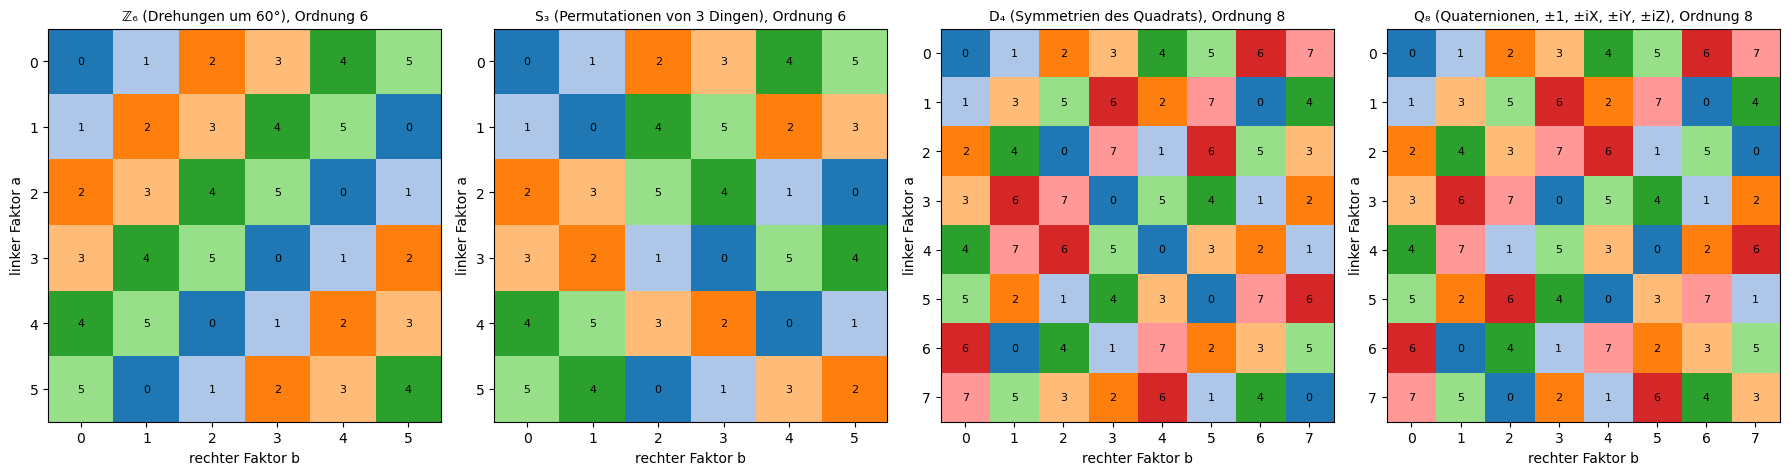

ℤ₆ (Drehungen um 60°)                 : Ordnung  6; lateinisches Quadrat True; assoziativ True; Tafel symmetrisch (abelsch) True; Elementordnungen [1, 2, 3, 3, 6, 6]
S₃ (Permutationen von 3 Dingen)       : Ordnung  6; lateinisches Quadrat True; assoziativ True; Tafel symmetrisch (abelsch) False; Elementordnungen [1, 2, 2, 2, 3, 3]
D₄ (Symmetrien des Quadrats)          : Ordnung  8; lateinisches Quadrat True; assoziativ True; Tafel symmetrisch (abelsch) False; Elementordnungen [1, 2, 2, 2, 2, 2, 4, 4]
Q₈ (Quaternionen, ±1, ±iX, ±iY, ±iZ)  : Ordnung  8; lateinisches Quadrat True; assoziativ True; Tafel symmetrisch (abelsch) False; Elementordnungen [1, 2, 4, 4, 4, 4, 4, 4]


In [3]:
groups.cayley_tables()

**3. Gruppen der Ordnung 8 und 12 unterscheiden**

Wie unterscheidet man Gruppen gleicher Größe? Gezählt wird, wie viele Elemente jede Ordnung haben, also wie oft man sie anwenden muss, bis wieder alles wie am Anfang ist.

Benennt man die Elemente um, ändert sich keine Ordnung; verschiedene Muster heißen deshalb verschiedene Gruppen. So lassen sich alle fünf Gruppen der Ordnung 8 und alle fünf der Ordnung 12 auseinanderhalten. Nach Lagrange kommen nur Teiler von 8 und 12 als Ordnungen vor.

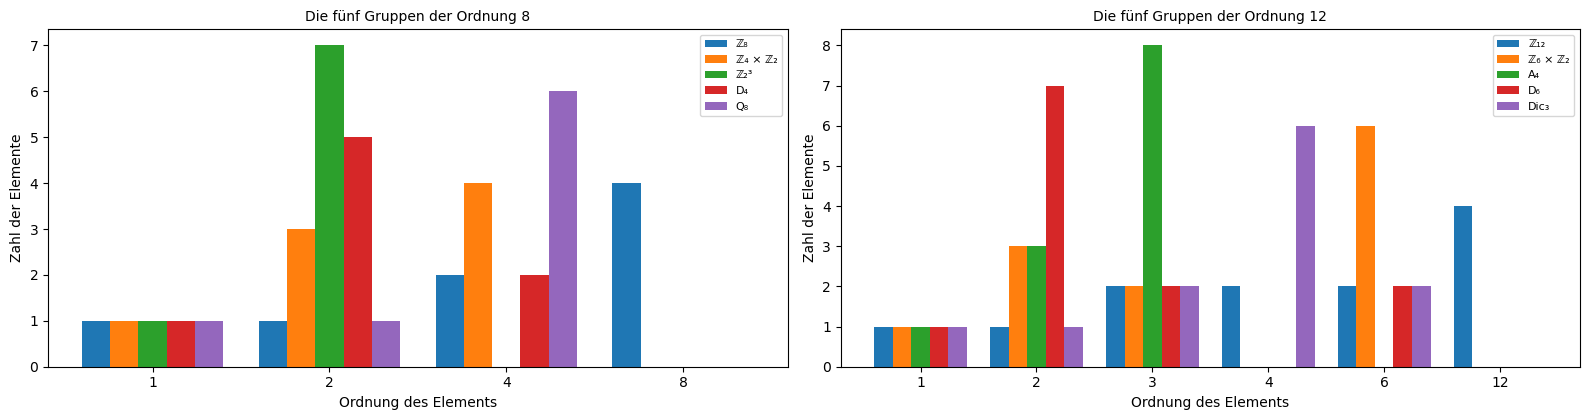

Gruppe    Ordnung  abelsch  |Zentrum|  |[G,G]|  Klassen   Elementordnungen
ℤ₈              8     True          8        1        8   {1: 1, 2: 1, 4: 2, 8: 4}
ℤ₄ × ℤ₂         8     True          8        1        8   {1: 1, 2: 3, 4: 4}
ℤ₂³             8     True          8        1        8   {1: 1, 2: 7}
D₄              8    False          2        2        5   {1: 1, 2: 5, 4: 2}
Q₈              8    False          2        2        5   {1: 1, 2: 1, 4: 6}
ℤ₁₂            12     True         12        1       12   {1: 1, 2: 1, 3: 2, 4: 2, 6: 2, 12: 4}
ℤ₆ × ℤ₂        12     True         12        1       12   {1: 1, 2: 3, 3: 2, 6: 6}
A₄             12    False          1        4        4   {1: 1, 2: 3, 3: 8}
D₆             12    False          2        3        6   {1: 1, 2: 7, 3: 2, 6: 2}
Dic₃           12    False          2        3        6   {1: 1, 2: 1, 3: 2, 4: 6, 6: 2}


In [4]:
groups.order_8_12()

**4. Wie viele Gruppen gibt es?**

Die Zahl der verschiedenen Gruppen jeder Ordnung bis 128, mit dem Anteil der abelschen.

Zu einer Primzahl gibt es genau eine Gruppe, zu p² zwei, zu p·q eine oder zwei. Bei Zweierpotenzen explodiert die Zahl: 14 Gruppen der Ordnung 16, 267 der Ordnung 64, 2328 der Ordnung 128. Abelsche Gruppen sind fast überall eine kleine Minderheit.

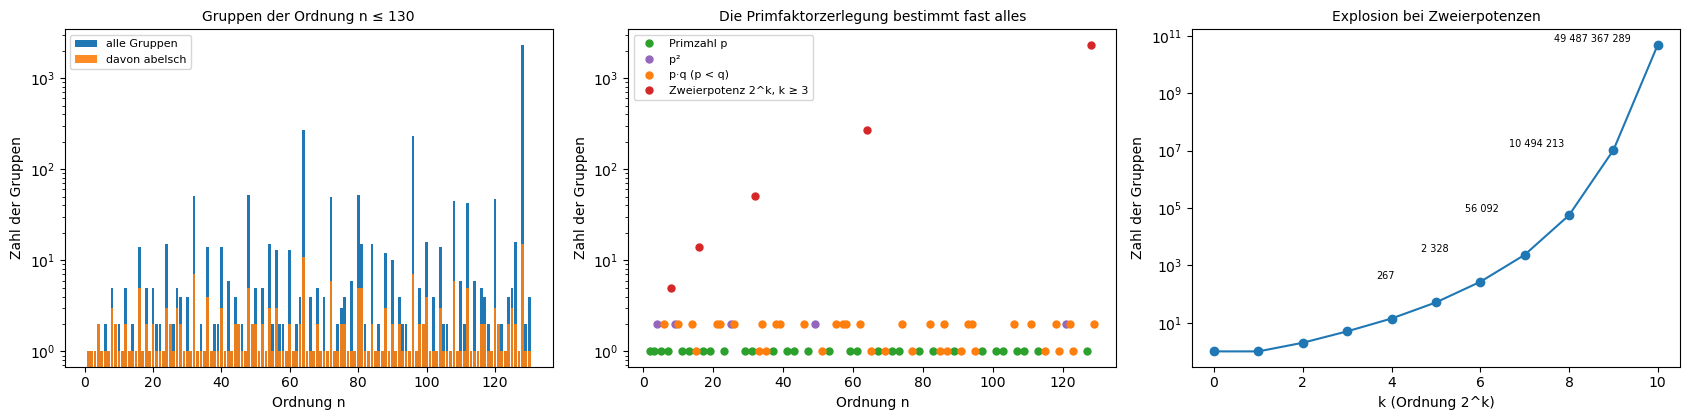

Ordnung p (Primzahl): immer genau {1} Gruppe;  Ordnung p²: immer {2}
Ordnung p·q: Vorhersage 2 wenn p | q − 1, sonst 1 – stimmt für alle 38 Fälle bis 130: True
Gruppen der Ordnung ≤ 130: 3602, davon Ordnung 128: 2328 (65%); abelsch insgesamt 249


In [5]:
groups.counting_groups()

**5. Untergruppen, Lagrange und Normalteiler**

Alle Untergruppen der Vertauschungen S₄ von vier Dingen (24 Elemente), als Verband nach Größe geordnet; markiert sind die Normalteiler, die bei Konjugation in sich übergehen.

S₄ hat 30 Untergruppen, und alle Ordnungen teilen 24 (Lagrange). Nur vier davon sind Normalteiler, mit 1, 4, 12 und 24 Elementen; nur nach ihnen lässt sich eine Faktorgruppe bilden, etwa S₄ / V₄ mit 6 Elementen.

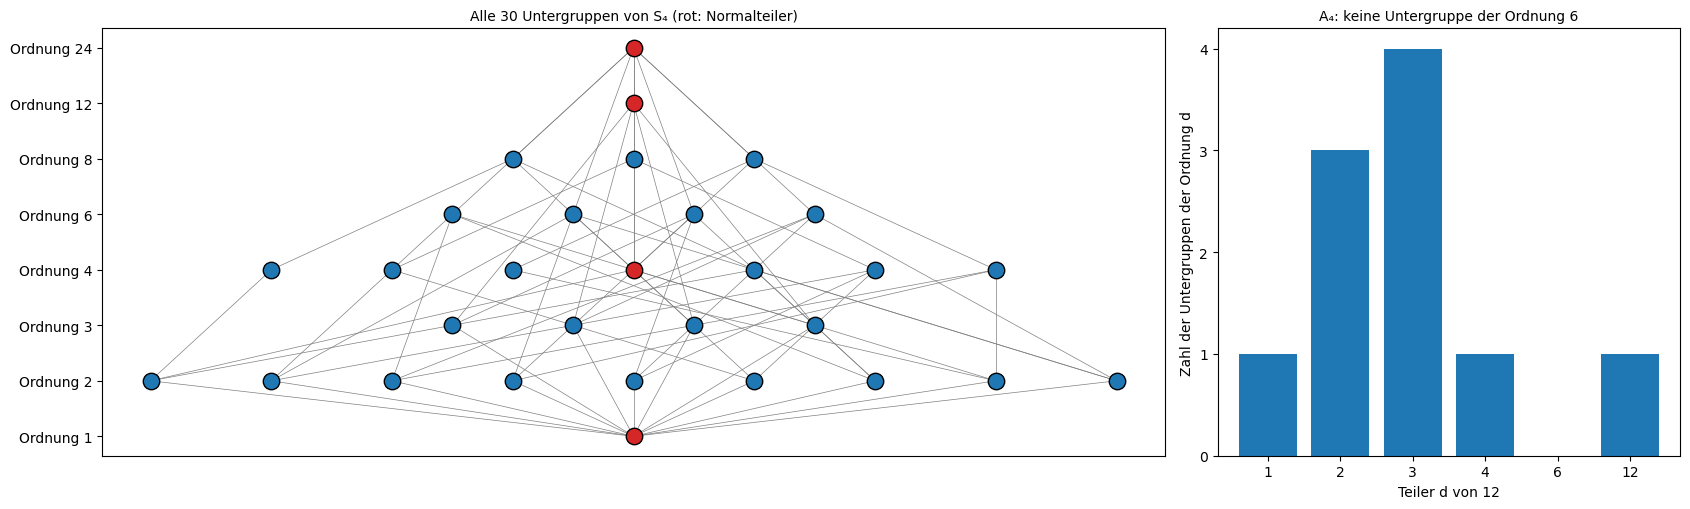

Untergruppen von S₄ nach Ordnung: {1: 1, 2: 9, 3: 4, 4: 7, 6: 4, 8: 3, 12: 1, 24: 1} – alle Ordnungen teilen 24: True
Normalteiler von S₄ (Ordnungen): [1, 4, 12, 24]
S₄/V₄: 6 Nebenklassen; die Faktorgruppe ist nicht abelsch und damit ≅ S₃
Untergruppen von A₄ nach Ordnung: {1: 1, 2: 3, 3: 4, 4: 1, 6: 0, 12: 1}


In [6]:
groups.s4_lattice()

**6. Gruppenoperationen zählen: Burnside**

Wie viele wirklich verschiedene Muster gibt es, wenn man Muster, die durch eine Symmetrie ineinander übergehen, als gleich zählt? Das Lemma von Burnside mittelt dafür die Fixpunkte aller Symmetrien. Beispiele sind Chlorbenzole und Würfelfärbungen.

Von den 64 Stellungen von Chloratomen am Benzolring bleiben 13 verschiedene Moleküle; mit zwei Chloratomen werden aus 15 Stellungen genau 3: ortho, meta und para. Die durchgezählten Würfelfärbungen liegen genau auf der Formel: 1, 10, 57 und 240 für eine bis vier Farben.

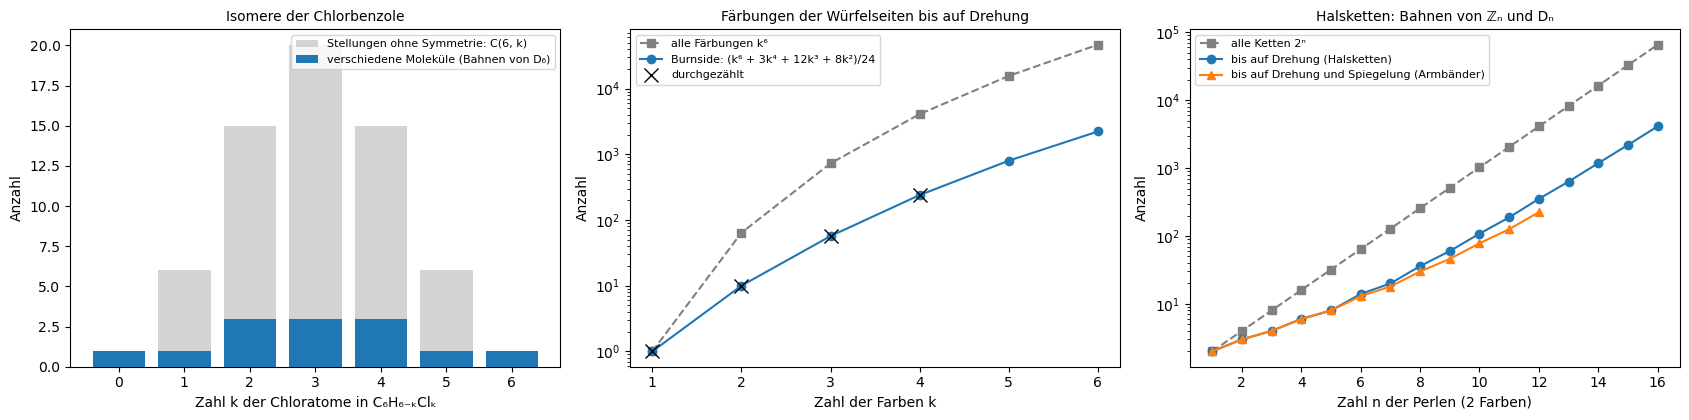

Chlorbenzole C₆H₆₋ₖClₖ für k = 0 … 6: [1, 1, 3, 3, 3, 1, 1] (Burnside [1, 1, 3, 3, 3, 1, 1]), zusammen 13
Drehgruppe des Würfels: 24 Elemente; Färbungen mit k = 1 … 4 Farben durchgezählt [1, 10, 57, 240], Burnside [1, 10, 57, 240]
Halsketten mit 2 Farben, n = 6, 10, 16: 14, 108, 4116;  Armbänder n = 6, 10: 13, 78


In [7]:
groups.burnside()

**7. Chemische Isomere**

Dieselbe Zählung mit Chemie-Software (rdkit): Jedes Muster wird ein Molekül, und die kanonische Schreibweise (SMILES) erkennt gleiche Moleküle.

Die drei Dichlorbenzole ortho, meta und para sind gezeichnet; jede andere Stellung geht durch Drehen oder Spiegeln in eines davon über. Die 64 Muster ergeben 13 verschiedene SMILES, dieselben Zahlen wie Burnside.

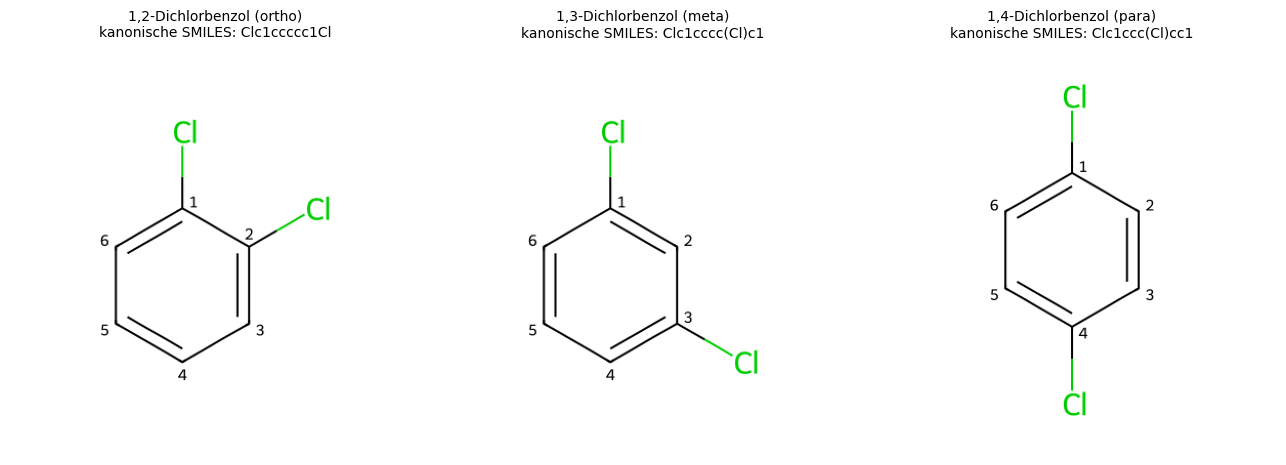

RDKit: aus 64 Mustern werden 13 verschiedene Moleküle, für k = 0 … 6: [1, 1, 3, 3, 3, 1, 1] (Burnside [1, 1, 3, 3, 3, 1, 1])
Stellungen je Dichlorbenzol (Bahngröße): ortho 6, meta 6, para 3


In [8]:
groups.chemical_isomers()

**8. Die symmetrische Gruppe**

Zyklen, Vorzeichen und zufällige Permutationen der symmetrischen Gruppe S_n: wie viele Elemente, wie viele Klassen, wie viele Fixpunkte, wie lang der längste Zyklus.

n! wächst rasant (2.7·10³² bei n = 30), die Zahl der Klassen nur moderat (5604). Die Zahl der Fixpunkte einer zufälligen Permutation folgt einer Poisson-Verteilung mit Mittel 1; ohne Fixpunkt sind 36.9 % (theoretisch 1/e). Der längste Zyklus umfasst im Mittel 62 % der Elemente.

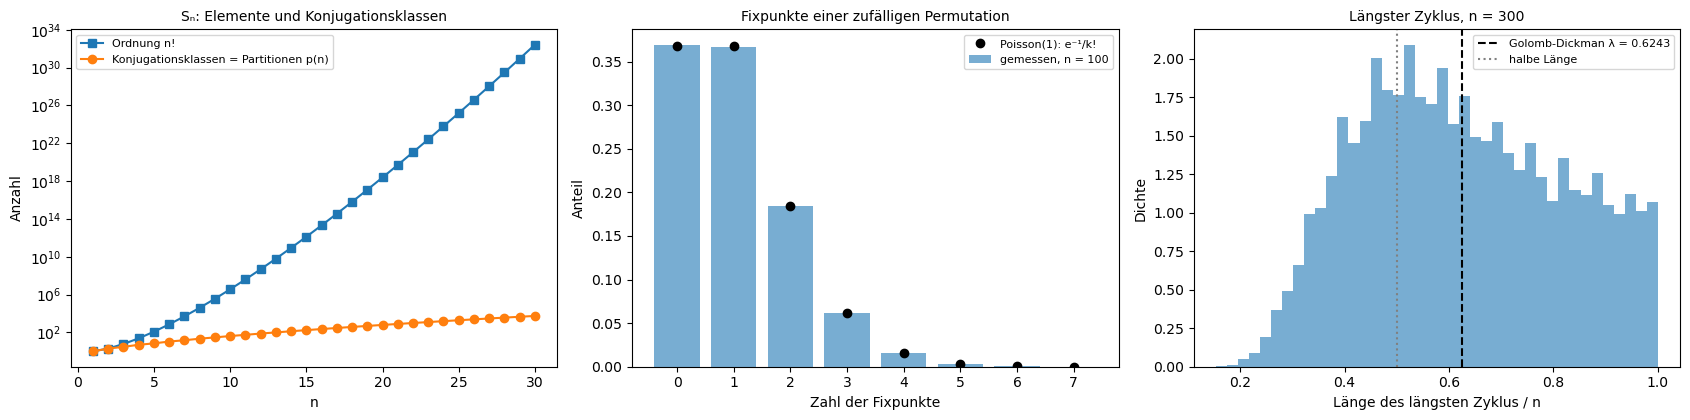

Fixpunktfreie Permutationen (Derangements): 0.3685  (Theorie 1/e = 0.3679);  mittlere Fixpunktzahl 0.999 (Theorie 1)
Mittlere Zahl der Zyklen bei n = 300: 6.283 (Theorie H_n = 6.283);  längster Zyklus im Mittel 0.6252·n (exakt für n = 300: 0.6254, für n → ∞: 0.6243); Anteil mit einem Zyklus länger als n/2: 0.694 (exakt 0.6915, für n → ∞: ln 2 = 0.693)
15-Puzzle: Vertauschen von 14 und 15 bei Leerfeld unten rechts ist eine Permutation mit Vorzeichen -1 → nicht lösbar


In [9]:
groups.symmetric_group()

**9. Der Zauberwürfel als Permutationsgruppe**

Die Drehungen des Zauberwürfels sind Permutationen seiner 48 beweglichen Felder; sie bilden eine Gruppe mit 4.3·10¹⁹ Elementen. Gemessen wird die Ordnung zufälliger Zustände und einfacher Zugfolgen.

Ein typischer Zustand braucht Dutzende bis Hunderte Wiederholungen, bis er sich auflöst; die größte Ordnung ist 1260, das Maximum der Gruppe. Eine einzelne Drehung hat Ordnung 4, „vorne, rechts“ schon 105. Die Zufallszustände sind nicht festgelegt, deshalb schwanken die Anteile von Lauf zu Lauf leicht.

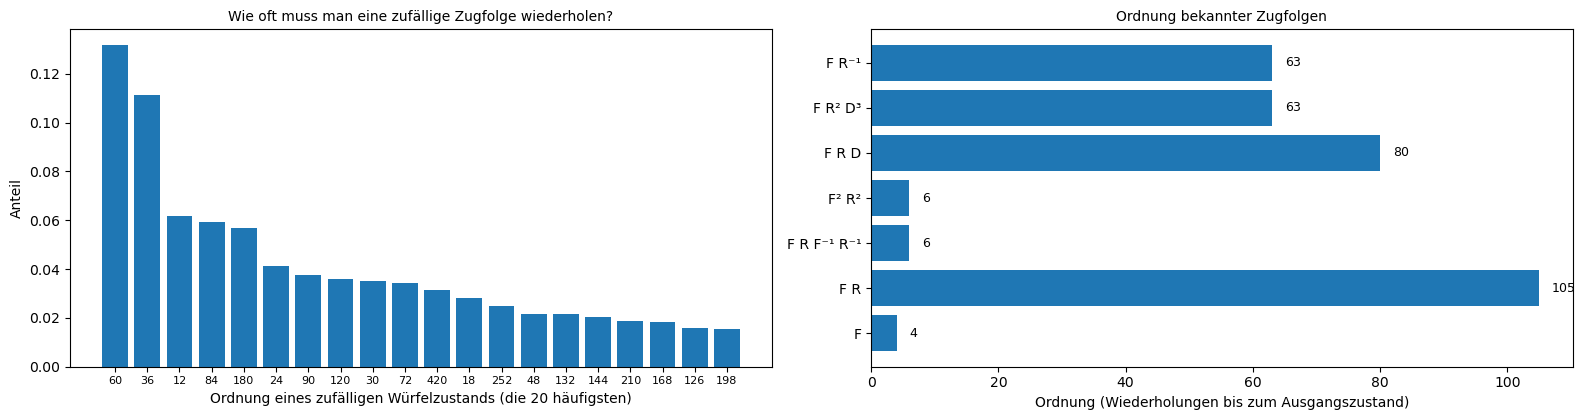

Ordnung der Würfelgruppe: 43 252 003 274 489 856 000 = 2^27 · 3^14 · 5^3 · 7^2 · 11^1
Zerlegt man den Würfel und setzt ihn beliebig zusammen, gibt es 12-mal so viele Zustände: 519 024 039 293 878 272 000
Nur die drei Seiten F, R, D (an einer Ecke): Untergruppe der Ordnung 170 659 735 142 400, Index 253 440
5000 Zufallszustände: größte Ordnung 1260 (Maximum der Gruppe: 1260), Median 72, Anteil mit Ordnung ≤ 12: 0.069


In [10]:
groups.rubik()

**10. Abelsche Gruppen: die Einheitengruppe modulo n**

Die Zahlen, die modulo n ein Inverses haben, bilden eine abelsche Gruppe. Nach Gauß ist sie genau dann zyklisch (von einem Element erzeugt), wenn n = 2, 4, pᵏ oder 2pᵏ ist.

114 der 299 Gruppen sind zyklisch, und Gauß' Kriterium stimmt für alle. Die Potenzen eines Erzeugers springen scheinbar zufällig über alle Reste; ihre Umkehrung, der diskrete Logarithmus, ist schwer, und darauf beruht der Schlüsseltausch von Diffie und Hellman.

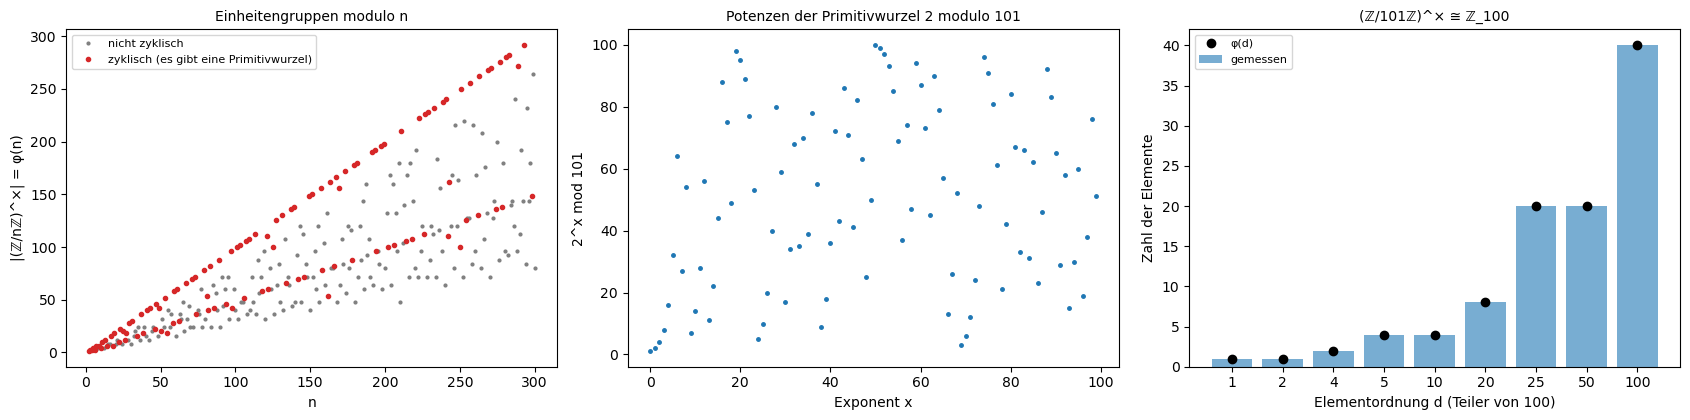

Zyklisch für n ≤ 300: 114 von 299 Werten; Gauß' Kriterium stimmt für alle: True
Beispiele: (ℤ/8ℤ)^× hat φ = 4, Exponent λ = 2 → ℤ₂ × ℤ₂;  (ℤ/15ℤ)^× hat φ = 8, λ = 4 → ℤ₂ × ℤ₄;  (ℤ/101ℤ)^× ist zyklisch mit Erzeuger 2: True
Elementordnungen in (ℤ/101ℤ)^×: {1: 1, 2: 1, 4: 2, 5: 4, 10: 4, 20: 8, 25: 20, 50: 20, 100: 40}  (Theorie φ(d) für jeden Teiler d)


In [11]:
groups.units_mod_n()

**11. Einfache Gruppen: die Bausteine**

Jede endliche Gruppe setzt sich aus einfachen Gruppen zusammen, die keine Normalteiler haben, wie eine Zahl aus Primzahlen. Geprüft werden einige Gruppen, und gezählt werden alle nichtabelschen einfachen Gruppen unter 30 000 Elementen.

S₄ zerfällt über A₄ und V₄ bis zur Eins: auflösbar. Bei S₅ bleibt die Kette bei A₅ mit 60 Elementen stehen, der kleinsten nichtabelschen einfachen Gruppe; deshalb gibt es für Gleichungen fünften Grades keine Lösungsformel mit Wurzeln. Nichtabelsche einfache Gruppen sind selten: 23 unter 30 000 Elementen.

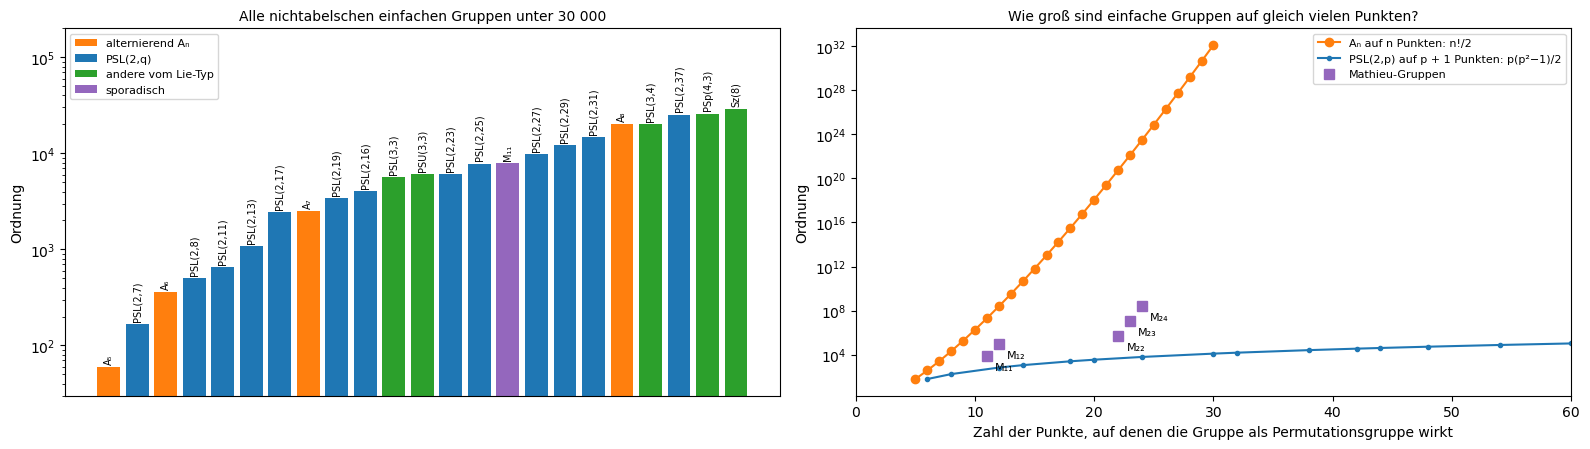

Gruppe    Ordnung  einfach  auflösbar   Kommutatorreihe (Ordnungen)
ℤ₇              7     True       True   [7, 1]
S₄             24    False       True   [24, 12, 4, 1]
S₅            120    False      False   [120, 60]
A₅             60     True      False   [60]
A₆            360     True      False   [360]
PSL(2,7)      168     True      False   [168]
M₁₁          7920     True      False   [7920]
M₁₂         95040     True      False   [95040]
Ordnungen aus den Formeln für Aₙ und PSL(2,q) unter 30 000: alle in der Liste: True; die kleinste Ordnung mit zwei verschiedenen einfachen Gruppen ist 20 160 (A₈ und PSL(3,4))


In [12]:
groups.simple_groups()

**12. Sporadische Gruppen: Mathieu-Gruppen und der Golay-Code**

Die Klassifikation der einfachen Gruppen kennt 18 Familien und 26 Ausnahmen, die sporadischen Gruppen. Die kleinsten, die Mathieu-Gruppen, werden aus Erzeugern berechnet; M₂₄ ist die Symmetrie des binären Golay-Codes.

Die sporadischen Gruppen reichen von 7920 Elementen (M₁₁) bis 10⁵⁴ (Monster). Alle fünf berechneten Mathieu-Ordnungen stimmen. Der Golay-Code hat 759 Wörter vom Gewicht 8, die Oktaden, und korrigiert drei Fehler in 24 Bits.

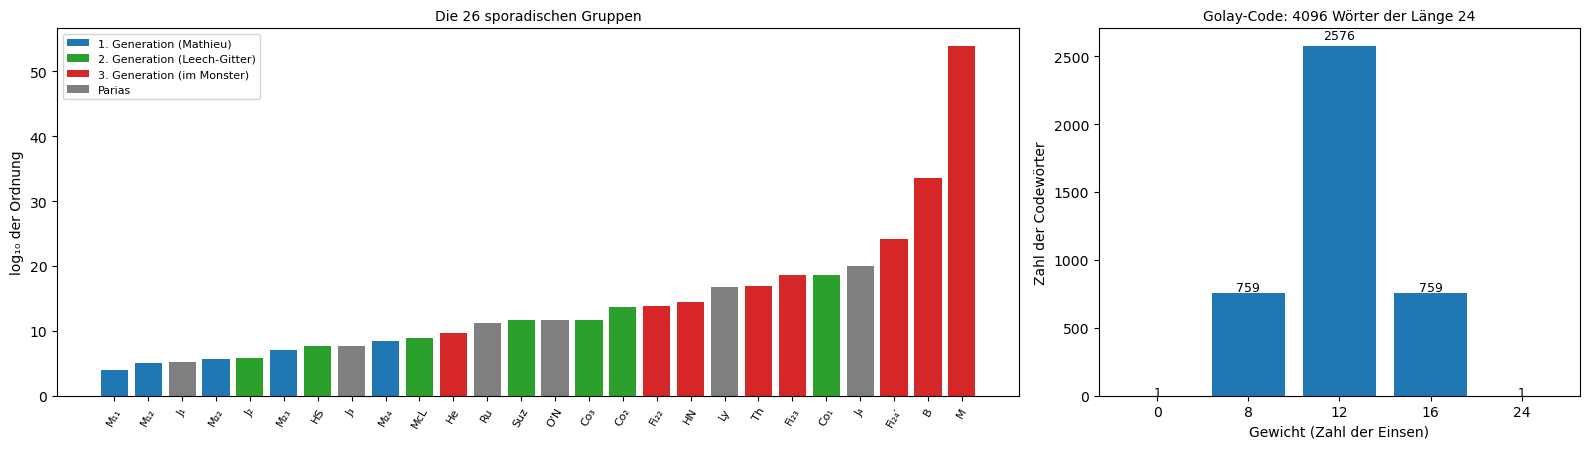

M₁₁: Ordnung       7 920  (Liste: 7 920)
M₁₂: Ordnung      95 040  (Liste: 95 040)
M₂₂: Ordnung     443 520  (Liste: 443 520)
M₂₃: Ordnung  10 200 960  (Liste: 10 200 960)


M₂₄: Ordnung 244 823 040  (Liste: 244 823 040)


Transitivität: M₁₂ ist 5-fach, M₂₄ ist 5-fach transitiv
Golay-Code: Gewichte {0: 1, 8: 759, 12: 2576, 16: 759, 24: 1}, kleinster Abstand 8 → korrigiert 3 Fehler; die drei Erzeuger von M₂₄ erhalten den Code: [True, True, True]
Ordnung des Monsters: 8.080e+53;  Verhältnis Monster / M₂₄ = 3.3e+45


In [13]:
groups.sporadic_groups()

**13. Das Monster und Moonshine**

Das Monster ist die größte sporadische Gruppe. 1978 bemerkte McKay, dass der Koeffizient 196 884 der j-Funktion aus der Zahlentheorie 1 + 196 883 ist, die Summe der kleinsten Darstellungen des Monsters.

Auch die nächsten Koeffizienten zerlegen sich in Dimensionen von Monster-Darstellungen, und die Koeffizienten wachsen wie vorhergesagt. Borcherds bewies 1992 diesen „Moonshine“ mit Methoden der Stringtheorie und bekam dafür die Fields-Medaille.

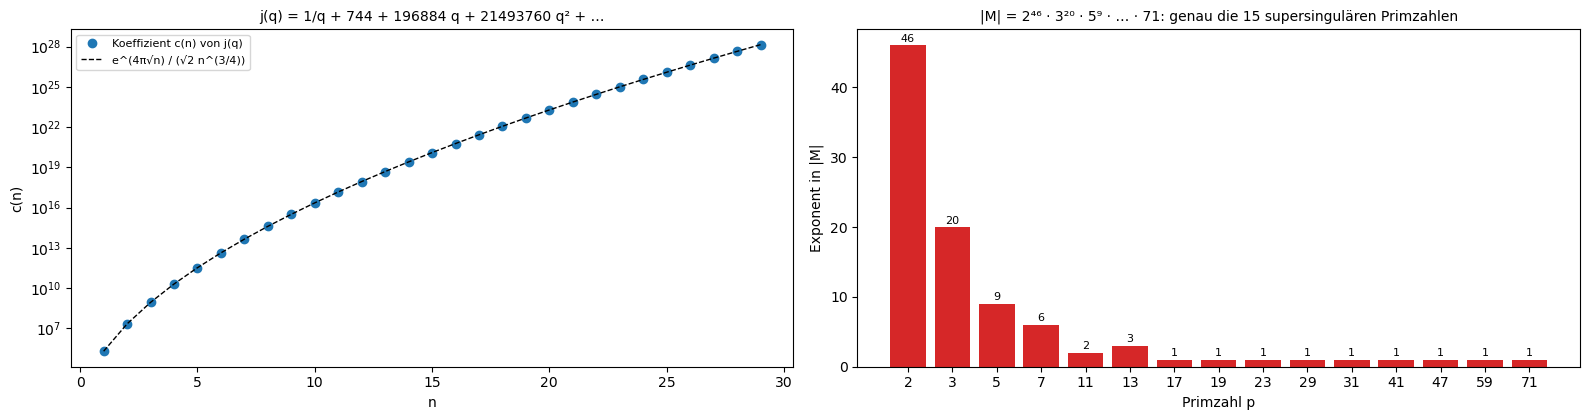

j(q) − 744 = 1/q + 196884 q^1 + 21493760 q^2 + 864299970 q^3 + 20245856256 q^4 + …
c(1) =       196884 = 1·1 + 1·196883  →  True
c(2) =     21493760 = 1·1 + 1·196883 + 1·21296876  →  True
c(3) =    864299970 = 2·1 + 2·196883 + 1·21296876 + 1·842609326  →  True
c(4) =  20245856256 = 3·1 + 3·196883 + 1·21296876 + 2·842609326 + 1·18538750076  →  True
|M| = 808017424794512875886459904961710757005754368000000000 ≈ 8.08e+53;  Primfaktoren: [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 41, 47, 59, 71]
c(25)/Asymptotik = 0.9940


In [14]:
groups.monster_moonshine()

**14. Punktgruppen von Molekülen**

Aus den Atomkoordinaten bestimmt der Code die Punktgruppe jedes Moleküls: alle Drehungen und Spiegelungen, die es in sich überführen.

Wasser hat C₂ᵥ mit 4 Operationen, Ammoniak C₃ᵥ mit 6, Methan T_d mit 24, Benzol D₆ₕ mit 24, Schwefelhexafluorid Oₕ mit 48 und das Fulleren C₆₀ Iₕ mit 120. Wasserstoffperoxid hat nur Drehungen und ist deshalb chiral.

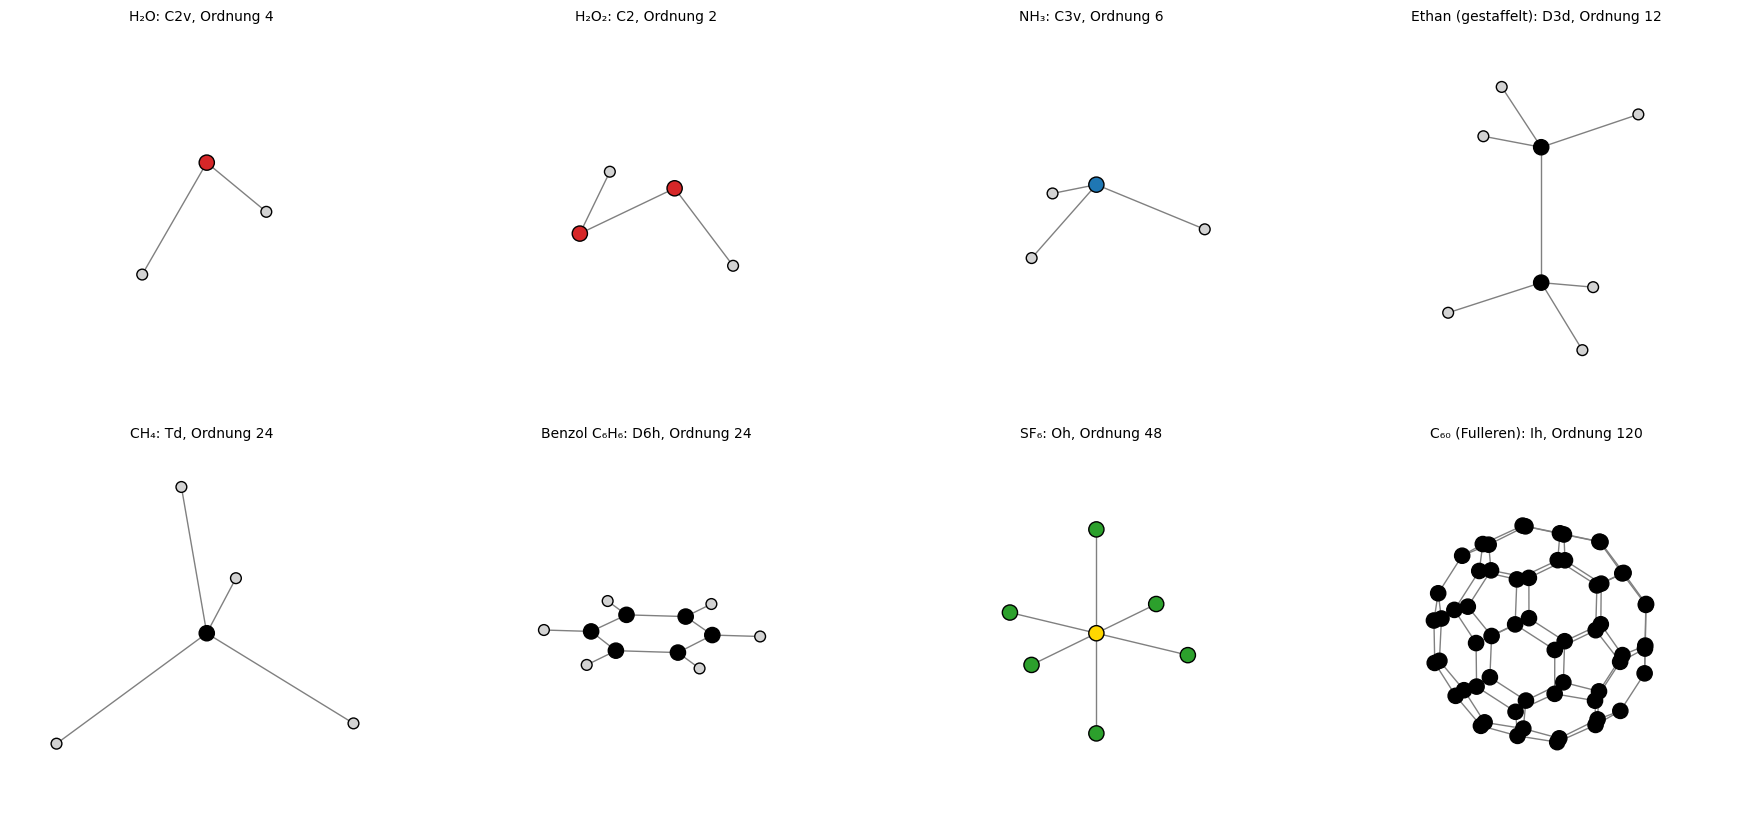

Cayley-Graph von A₅ (60 Ecken, 90 Kanten) isomorph zum C₆₀-Gerüst (60, 90): True
Molekül              Ordnung Drehungen Inversion Spiegel  Punktgruppe   chiral
H₂O                        4         2     False       2  C2v           nein
H₂O₂                       2         2     False       0  C2            ja
NH₃                        6         3     False       3  C3v           nein
Ethan (gestaffelt)        12         6      True       3  D3d           nein
CH₄                       24        12     False       6  Td            nein
Benzol C₆H₆               24        12      True       7  D6h           nein
SF₆                       48        24      True       9  Oh            nein
C₆₀ (Fulleren)           120        60      True      15  Ih            nein


In [15]:
groups.point_groups()

**15. Kristalle und Tapetengruppen**

Ein periodisches Gitter verträgt nur Drehungen, deren Matrix eine ganzzahlige Spur hat: 2 cos(2π/n) muss eine ganze Zahl sein. Dazu drei Tapeten mit demselben Motiv in drei Symmetriegruppen.

Nur n = 1, 2, 3, 4 und 6 sind möglich; eine fünfzählige Achse kann es in einem periodischen Kristall nicht geben, deshalb waren Quasikristalle 1984 eine Sensation. Die Tapeten zeigen dasselbe Motiv in drei der 17 Tapetengruppen der Ebene, etwa p4m mit den 8 Symmetrien des Quadrats; im Raum gibt es 230 Raumgruppen.

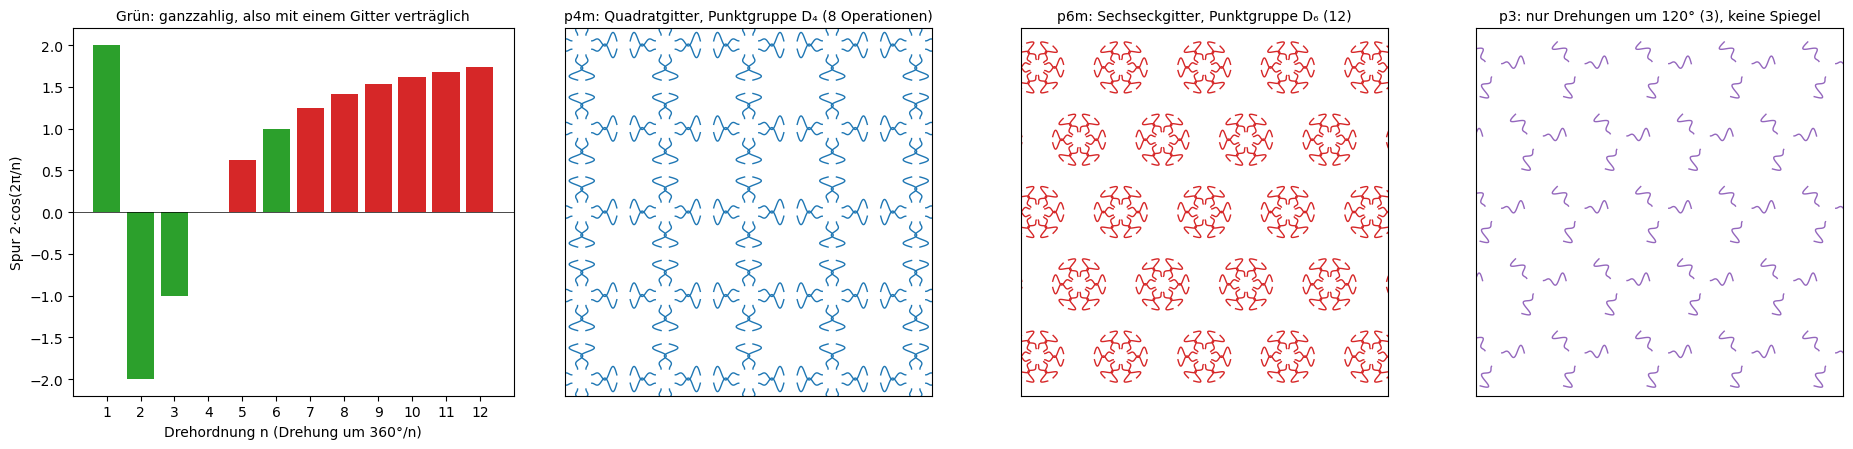

Mit einem Gitter verträgliche Drehordnungen: [1, 2, 3, 4, 6]  (2cos(2π/n) ganzzahlig)
Zum Beispiel n = 5: 2cos(72°) = 0.618034 = (√5 − 1)/2, nicht ganzzahlig → kein Kristall mit fünfzähliger Achse
Bekannte Anzahlen: 10 Punktgruppen und 17 Tapetengruppen in der Ebene; 32 Kristallklassen, 14 Bravais-Gitter und 230 Raumgruppen im Raum


In [16]:
groups.crystals()

**16. Gruppen in der Quanteninformation: Pauli und Clifford**

Die Pauli-Gruppe aus X, Y, Z und die Clifford-Gruppe der Gatter, die Pauli-Operatoren in Pauli-Operatoren überführen. Für ein Qubit wirkt die Clifford-Gruppe als Drehgruppe des Würfels.

Ohne Phasen hat die Clifford-Gruppe eines Qubits 24 Elemente mit denselben Klassen wie S₄. Mit mehr Qubits wächst sie wie 2^(2n²). Schaltkreise aus Clifford-Gattern lassen sich effizient klassisch simulieren (Gottesman-Knill); erst ein weiteres Gatter wie T macht sie universell.

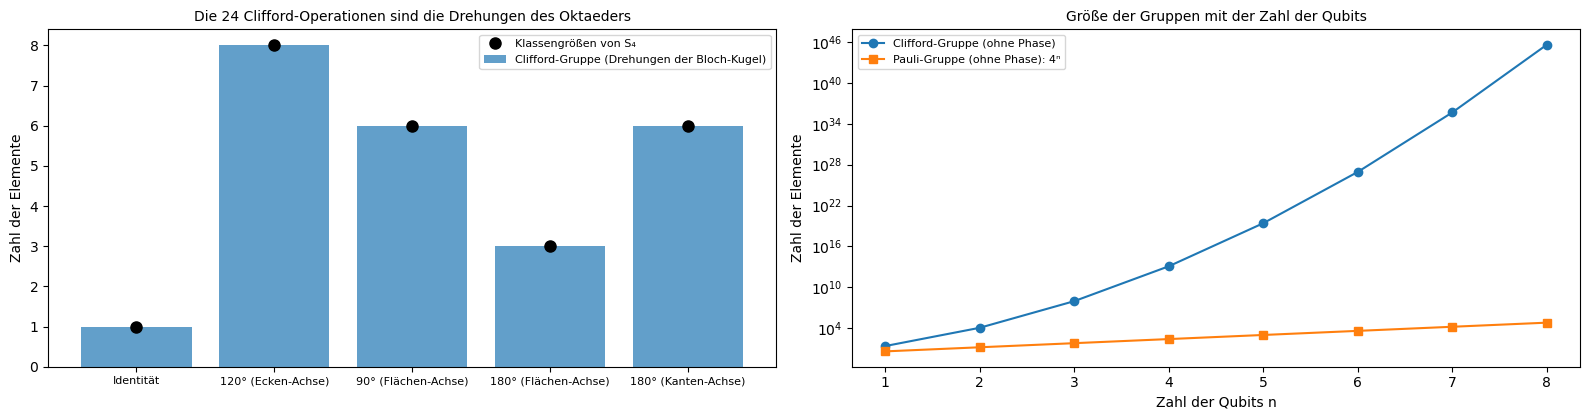

Pauli-Gruppe mit Phasen: 16 Elemente; Paare, die vertauschen: 160 von 256; ohne Phase bleibt ℤ₂ × ℤ₂ (4 Elemente)
Clifford-Gruppe eines Qubits ohne Phase: 24 Elemente;  Klassen nach Drehwinkel {'Identität': 1, '120° (Ecken-Achse)': 8, '90° (Flächen-Achse)': 6, '180° (Flächen-Achse)': 3, '180° (Kanten-Achse)': 6}
Größe der n-Qubit-Clifford-Gruppe (ohne Phase): n = 1: 24, n = 2: 11520, n = 3: 92897280


In [17]:
groups.pauli_clifford()

**17. Lie-Gruppen: zufällige Drehungen**

Die Drehungen des Raums bilden eine kontinuierliche Gruppe, SO(3). Zufällige Drehungen gleichmäßig zu ziehen (nach dem Haar-Maß) ist nicht dasselbe wie gleichverteilte Euler-Winkel; dazu die doppelte Überlagerung durch SU(2), die Gruppe der Spinoren.

Haar-zufällige Drehungen folgen der Dichte (1 − cos θ)/π: Drehungen um fast 180° sind am häufigsten, und der mittlere Winkel ist 2.204 (theoretisch π/2 + 2/π). Gleichverteilte Euler-Winkel weichen deutlich ab. In SU(2) kommt man erst nach 720° zurück, in SO(3) schon nach 360°.

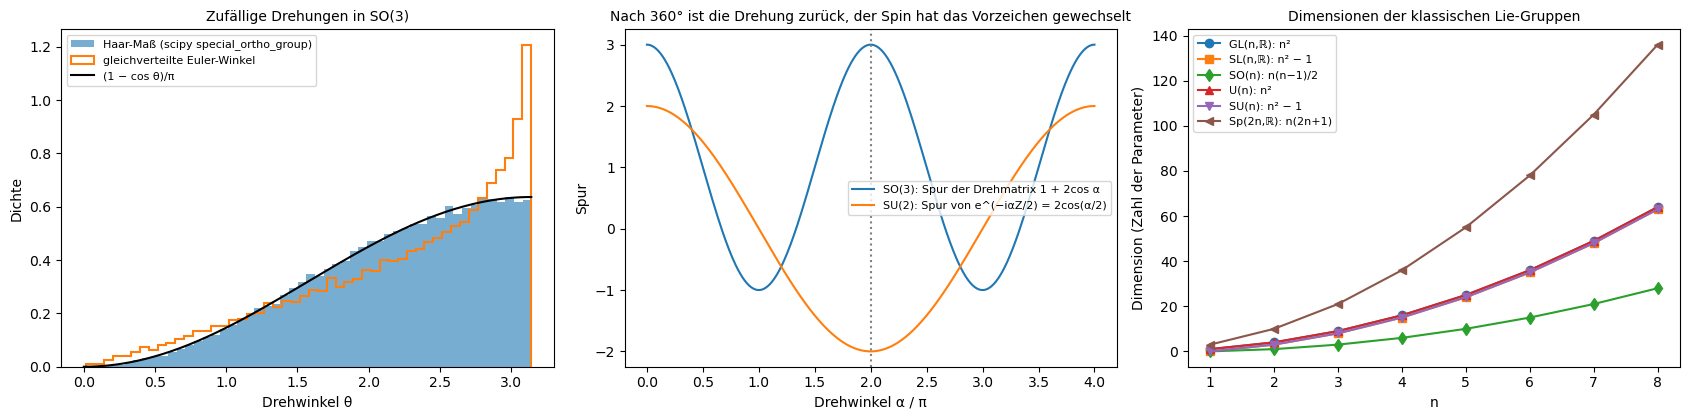

Mittlerer Drehwinkel: Haar 2.2044 (Theorie π/2 + 2/π = 2.2074), gleichverteilte Euler-Winkel 2.2347
Kolmogorov-Smirnov gegen (1 − cos θ)/π: Haar p = 0.15, Euler p = 3.7e-252
SU(2): Drehung um 2π ergibt [[-1.0, 0.0], [0.0, -1.0]] = −1, erst 4π ergibt +1;  Haar-zufällige SO(3)-Matrizen orthogonal mit Determinante 1: True


In [18]:
groups.rotations()

**18. Ringe und Körper: Werkzeuge**

In einem Ring kann man addieren, subtrahieren und multiplizieren wie in den ganzen Zahlen, in einem Körper zusätzlich durch alles außer 0 teilen. Zwei Verknüpfungen wirken zusammen, und daraus entstehen die Fragen der Zahlentheorie: Was sind Primzahlen, ist die Zerlegung eindeutig, welche Gleichungen sind lösbar? Bereitgestellt werden Gleichungssysteme und Rang über endlichen Körpern und die Multiplikation in einem Polynomring der Kryptographie.

Die Ausgabe meldet die Werkzeuge bereit; alles Übrige rechnet sympy.

In [19]:
rings.load()

Werkzeuge bereit: lineare Gleichungssysteme und Rang über 𝔽_p, Multiplikation in ℤ_q[x]/(xⁿ + 1)


**19. Die Restklassenringe ℤₙ**

Für n = 2 bis 60 werden in ℤₙ die Einheiten (mit Inversem), die Nullteiler (a·b = 0 mit a, b ≠ 0) und weitere besondere Elemente gezählt; dazu die Multiplikationstafeln von ℤ₁₂ und ℤ₁₃.

In ℤ₁₂ gibt es viele Nullteiler (2·6 = 0, 3·4 = 0) und nur 4 Einheiten; in ℤ₁₃ hat jedes Element außer 0 ein Inverses. ℤₙ ist genau dann ein Körper, wenn n eine Primzahl ist.

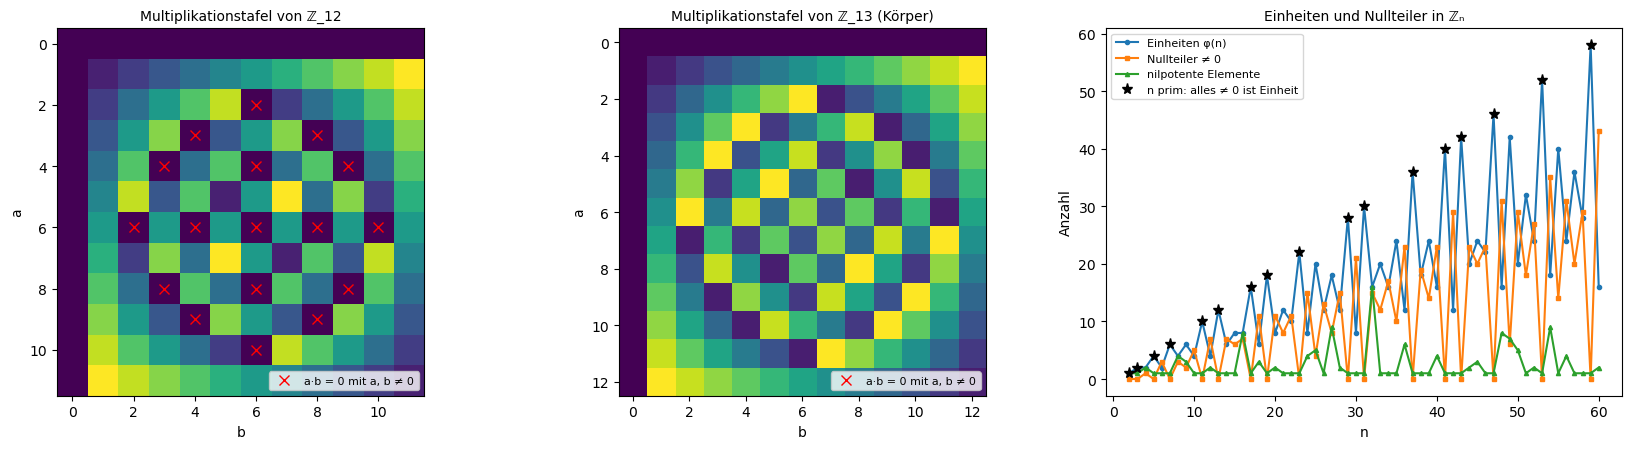

n  Einheiten  Nullteiler≠0  nilpotent  idempotent
12         4             7          2           4   (φ = 4, n/rad(n) = 2, 2^ω(n) = 4)
13        12             0          1           2   (φ = 12, n/rad(n) = 1, 2^ω(n) = 2)
30         8            21          1           8   (φ = 8, n/rad(n) = 1, 2^ω(n) = 8)
32        16            15         16           2   (φ = 16, n/rad(n) = 16, 2^ω(n) = 2)
60        16            43          2           8   (φ = 16, n/rad(n) = 2, 2^ω(n) = 8)
Jedes Element ≠ 0 ist Einheit oder Nullteiler: True;  ℤₙ ist Körper genau für n prim: True


In [20]:
rings.residue_rings()

**20. Euklid, Bézout und der chinesische Restsatz**

Der euklidische Algorithmus findet den größten gemeinsamen Teiler mit wenigen Schritten; der chinesische Restsatz sagt, dass ℤ₁₅ dasselbe ist wie ℤ₃ × ℤ₅.

Die Zahl der Schritte wächst nur logarithmisch, mit der Steigung 0.844 pro ln N (theoretisch 0.843); am längsten brauchen Paare aufeinanderfolgender Fibonacci-Zahlen. Jede der 15 Zahlen modulo 15 hat genau ein Paar von Resten modulo 3 und 5.

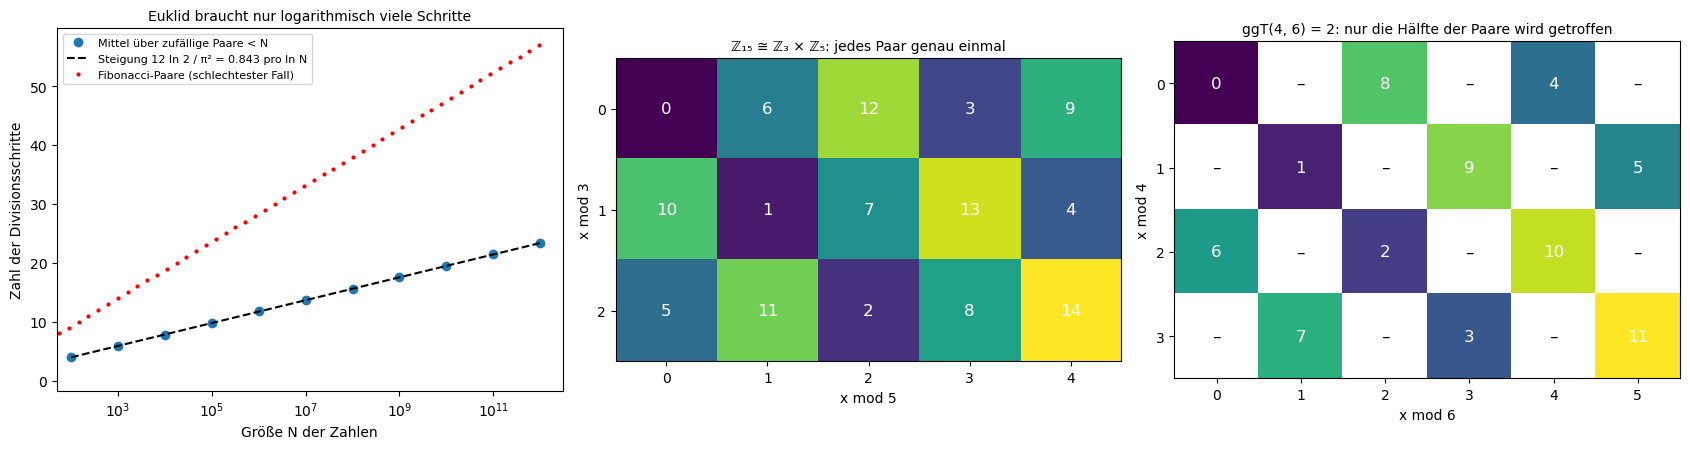

ggT(240, 46) = 2 = -9·240 + 47·46  (Bézout)
Inverses von 65537 modulo 2¹²⁷ − 1: 5192217631581220737344928932233215, Probe 65537·inv mod m = 1;  Schritte: 3
Gemessene Steigung der mittleren Schrittzahl: 0.844 pro ln N (Theorie 12 ln 2/π² = 0.843)
Schlechtester Fall: F₅₈ = 591286729879 und F₅₇ brauchen 56 Schritte (Lamé: höchstens 5 × Zahl der Dezimalstellen = 60)
Chinesischer Restsatz: x ≡ 2 (mod 3), x ≡ 3 (mod 5), x ≡ 2 (mod 7) → x = 23 (mod 105)


In [21]:
rings.euclid_crt()

**21. Gaußsche Zahlen und eindeutige Zerlegung**

Die Gaußschen Zahlen a + bi bilden einen Ring mit eindeutiger Zerlegung in Primfaktoren. Gezeigt sind ihre Primzahlen und die Klassenzahlen, die messen, wie weit die eindeutige Zerlegung in anderen Zahlbereichen verletzt ist.

Die Gaußschen Primzahlen haben die Symmetrie des Quadrats. Eine gewöhnliche Primzahl ist genau dann Summe zweier Quadrate, wenn sie bei Division durch 4 den Rest 1 lässt, etwa 13 = 2² + 3²: Sie zerfällt dann in zwei Gaußsche Primzahlen. Die Klassenzahlen streuen stark und wachsen im Mittel wie √D.

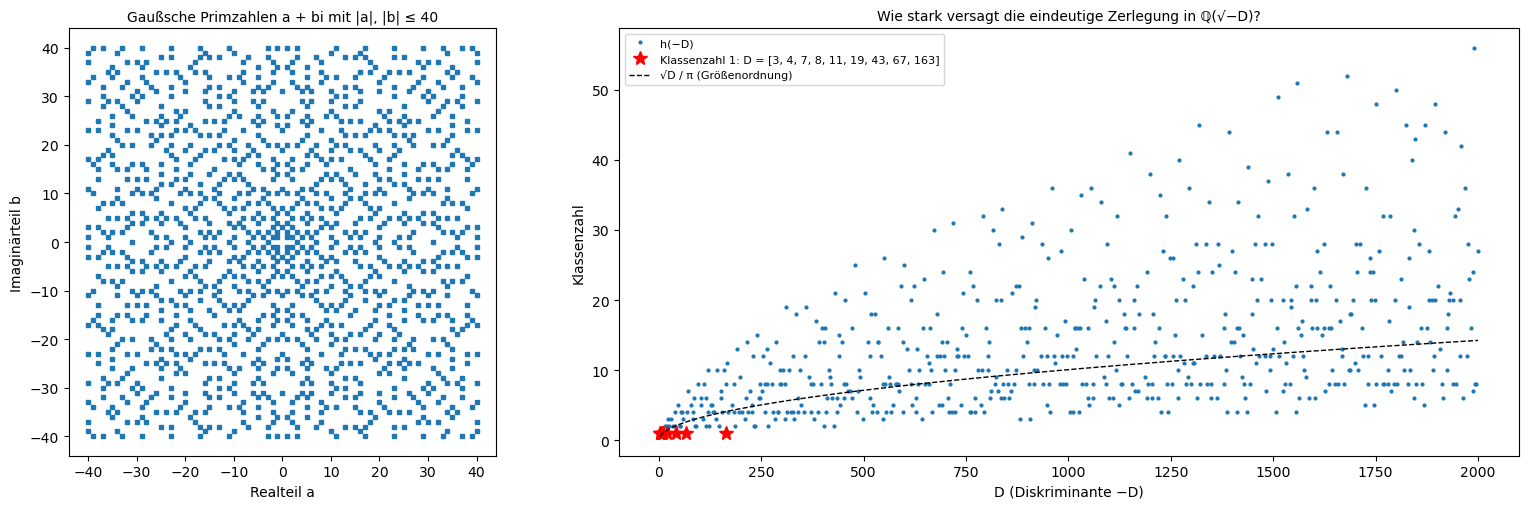

Fermat: Primzahl p < 1000 ist Summe zweier Quadrate genau dann, wenn p ≡ 1 mod 4: True;  z. B. 13 = 2² + 3², 97 = 4² + 9²
ℤ[√−5]: 6 = 2·3 = (1 + √−5)(1 − √−5); Normen 4·9 = 6·6; Elemente mit Norm 2 oder 3: keine → 2, 3, 1 ± √−5 sind unzerlegbar, die Zerlegung ist nicht eindeutig
Klassenzahlen: h(−4) = 1 (ℤ[i]), h(−20) = 2 (ℤ[√−5]), h(−163) = 1;  Klassenzahl 1 für D ≤ 2000: [3, 4, 7, 8, 11, 19, 43, 67, 163]


In [22]:
rings.gaussian_integers()

**22. Irreduzible Polynome über endlichen Körpern**

Polynome, die sich nicht in kleinere zerlegen lassen, spielen die Rolle von Primzahlen. Gezählt werden sie über den Körpern mit 2, 3 und 5 Elementen und verglichen mit der Formel von Gauß.

Die Zählung trifft die Formel überall: Über 𝔽₂ gibt es 99 irreduzible Polynome vom Grad 10, ungefähr 2¹⁰/10. x⁴ + 1 zerfällt modulo jeder Primzahl, obwohl es über den rationalen Zahlen irreduzibel ist.

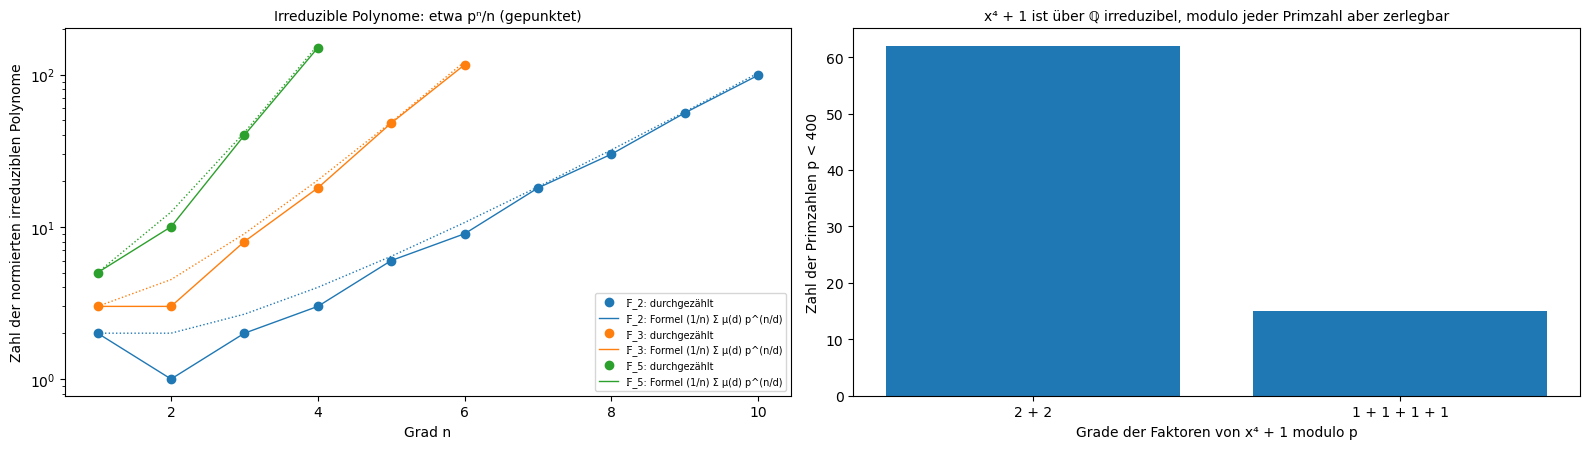

𝔽_2: durchgezählt [2, 1, 2, 3, 6, 9, 18, 30, 56, 99];  Formel stimmt: True
𝔽_3: durchgezählt [3, 3, 8, 18, 48, 116];  Formel stimmt: True
𝔽_5: durchgezählt [5, 10, 40, 150];  Formel stimmt: True
x⁴ + 1 über ℚ irreduzibel: True;  Zerlegungstypen modulo p < 400: (2, 2): 62, (1, 1, 1, 1): 15;  irreduzibel modulo einer ungeraden Primzahl: False
Beispiele: x⁴ + 1 ≡ x**2 + 3*x + 1 · x**2 - 3*x + 1 (mod 7), ≡ x + 2 · x + 8 · x - 8 · x - 2 (mod 17)


In [23]:
rings.irreducible_polys()

**23. Endliche Körper: 𝔽₁₆ ist nicht ℤ₁₆**

Der Körper mit 16 Elementen besteht aus Polynomen vom Grad unter 4 über 𝔽₂, gerechnet modulo x⁴ + x + 1. Verglichen werden die Multiplikationstafeln von ℤ₁₆ und 𝔽₁₆.

ℤ₁₆ hat 17 Paare von Nullteilern, 𝔽₁₆ keine: Jede Zeile außer der ersten enthält alle Elemente. Die Potenzen von x durchlaufen alle 15 Elemente außer 0; die multiplikative Gruppe ist zyklisch.

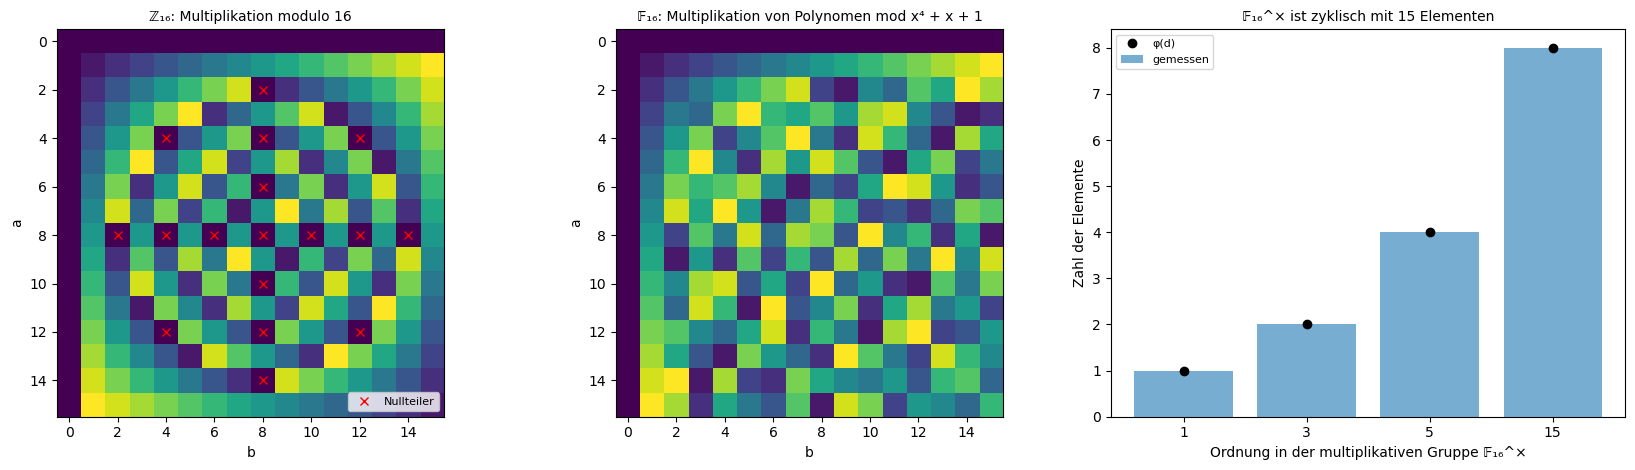

Potenzen von x in 𝔽₁₆: x^0 = 1, x^1 = x, x^2 = x², x^3 = x³, x^4 = x + 1, x^5 = x² + x, x^6 = x³ + x², x^7 = x³ + x + 1, …
x hat Ordnung 15 (primitives Element); alle 15 Elemente ≠ 0 kommen als Potenz vor: True
Nullteiler: ℤ₁₆ hat 17 Paare (a, b ≠ 0) mit a·b = 0, 𝔽₁₆ hat 0;  Charakteristik 2: a + a = 0 für alle a
Frobenius a ↦ a² ist bijektiv: True;  Teilkörper 𝔽₄ = {a : a⁴ = a} = ['0', '1', 'x² + x', 'x² + x + 1']


In [24]:
rings.finite_fields()

**24. Reed-Solomon-Codes**

Eine Nachricht wird zu den Koeffizienten eines Polynoms, gesendet werden seine Werte an vielen Stellen. Weil ein Polynom vom Grad k durch k + 1 Werte festliegt, lassen sich falsche Werte erkennen und reparieren. So schützen CDs, QR-Codes und Raumsonden ihre Daten.

Mit Mindestabstand 11 werden bis zu 5 Fehler in jedem Versuch repariert; ab 6 Fehlern erkennt der Decoder, dass er nicht reparieren kann, und dekodiert nie falsch.

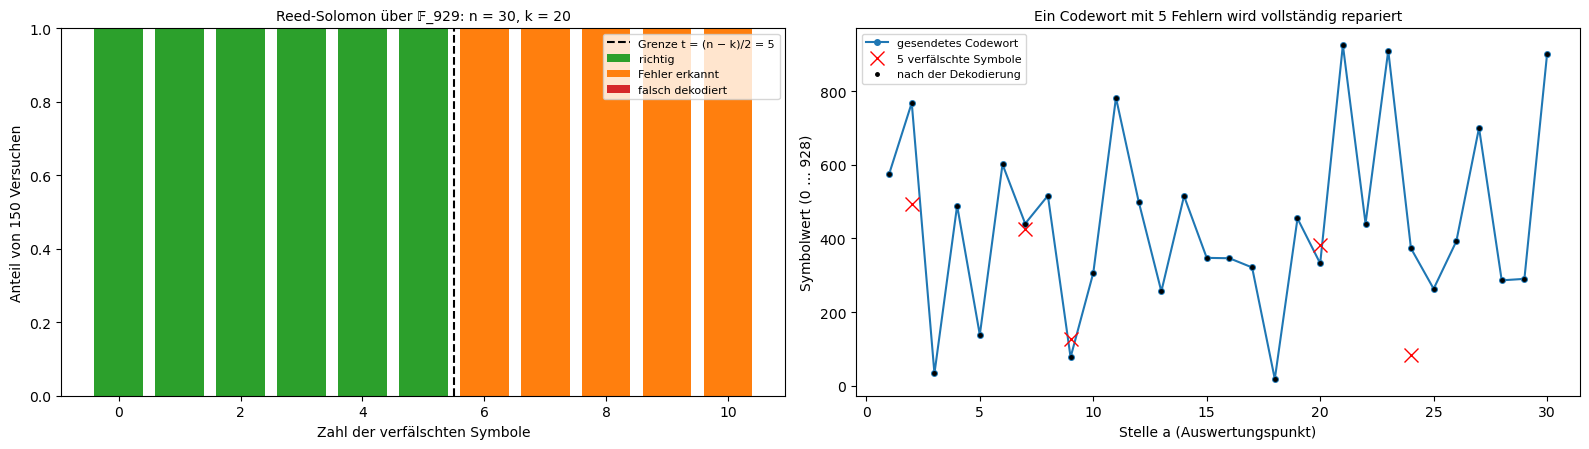

Parameter: n = 30, k = 20, Mindestabstand n − k + 1 = 11 (Singleton-Schranke erreicht), korrigiert t = 5 Fehler
 0 Fehler: richtig 150, Fehler erkannt 0, falsch dekodiert 0
 3 Fehler: richtig 150, Fehler erkannt 0, falsch dekodiert 0
 5 Fehler: richtig 150, Fehler erkannt 0, falsch dekodiert 0
 6 Fehler: richtig 0, Fehler erkannt 150, falsch dekodiert 0
 8 Fehler: richtig 0, Fehler erkannt 150, falsch dekodiert 0
10 Fehler: richtig 0, Fehler erkannt 150, falsch dekodiert 0


In [25]:
rings.reed_solomon()

**25. Gröbner-Basen**

Eine Gröbner-Basis formt ein System von Polynomgleichungen so um, dass die letzte Gleichung nur noch eine Unbekannte enthält, wie die Gauß-Elimination für lineare Systeme. Beispiele: der Schnitt von Kreis und Hyperbel und die Stellungen eines Roboterarms.

Kreis und Hyperbel schneiden sich in vier Punkten; das letzte Polynom der Basis hängt nur von y ab. Der Arm erreicht seinen Zielpunkt in zwei Stellungen, Ellbogen oben und unten.

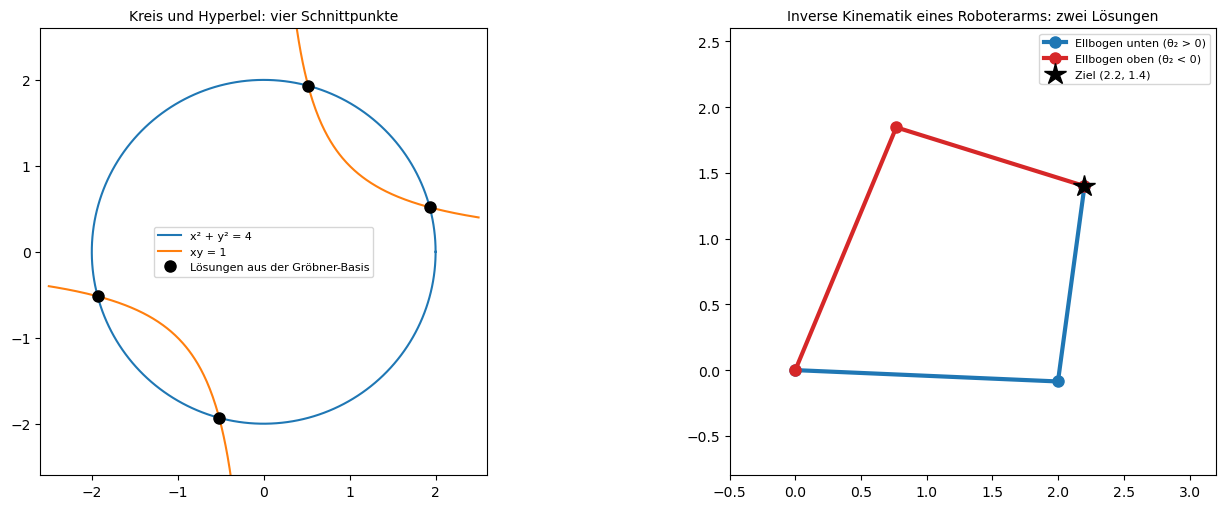

Gröbner-Basis (lex, x > y) für {x² + y² − 4, xy − 1}: ['x + y**3 - 4*y', 'y**4 - 4*y**2 + 1']
Letztes Polynom hängt nur von y ab; seine Nullstellen y = [-1.9319, -0.5176, 0.5176, 1.9319];  Probe x² + y² = [4.0, 4.0, 4.0, 4.0]
Gröbner-Basis des Roboterarms (lex, c1 > s1 > s2 > c2):
    c1 - 21*s2/68 - 1881/2720
    s1 + 33*s2/68 - 1197/2720
    s2**2 - 14279/14400
    c2 - 11/120
Daraus c2 = 0.0917, s2 = ±0.9958;  Winkel (θ₁, θ₂) in Grad: (-2.5, 84.7), (67.4, -84.7)


In [26]:
rings.groebner_bases()

**26. Körpererweiterungen und Zirkel und Lineal**

Mit Zirkel und Lineal lassen sich nur Zahlen konstruieren, deren Minimalpolynom einen Grad hat, der eine Zweierpotenz ist. Das entscheidet, welche regelmäßigen Vielecke konstruierbar sind.

Das Siebeneck und das Neuneck haben Grad 3 und sind nicht konstruierbar, das Siebzehneck hat Grad 8 und ist es, wie Gauß 1796 fand. ∛2 hat Grad 3: Die Würfelverdopplung ist unmöglich, ebenso die Dreiteilung des Winkels von 60°.

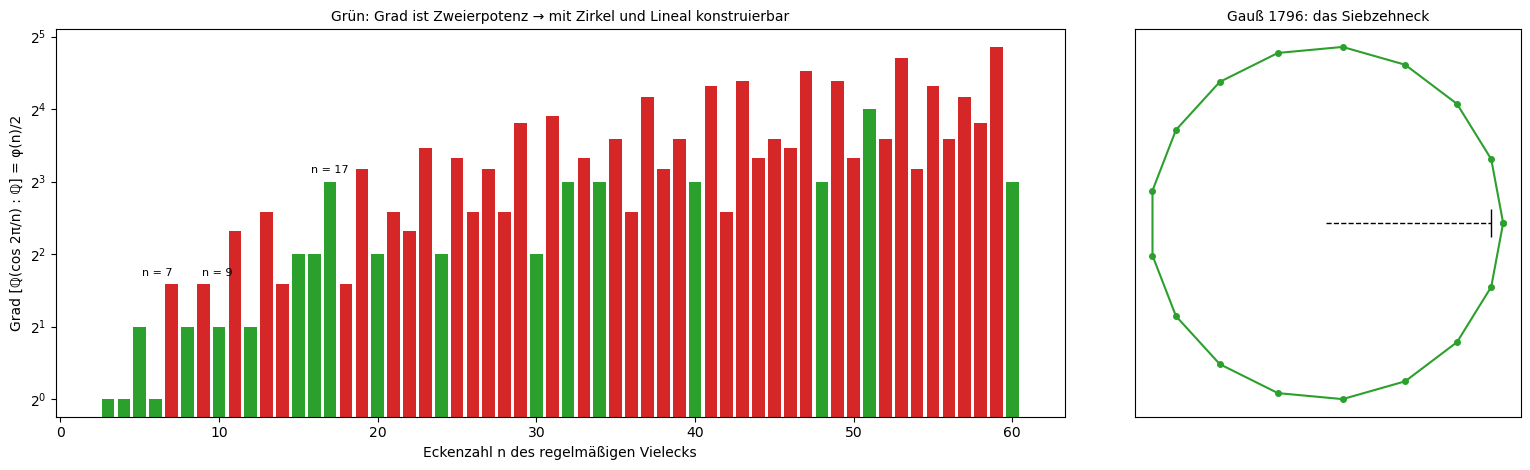

Konstruierbare Vielecke bis 60: [3, 4, 5, 6, 8, 10, 12, 15, 16, 17, 20, 24, 30, 32, 34, 40, 48, 51, 60]
Gradformel φ(n)/2 gegen Minimalpolynom von cos(2π/n): {5: (2, 2), 7: (3, 3), 9: (3, 3), 17: (8, 8)}
√2 + √3                         : Minimalpolynom x**4 - 10*x**2 + 1, Grad 4 → konstruierbar
∛2 (Würfelverdopplung)          : Minimalpolynom x**3 - 2, Grad 3 → nicht konstruierbar
cos 20° (Dreiteilung von 60°)   : Minimalpolynom 8*x**3 - 6*x - 1, Grad 3 → nicht konstruierbar
cos(2π/7) (Siebeneck)           : Minimalpolynom 8*x**3 + 4*x**2 - 4*x - 1, Grad 3 → nicht konstruierbar
cos(2π/17) (Siebzehneck)        : Minimalpolynom 256*x**8 + 128*x**7 - 448*x**6 - 192*x**5 + 240*x**4 + 80*x**3 - 40*x**2 - 8*x + 1, Grad 8 → konstruierbar
Gauß' Formel für cos(2π/17) mit verschachtelten Quadratwurzeln: 0.932472229404356, direkt 0.932472229404356


In [27]:
rings.field_extensions()

**27. Galois-Gruppen und die Zerlegung modulo Primzahlen**

Die Galois-Gruppe eines Polynoms vertauscht seine Nullstellen. Modulo verschiedener Primzahlen zerfällt das Polynom unterschiedlich, und nach Tschebotarjow kommt jedes Zerfallsmuster so oft vor wie die zugehörigen Elemente der Galois-Gruppe.

Für x³ − 2 (Galois-Gruppe S₃) und x⁵ − x − 1 (S₅) treffen die Anteile der Zerfallsmuster die Anteile der Zyklentypen; die größte Abweichung über fünf Polynome ist 0.012. Die Primzahlen „zählen“ die Gruppe.

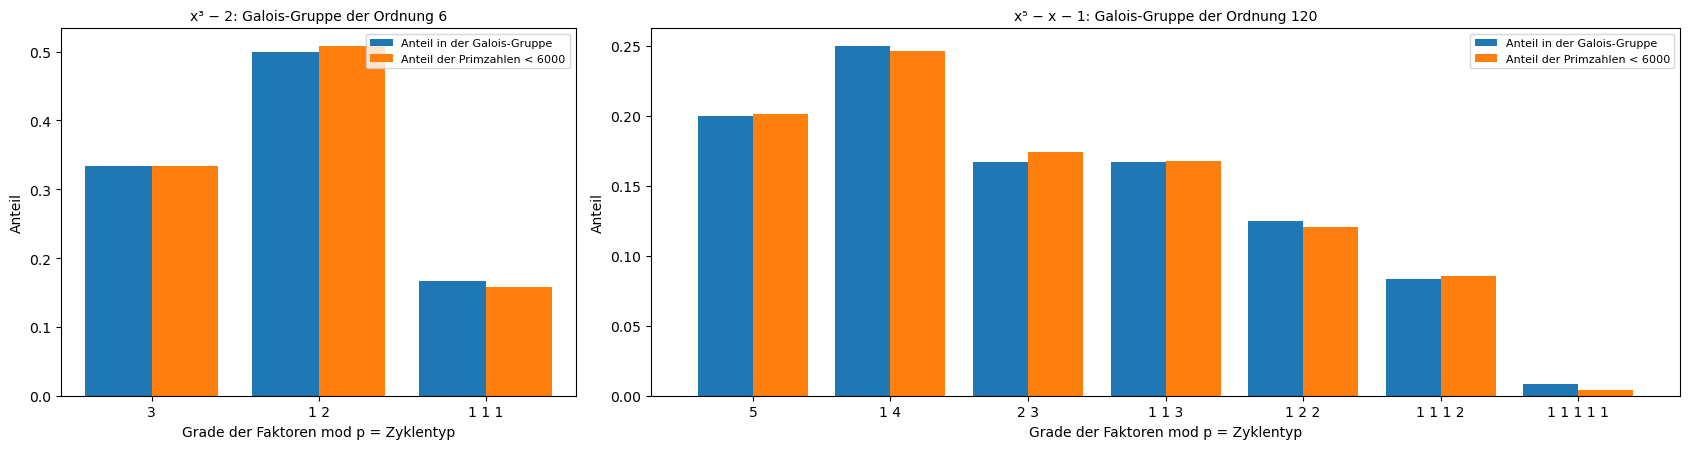

x³ − 2        : Galois-Gruppe Ordnung   6, auflösbar True;  Zyklentypen {(1, 1, 1): 1, (1, 2): 3, (3,): 2};  größte Abweichung der Primzahl-Anteile 0.009
x⁴ − 10x² + 1 : Galois-Gruppe Ordnung   4, auflösbar True;  Zyklentypen {(1, 1, 1, 1): 1, (2, 2): 3};  größte Abweichung der Primzahl-Anteile 0.008
x⁴ + 1        : Galois-Gruppe Ordnung   4, auflösbar True;  Zyklentypen {(1, 1, 1, 1): 1, (2, 2): 3};  größte Abweichung der Primzahl-Anteile 0.012
x⁵ − x − 1    : Galois-Gruppe Ordnung 120, auflösbar False;  Zyklentypen {(1, 1, 1, 1, 1): 1, (1, 1, 1, 2): 10, (1, 1, 3): 20, (1, 2, 2): 15, (1, 4): 30, (2, 3): 20, (5,): 24};  größte Abweichung der Primzahl-Anteile 0.008
x⁵ − 2        : Galois-Gruppe Ordnung  20, auflösbar True;  Zyklentypen {(1, 1, 1, 1, 1): 1, (1, 2, 2): 5, (1, 4): 10, (5,): 4};  größte Abweichung der Primzahl-Anteile 0.008
x⁵ − x − 1: Anteil der Primzahlen, modulo derer das Polynom irreduzibel bleibt: 0.201 (Theorie 24/120 = 0.200)


In [28]:
rings.galois()

**28. p-adische Zahlen und das Henselsche Lemma**

In den p-adischen Zahlen sind Zahlen nahe beieinander, wenn ihre Differenz durch eine hohe Potenz von p teilbar ist. Das Newton-Verfahren findet dort Wurzeln mit jeder Ziffer genauer (Hensel).

Für √2 in den 7-adischen Zahlen verdoppelt sich die Genauigkeit mit jedem Schritt. √−1 existiert 5-adisch, aber nicht 3-adisch. Die Reihe 1 + 2 + 4 + 8 + … konvergiert 2-adisch gegen −1.

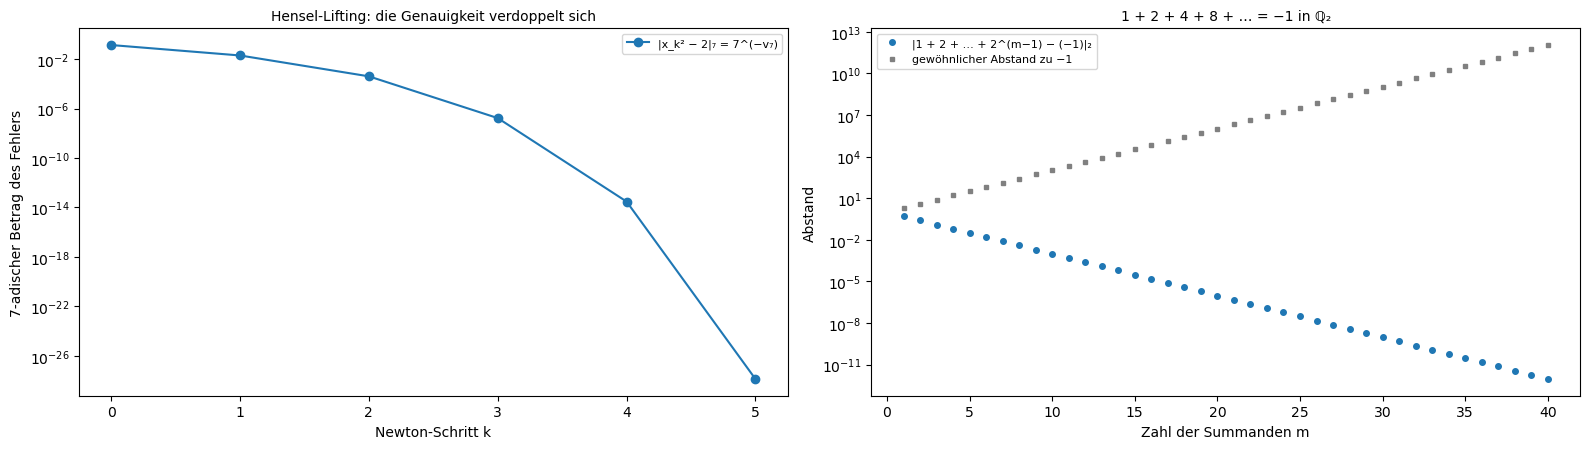

Hensel für x² = 2 in ℤ₇: (Schritt, Modul, v₇(x² − 2)) = [(0, '7^1', 1), (1, '7^2', 2), (2, '7^4', 4), (3, '7^8', 8), (4, '7^16', 16), (5, '7^32', 33)]
√2 in ℤ₇, letzte Stellen zuerst: …64112011266421216213 (Basis 7);  Probe: (√2)² − 2 durch 7^40 teilbar: True
√−1 existiert in ℤ₅ (2² ≡ −1 mod 5): Lösungen modulo 5²⁰: [15613890344818, 79753541295807];  in ℤ₃ nicht: True


In [29]:
rings.padic()

**29. Quadratische Reste und Reziprozität**

Welche Zahlen sind modulo einer Primzahl Quadrate? Das quadratische Reziprozitätsgesetz verbindet die Antwort für p modulo q mit der für q modulo p; Gauß bewies es achtmal.

Modulo 101 sind genau 50 der 100 Zahlen Quadrate. Das Gesetz gilt für alle 2926 Paare ungerader Primzahlen unter 400. Die quadratische Gauß-Summe hat für jede Primzahl genau den Betrag √p.

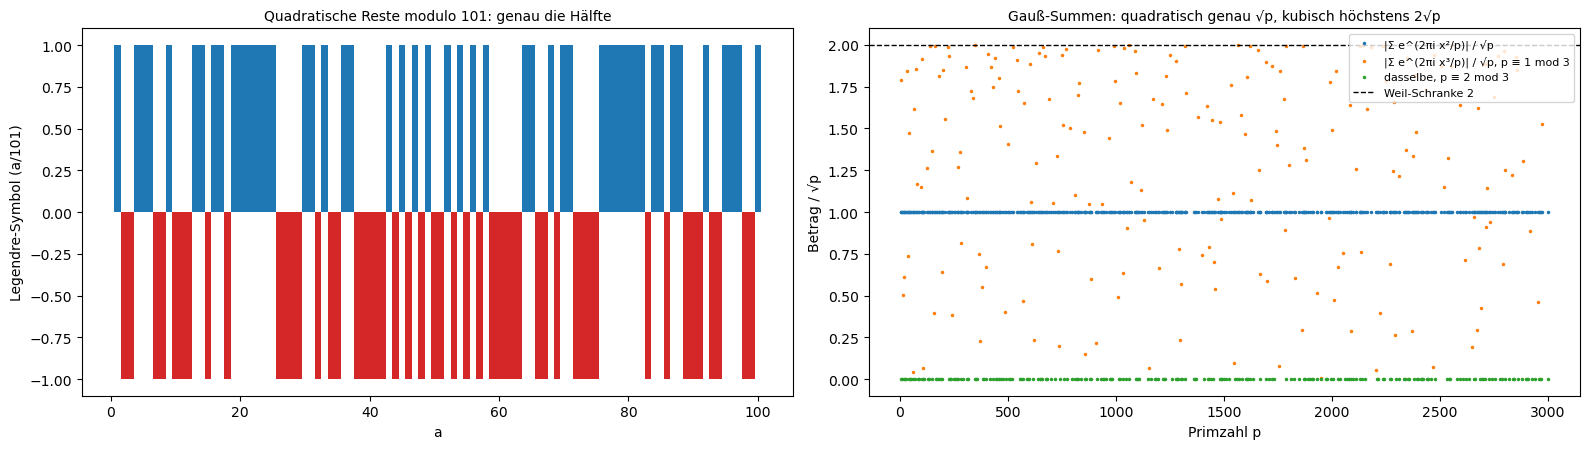

Quadratisches Reziprozitätsgesetz für alle 2926 Paare ungerader Primzahlen < 400: True
Quadratische Reste mod 101: 50 von 100;  (−1/101) = 1 (101 ≡ 1 mod 4), (2/101) = -1 (101 ≡ 5 mod 8)
Quadratische Gauß-Summe / √p: min 1.000000, max 1.000000;  kubisch: p ≡ 2 mod 3 max 6.6e-15, p ≡ 1 mod 3 max 1.9997 (≤ 2)


In [30]:
rings.reciprocity()

**30. Nichtkommutative Ringe: Matrizen und Quaternionen**

Im Ring der 2×2-Matrizen über 𝔽₂ hängt das Produkt von der Reihenfolge ab; die Quaternionen sind ein Körper, in dem das ebenfalls so ist.

Nur 88 der 256 Paare von Matrizen vertauschen; 6 Matrizen sind invertierbar, 9 Nullteiler. Eine große Zufallsmatrix über 𝔽₂ ist nur zu 28.9 % invertierbar. Quaternionen beschreiben Drehungen im Raum ohne die Probleme der Euler-Winkel.

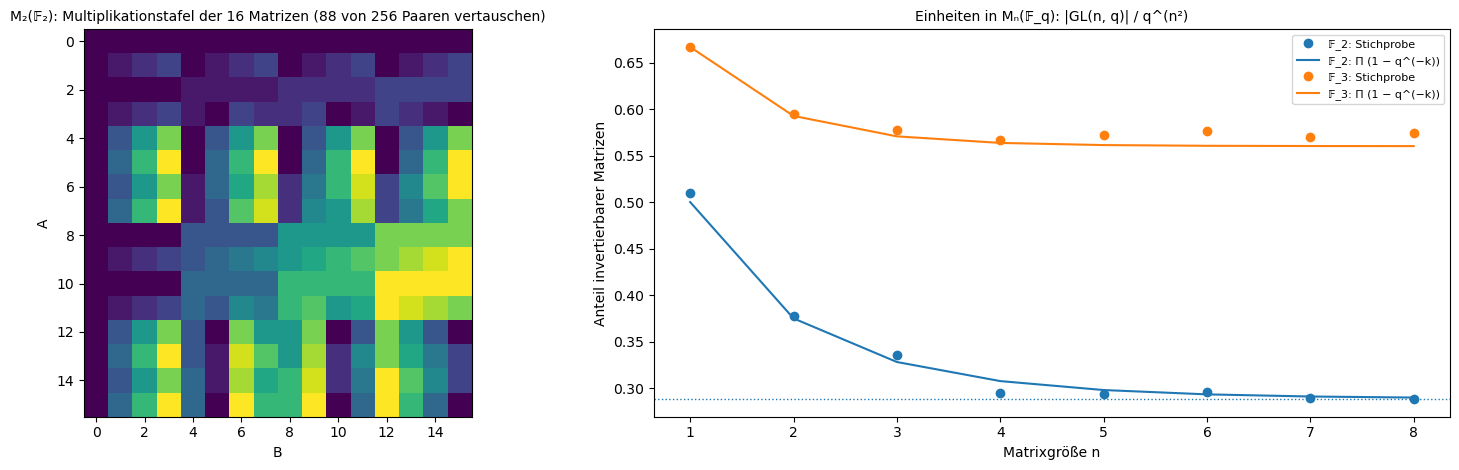

M₂(𝔽₂): 6 Einheiten (= |GL(2,2)| = 6 ≅ S₃), 9 Nullteiler ≠ 0, 4 nilpotente (A² = 0), 8 idempotente (A² = A)
Quaternionen: ij = [0 0 0 1], ji = [ 0  0  0 -1] (nicht kommutativ), i² = j² = k² = ijk = -1
Norm ist multiplikativ: |ab| = 6.169481 = |a|·|b| = 6.169481 → jedes q ≠ 0 hat das Inverse q*/|q|² (Schiefkörper)
Anteil invertierbarer n×n-Matrizen über 𝔽₂ für n → ∞: 0.2888


In [31]:
rings.quaternions()

**31. Moduln über ℤ: Smith-Normalform und Homologie**

Die Smith-Normalform bringt eine ganzzahlige Matrix auf Diagonalgestalt; daraus folgt die Struktur einer endlichen abelschen Gruppe und, angewendet auf Randmatrizen, die Löcher einer Fläche (Homologie).

Die Beispielmatrix ergibt ℤ₂ × ℤ₂ × ℤ₁₅₆ mit 624 Elementen. Kugel, Torus und projektive Ebene haben die Betti-Zahlen (1, 0, 1), (1, 2, 1) und (1, 0, 0); die Torsion ℤ₂ der projektiven Ebene sieht man nur über ℤ.

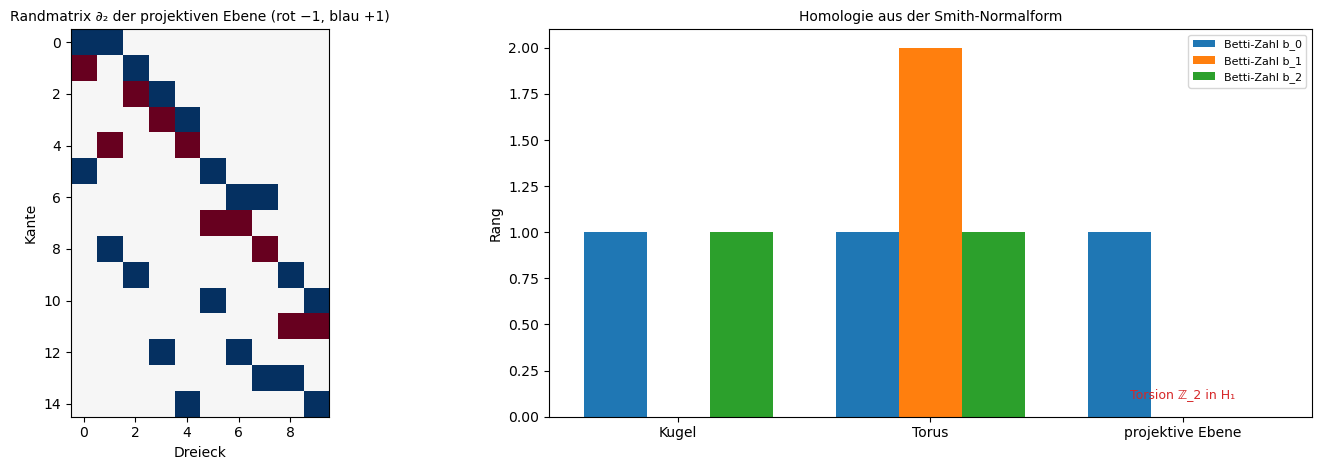

Relationenmatrix A = [[2, 4, 4], [-6, 6, 12], [10, 4, 16]]: Smith-Normalform diag(2, 2, 156) → ℤ³/Zeilen(A) ≅ ℤ₂ × ℤ₂ × ℤ₁₅₆, Ordnung 624 = |det A| = 624
Kugel (Tetraederrand)       : E − K + F = 4 − 6 + 4 = 2;  Betti (b₀, b₁, b₂) = (1, 0, 1);  Torsion in H₁: keine
Torus (7 Ecken)             : E − K + F = 7 − 21 + 14 = 0;  Betti (b₀, b₁, b₂) = (1, 2, 1);  Torsion in H₁: keine
projektive Ebene (6 Ecken)  : E − K + F = 6 − 15 + 10 = 1;  Betti (b₀, b₁, b₂) = (1, 0, 0);  Torsion in H₁: [2]


In [32]:
rings.smith_form()

**32. Polynomringe in der Post-Quanten-Kryptographie**

Ein vereinfachtes Verfahren nach Art von Kyber rechnet im Polynomring ℤ_q[x]/(xⁿ + 1). Die Sicherheit beruht auf kleinem Rauschen, das Quantenrechner nach heutigem Wissen nicht entfernen können.

Nach dem Entschlüsseln bleibt das Rauschen weit unter der Grenze q/4; kein einziges von 5120 Bits ist falsch. Mit größerem Rauschen steigt die Fehlerrate, bis 28 %: Das Rauschen muss groß genug für die Sicherheit und klein genug für das Entschlüsseln sein.

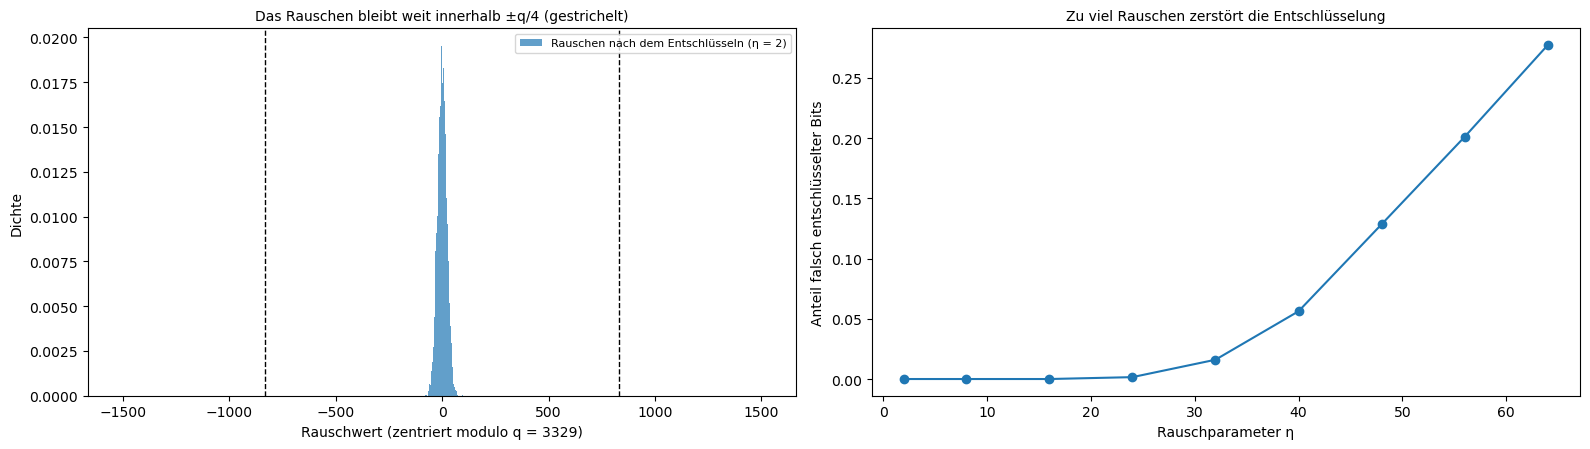

Ring ℤ_3329[x]/(x^256 + 1): 256-Bit-Nachrichten mit η = 2: Bitfehlerrate 0.0000;  Rauschen: Standardabweichung 21.8, größter Betrag 92 (Grenze q/4 = 832)
Bitfehlerrate gegen η: η = 2: 0.0000, η = 8: 0.0000, η = 16: 0.0000, η = 24: 0.0016, η = 32: 0.0160, η = 40: 0.0563, η = 48: 0.1285, η = 56: 0.2012, η = 64: 0.2773
Negazyklische NTT mit q = 7681, ψ = 62 (ψ²⁵⁶ ≡ −1): Produkt über NTT = Produkt direkt: True


In [33]:
rings.post_quantum()

**33. Eigenwerte: Eigenvektoren sehen**

Eine Matrix A bildet Vektoren auf Vektoren ab und verdreht und streckt sie dabei. Ein Eigenvektor behält seine Richtung, A v = λ v; der Eigenwert λ sagt, um welchen Faktor er gestreckt wird, bei komplexem λ dreht A eine ganze Ebene. Hat man genug Eigenvektoren, nimmt man sie als Koordinatensystem, und die Matrix wird diagonal: Jede Richtung wird nur gestreckt. Gezeigt wird, was vier 2×2-Matrizen mit dem Einheitskreis machen.

Bei der symmetrischen Matrix stehen die Eigenrichtungen senkrecht und sind die Achsen der Ellipse. Bei der nicht symmetrischen sind sie schief, bei der Scherung gibt es nur eine (doppelter Eigenwert 1, aber nur ein Eigenvektor), und die Drehstreckung hat keine reellen Eigenvektoren, ihre Eigenwerte sind komplex.

symmetrisch: det(A − λI) = λ^2 - 4·λ + 3
    λ = 1 (algebraisch 1, geometrisch 1, Eigenvektor (-1, 1))
    λ = 3 (algebraisch 1, geometrisch 1, Eigenvektor (1, 1))
nicht symmetrisch: det(A − λI) = λ^2 - 3·λ + 2
    λ = 1 (algebraisch 1, geometrisch 1, Eigenvektor (1, 0))
    λ = 2 (algebraisch 1, geometrisch 1, Eigenvektor (3/2, 1))
Scherung: det(A − λI) = λ^2 - 2·λ + 1
    λ = 1 (algebraisch 2, geometrisch 1, Eigenvektor (1, 0))
Drehstreckung (60°, Faktor 0.9): det(A − λI) = λ^2 - 9·λ/10 + 81/100
    λ = 9/20 - 9·sqrt(3)·i/20 (algebraisch 1, geometrisch 1, Eigenvektor (-i, 1))
    λ = 9/20 + 9·sqrt(3)·i/20 (algebraisch 1, geometrisch 1, Eigenvektor (i, 1))


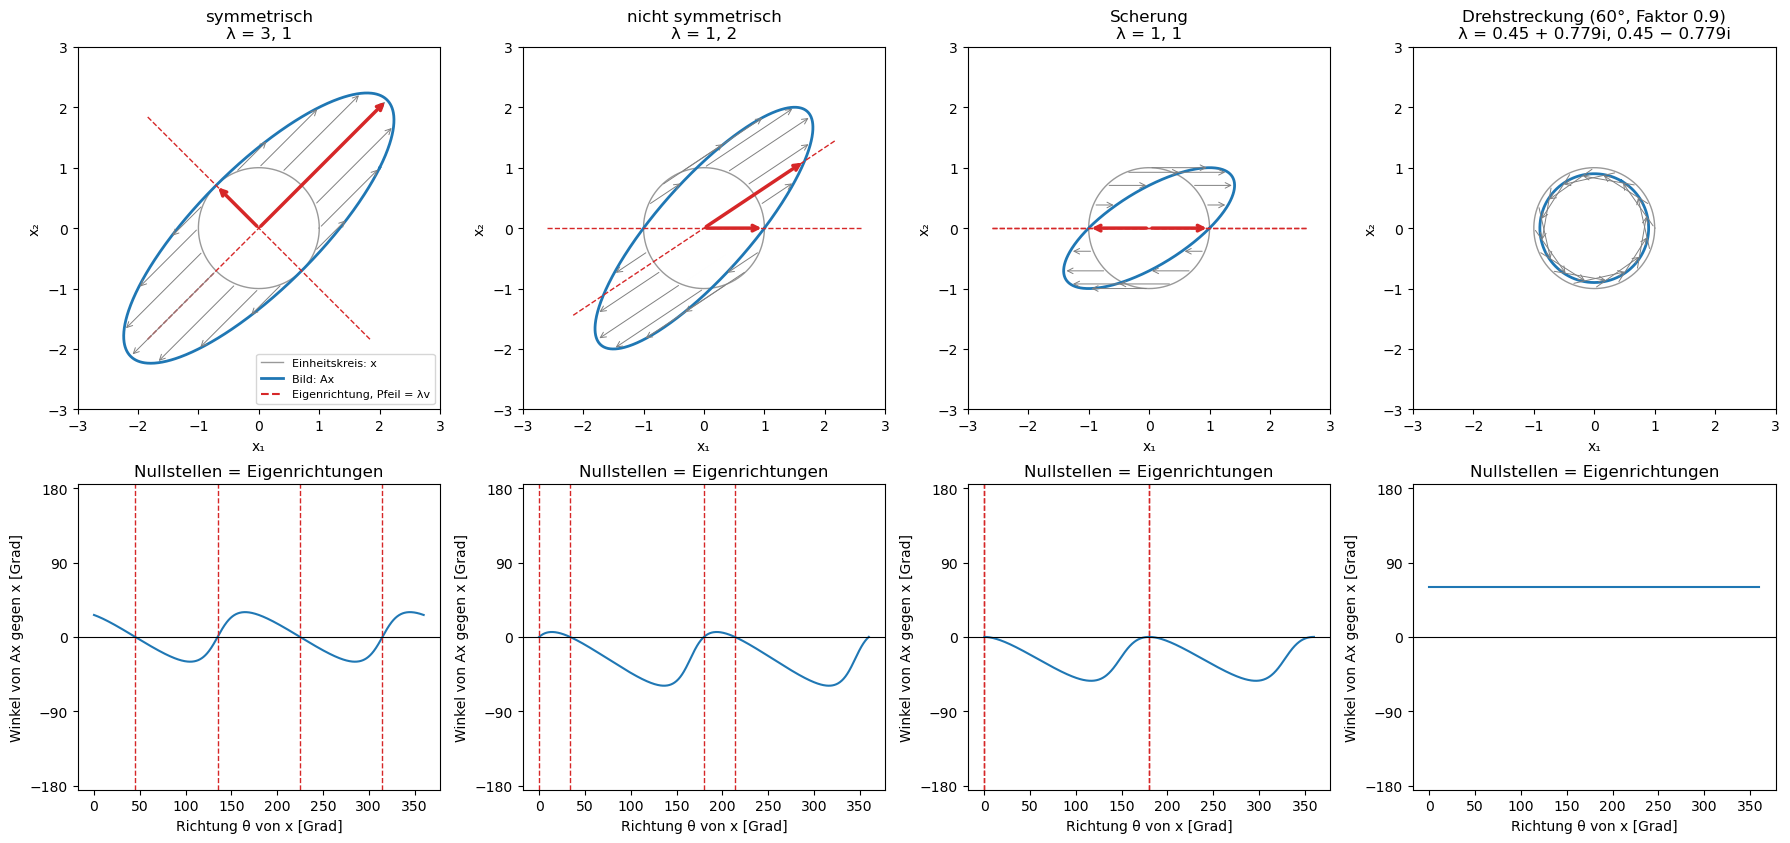

In [34]:
eigen.see_eigenvectors()

**34. Potenzen: wer auf lange Sicht gewinnt**

Wendet man eine Matrix oft an, setzt sich der größte Eigenwert durch; wie schnell, sagt der zweitgrößte. Beispiele: die Fibonacci-Zahlen und Markov-Ketten, die sich einer stationären Verteilung nähern.

Die 30. Potenz der Fibonacci-Matrix enthält F₃₀ = 832 040, und φ³⁰/√5 trifft diese Zahl auf sechs Nachkommastellen, weil der zweite Eigenwert −1/φ verschwindet. Jede Markov-Kette nähert sich ihrem Gleichgewicht mit einer Geraden im logarithmischen Bild, deren Steigung der zweite Eigenwert ist.

Fibonacci: [[1, 1], [1, 0]]^30 = [[1346269, 832040], [832040, 514229]]  Eigenwerte [1/2 - sqrt(5)/2, 1/2 + sqrt(5)/2]
  F_30 = 832040,  φ^30/√5 = 832040.000000
gut gemischt: Eigenwerte 1, -0.213, 0.173, -0.11, 0.0221 + 0.0674i, 0.0221 − 0.0674i
    π = [0.1447 0.1615 0.1693 0.1801 0.1846 0.1598], |λ₂| = 0.2133, gemessene Rate von ‖p_k − π‖₁: 0.2042; Abstand nach 20 Schritten 1.8e-14, nach 79 Schritten 6.7e-16
zwei Gruppen: Eigenwerte 1, 0.983, 0.0751, -0.0538, 0.00476 + 0.0224i, 0.00476 − 0.0224i
    π = [0.1564 0.208  0.1712 0.1618 0.1599 0.1427], |λ₂| = 0.9825, gemessene Rate von ‖p_k − π‖₁: 0.9825; Abstand nach 20 Schritten 6.5e-01, nach 79 Schritten 2.3e-01
zwei Gruppen + Dämpfung 0.85: Eigenwerte 1, 0.835, 0.0638, -0.0457, 0.00405 + 0.019i, 0.00405 − 0.019i
    π = [0.1499 0.1909 0.1622 0.1718 0.1703 0.155 ], |λ₂| = 0.8352, gemessene Rate von ‖p_k − π‖₁: 0.8352; Abstand nach 20 Schritten 2.7e-02, nach 79 Schritten 6.5e-07
Irrfahrt mit 200 000 Schritten (zwei Gruppen): Häufigkeiten

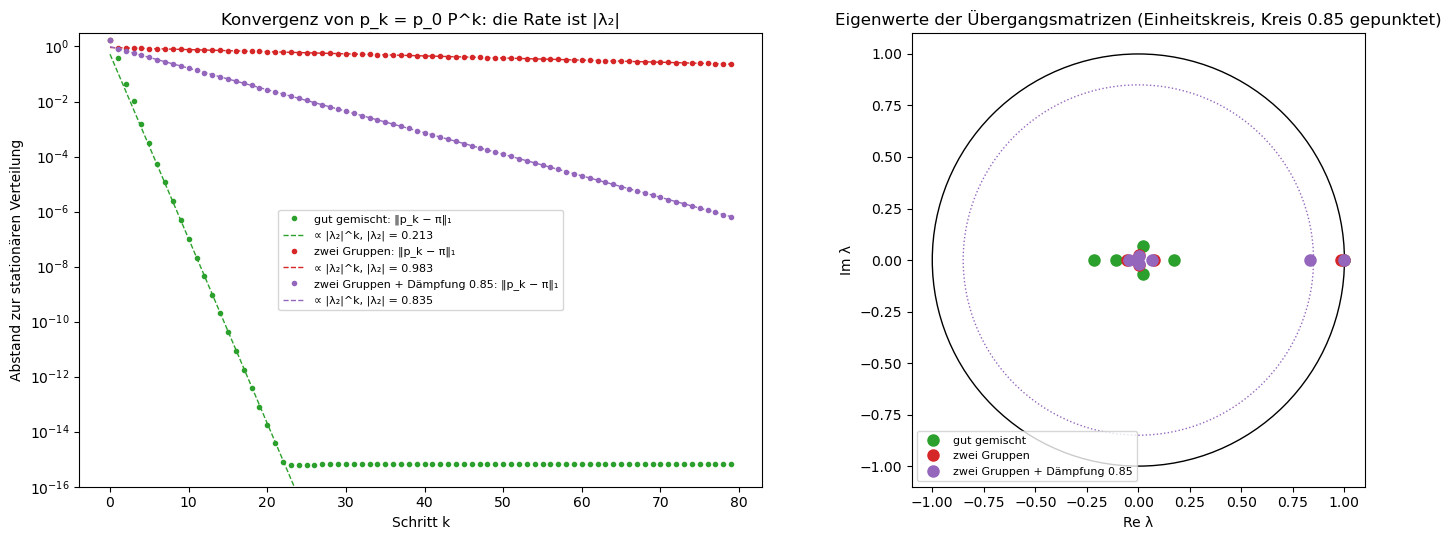

In [35]:
eigen.powers()

**35. Lineare Differentialgleichungen: Spur und Determinante entscheiden**

Für dx/dt = A x bestimmen die Eigenwerte das Verhalten, und für 2×2-Matrizen reichen dafür Spur und Determinante. Die Spur-Determinanten-Ebene ordnet alle Fälle; dazu sechs Phasenporträts.

Unter der Parabel sind die Eigenwerte reell, darüber komplex (Spiralen); bei negativer Determinante gibt es einen Sattel. Links ist alles stabil, rechts instabil, auf der Achse liegen die Zentren. Die sechs Phasenporträts bestätigen die Einteilung: Knoten, Sattel, Spiralen und Zentrum.

1 stabiler Knoten (Senke): τ = -3.00, Δ = +2.00, τ² − 4Δ = +1.00 → λ = -2, -1; aus τ und Δ: -1, -2
2 instabiler Knoten (Quelle): τ = +3.00, Δ = +2.00, τ² − 4Δ = +1.00 → λ = 2, 1; aus τ und Δ: 2, 1
3 Sattel: τ = +0.00, Δ = -2.00, τ² − 4Δ = +8.00 → λ = 1.41, -1.41; aus τ und Δ: 1.41, -1.41
4 stabiler Strudel: τ = -1.00, Δ = +4.25, τ² − 4Δ = -16.00 → λ = -0.5 + 2i, -0.5 − 2i; aus τ und Δ: -0.5 + 2i, -0.5 − 2i


5 instabiler Strudel: τ = +0.60, Δ = +4.09, τ² − 4Δ = -16.00 → λ = 0.3 + 2i, 0.3 − 2i; aus τ und Δ: 0.3 + 2i, 0.3 − 2i
6 Zentrum: τ = +0.00, Δ = +2.00, τ² − 4Δ = -8.00 → λ = 0 + 1.41i, 0 − 1.41i; aus τ und Δ: 0 + 1.41i, 0 − 1.41i


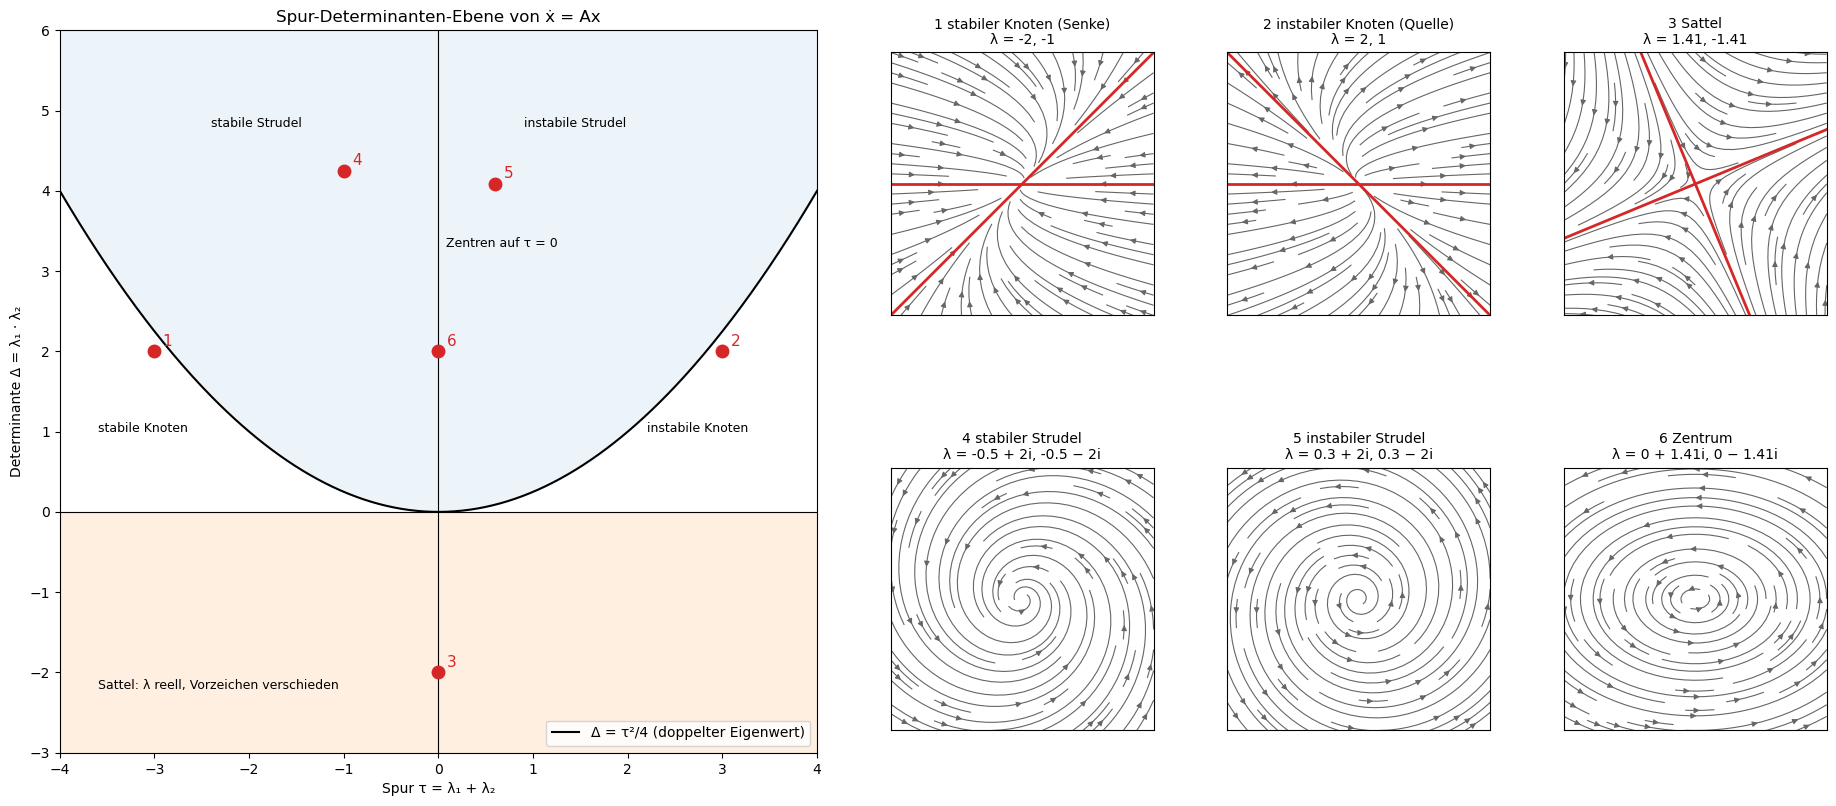

In [36]:
eigen.linear_odes()

**36. Schwingungen: Eigenfrequenzen messen**

Acht Massen an Federn zwischen zwei festen Enden. Die Eigenvektoren der Steifigkeitsmatrix sind die Schwingungsformen, die Wurzeln der Eigenwerte die Frequenzen; aus einer einzigen Messung lassen sie sich mit der Fourier-Transformation zurückgewinnen.

Die tiefste Mode (ω = 0.347) hat keinen Knoten, jede höhere einen Vorzeichenwechsel mehr; es sind abgetastete Sinuskurven. Die Bewegung einer einzelnen Masse sieht unregelmäßig aus, weil acht Schwingungen überlagert sind; ihr Spektrum zeigt die acht Frequenzen genau.

Eigenfrequenzen ω_k = √λ_k: [0.3473  0.68404 1.      1.28558 1.53209 1.73205 1.87939 1.96962]
Formel 2 sin(kπ/18), größte Abweichung 1.2e-15


aus dem Spektrum gemessen:       [0.3473  0.68404 1.      1.28558 1.53209 1.73203 1.87939 1.96962]
größte Abweichung 1.8e-05, Auflösung 2π/T = 0.0105
Höhen der Spitzen (relativ zur höchsten): [0.242 0.261 0.659 0.046 0.475 0.177 1.    0.358]


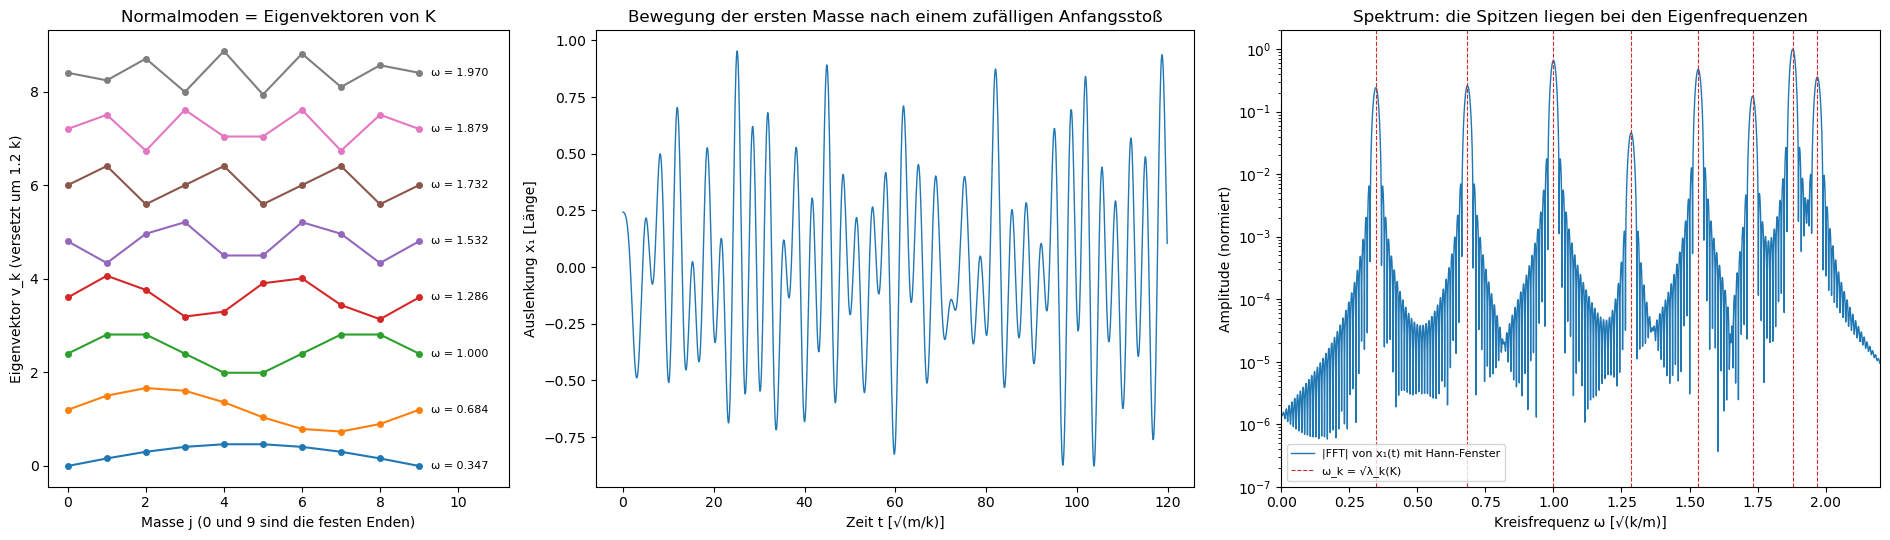

In [37]:
eigen.vibrations()

**37. Daten: Hauptkomponenten sind Eigenvektoren**

Die Hauptkomponenten einer Punktwolke sind die Eigenvektoren ihrer Kovarianzmatrix, die Eigenwerte die Varianzen in diesen Richtungen. Beispiele: eine künstliche Wolke und die Bilder handgeschriebener Ziffern.

Bei der künstlichen Wolke liegen die Eigenwerte 8.53 und 0.91 nahe den wahren Varianzen 9 und 1, die Hauptachse bei 29° statt 30°. Bei den Ziffern fallen die 64 Eigenwerte über mehr als drei Größenordnungen; wenige Komponenten tragen den größten Teil der Varianz und trennen die Ziffern schon in zwei Dimensionen.

Punktwolke: Kovarianz-Eigenwerte [8.529 0.912] (wahr 9 und 1), Hauptachse bei 29.2° (wahr 30°)
Ziffern: 1797 Bilder mit 64 Pixeln; Spur der Kovarianz = Gesamtvarianz 1202.1
  k =  2: erklärter Anteil 0.285, Rekonstruktionsfehler  859.4230, Summe der übrigen Eigenwerte  859.4230
  k =  5: erklärter Anteil 0.545, Rekonstruktionsfehler  547.0211, Summe der übrigen Eigenwerte  547.0211
  k = 10: erklärter Anteil 0.738, Rekonstruktionsfehler  314.6901, Summe der übrigen Eigenwerte  314.6901
  k = 20: erklärter Anteil 0.894, Rekonstruktionsfehler  127.0633, Summe der übrigen Eigenwerte  127.0633
  k = 30: erklärter Anteil 0.959, Rekonstruktionsfehler   49.1854, Summe der übrigen Eigenwerte   49.1854
  Pixel, die in allen Bildern gleich sind (Varianz 0): 3
  für 90 % der Varianz braucht man 21 von 64 Komponenten


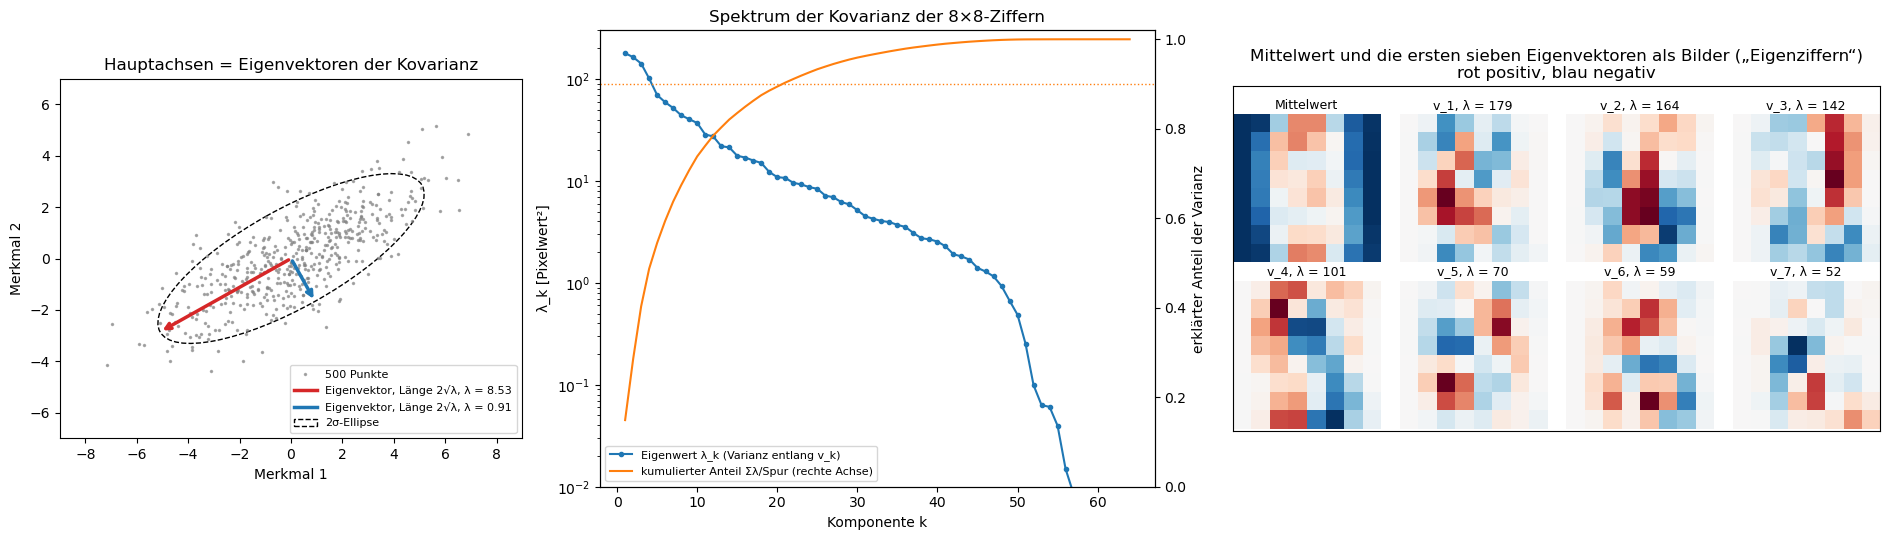

In [38]:
eigen.principal_components()

**38. Spur und Determinante: was nicht vom Koordinatensystem abhängt**

Dieselbe Matrix in 300 zufälligen Koordinatensystemen (S A S⁻¹). Die einzelnen Einträge ändern sich, die Eigenwerte nicht, und mit ihnen Spur und Determinante.

Die Diagonaleinträge streuen zwischen −9 und +9 und haben einzeln nichts mit den Eigenwerten zu tun; ihre Summe ist aber jedes Mal 3.562851, die Summe der Eigenwerte, bis auf Rundung. Die Determinante ist ihr Produkt, und aus den Spuren der Potenzen folgt das ganze charakteristische Polynom.

A: Eigenwerte 2.612, 0.7209, 0.115 + 0.6494i, 0.115 − 0.6494i
   Spur +3.562851 = Σλ +3.562851, det +0.818909 = Πλ +0.818909
300 Ähnlichkeitstransformationen S A S⁻¹: Diagonaleinträge zwischen -9.09 und +9.20, Spur schwankt um 4.9e-15, Eigenwerte um höchstens 2.5e-14
char. Polynom aus den Spuren tr(A^k): [ 1.       -3.562851  3.084247 -1.882355  0.818909]
char. Polynom direkt (np.poly):        [ 1.       -3.562851  3.084247 -1.882355  0.818909]
Momente tr(A^k)/n für k = 2, 4, 6, 8, 10: [ 0.999  1.996  4.986 13.958 41.895]  Catalan-Zahlen: [1, 2, 5, 14, 42]
ungerade Momente k = 1, 3, 5, 7, 9:       [-0.005 -0.03  -0.114 -0.404 -1.411]
  Abweichung tr(A^k)/n gegen Mittel von λ^k: höchstens 1.5e-13


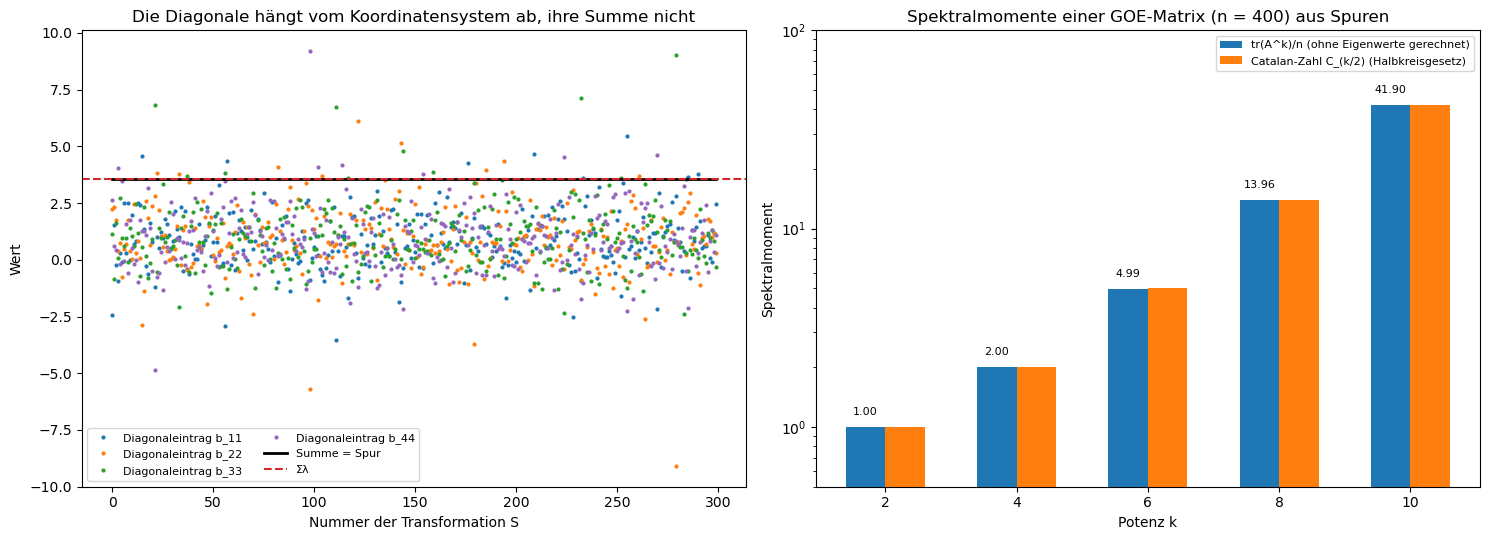

In [39]:
eigen.trace_det()

**39. Was die Diagonale verrät: Gershgorin und Schur-Horn**

Jeder Eigenwert liegt in einem Kreis um einen Diagonaleintrag, dessen Radius die Summe der übrigen Beträge der Zeile ist (Gershgorin). Für symmetrische Matrizen sagt Schur-Horn, welche Diagonalen zu gegebenen Eigenwerten möglich sind.

Die Kreise um −6 und 8 stehen allein und enthalten je genau einen Eigenwert, nahe am Diagonaleintrag; die drei überlappenden Kreise enthalten zusammen genau drei. Welcher Eigenwert in welchem Kreis liegt, ist bei Überlappung nicht mehr festgelegt.

Diagonale: [-6. -2.  1.  4.  8.]  Gershgorin-Radien: [1.  1.6 2.9 2.8 0.8]
Eigenwerte: -6.11, -1.82, 2.46 − 1.26i, 2.46 + 1.26i, 8
  Kreis 1 (Mitte -6, Radius 1.00) enthält 1 Eigenwert(e)
  Kreis 2 (Mitte -2, Radius 1.60) enthält 1 Eigenwert(e)
  Kreis 3 (Mitte +1, Radius 2.90) enthält 3 Eigenwert(e)
  Kreis 4 (Mitte +4, Radius 2.80) enthält 2 Eigenwert(e)
  Kreis 5 (Mitte +8, Radius 0.80) enthält 1 Eigenwert(e)
Schur–Horn: 6000 Diagonalen von UΛU† mit Λ = diag(1, 2, 4): Summe 7.000000000000 … 7.000000000000; größter Eintrag ≤ 4: True, Summe der zwei größten ≤ 6: True
  Anteil der Punkte im inneren Sechseck halber Größe (ein Viertel der Fläche): 0.492


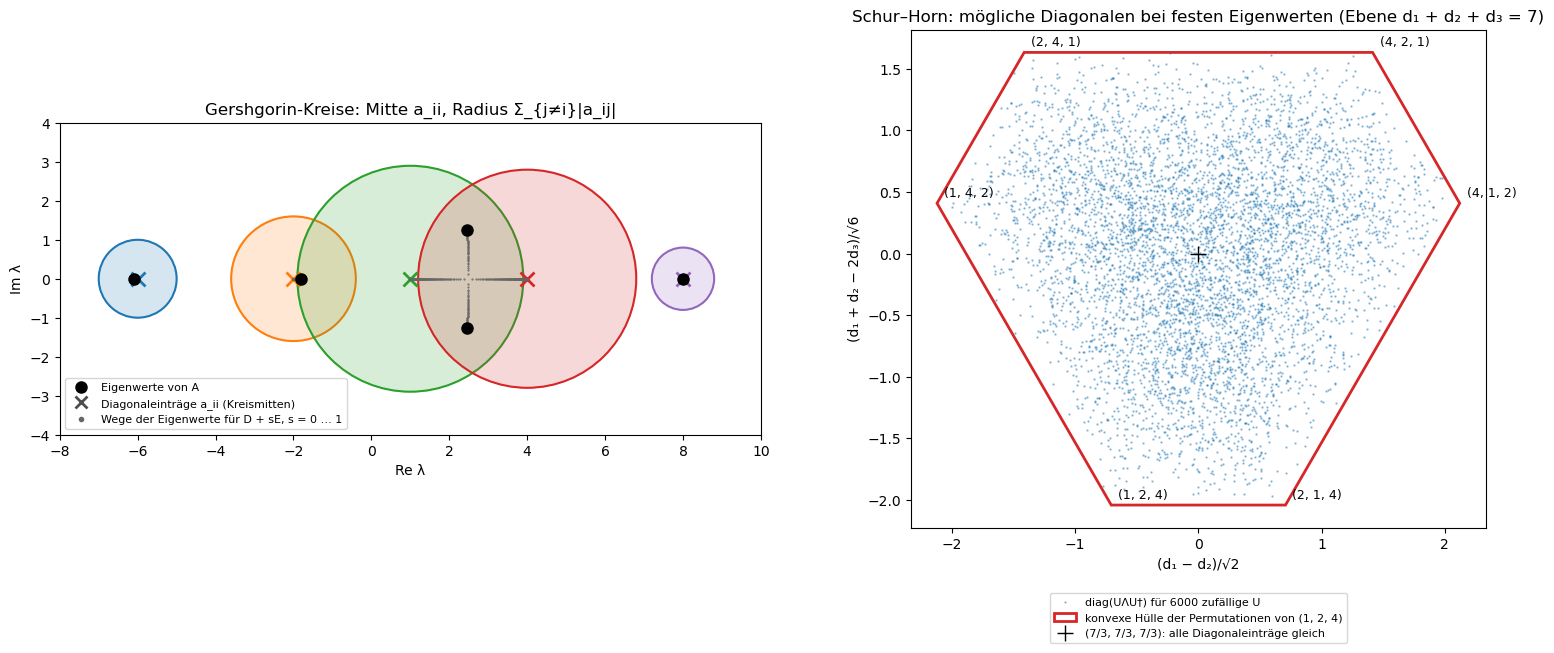

In [40]:
eigen.gershgorin()

**40. Was die Nebendiagonale bewirkt**

Zwei Zustände mit der Verstimmung ε und der Kopplung g. Ohne Kopplung kreuzen sich die Eigenwerte, mit Kopplung weichen sie einander aus; weit weg von der Kreuzung gilt die Störungstheorie.

Mit Kopplung werden die Geraden zu Hyperbeln mit dem kleinsten Abstand 2g. An der vermiedenen Kreuzung tauschen die Eigenvektoren ihren Charakter: Der untere Zustand wechselt stetig von einem Basiszustand zum anderen. Weit weg sind die Eigenwerte fast die Diagonaleinträge, verschoben um g²/(2ε) (zweite Ordnung der Störungstheorie).

g = 0.1: kleinster Abstand der beiden Niveaus 0.2000 (= 2g)
g = 0.3: kleinster Abstand der beiden Niveaus 0.6000 (= 2g)
g = 0.6: kleinster Abstand der beiden Niveaus 1.2000 (= 2g)
Hellmann–Feynman bei ε = 0.4, g = 0.3: dλ₋/dε = -0.80000000, ⟨v₋|σ_z|v₋⟩ = -0.80000000, exakt −ε/√(ε² + g²) = -0.80000000
6×6: Fehler der Diagonale allein ∝ g^1.99, mit zweiter Ordnung Σ|g W_ij|²/(d_i − d_j) ∝ g^3.01


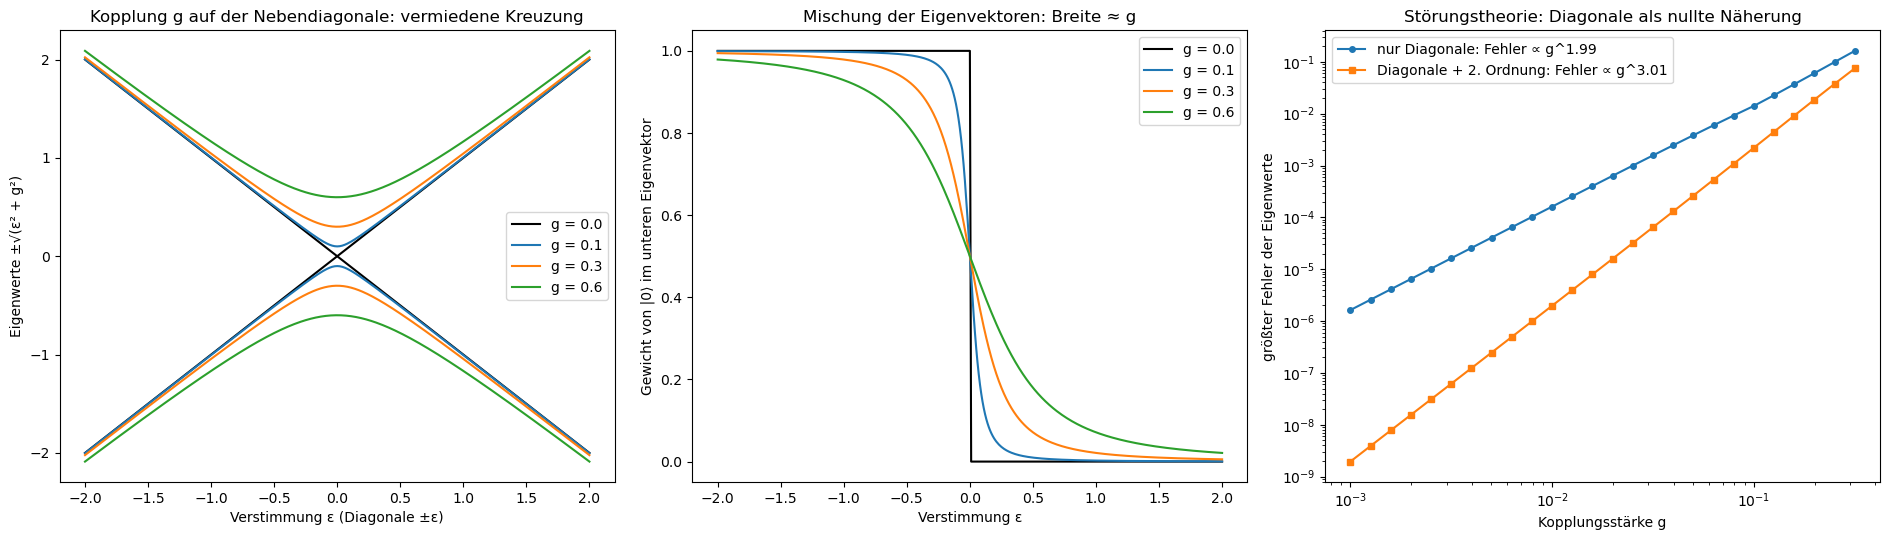

In [41]:
eigen.off_diagonal()

**41. Jacobi-Verfahren: die Nebendiagonale wegdrehen**

Das älteste Verfahren für symmetrische Matrizen: Eine Drehung nach der anderen macht je einen Nebendiagonaleintrag null.

Jede der 168 Drehungen verkleinert die Nebendiagonale, und die Summe der Quadrate aller Einträge bleibt dabei gleich. Nach drei Durchgängen ist die Nebendiagonale bei 3·10⁻², nach sechs auf Rundungsniveau (5·10⁻¹⁶): Am Ende konvergiert das Verfahren quadratisch, und auf der Diagonale stehen die Eigenwerte.

nach Sweep 1: off(A) = 3.09e+00
nach Sweep 2: off(A) = 6.54e-01
nach Sweep 3: off(A) = 2.68e-02
nach Sweep 4: off(A) = 7.52e-05
nach Sweep 5: off(A) = 1.73e-10
nach Sweep 6: off(A) = 5.43e-16
nach 3 Sweeps liegen die Nebendiagonaleinträge zwischen 5e-19 und 1e-02
Frobenius-Norm² bleibt 36.201891 (Schwankung 6.4e-14); am Ende Σ a_ii² = 36.201891
Diagonale nach Jacobi (sortiert): [-4.56255655 -1.7229343  -1.16719534 -0.88461212  0.23593929  0.60914957
  1.58638522  2.70707104]
np.linalg.eigvalsh:               [-4.56255655 -1.7229343  -1.16719534 -0.88461212  0.23593929  0.60914957
  1.58638522  2.70707104]
‖A V − V diag‖ = 6.2e-15: die Spalten der aufmultiplizierten Drehungen sind die Eigenvektoren


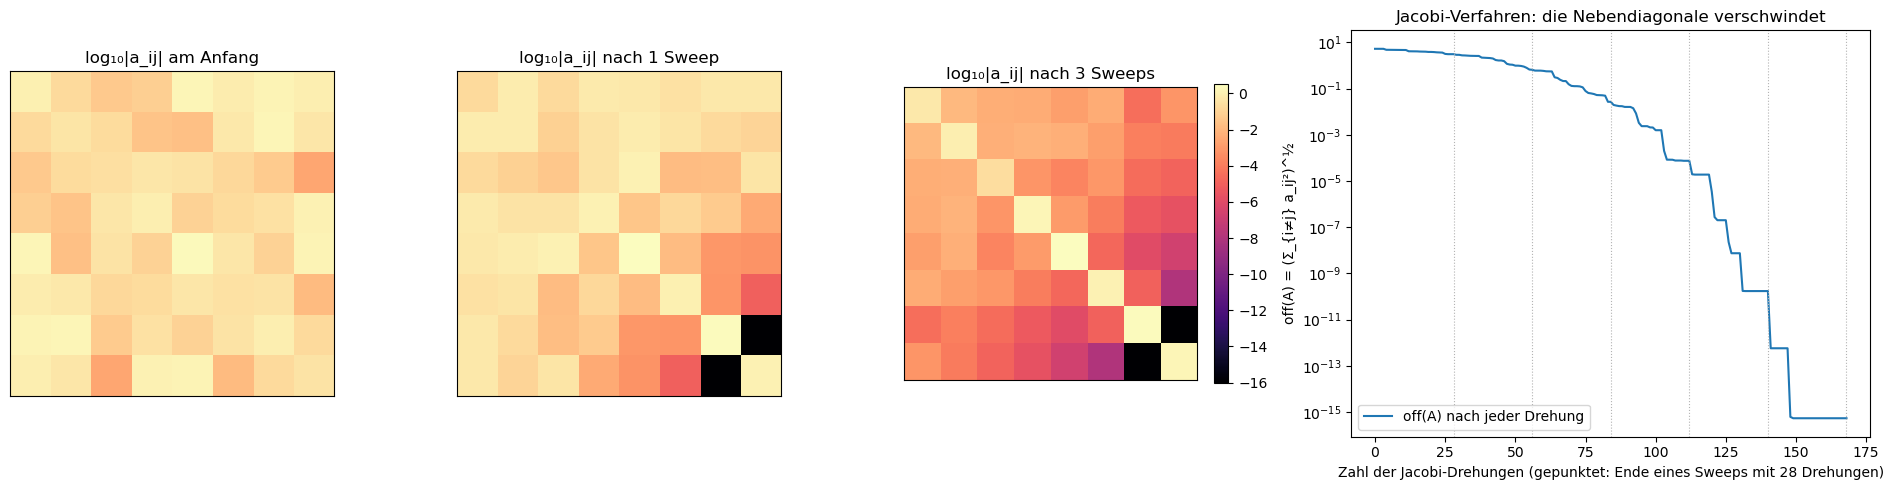

In [42]:
eigen.jacobi_method()

**42. Potenzmethode und Rayleigh-Quotient**

Die Potenzmethode multipliziert einen Vektor immer wieder mit der Matrix; er dreht sich zum größten Eigenvektor, umso langsamer, je näher der zweite Eigenwert am ersten liegt. Der Rayleigh-Quotient schätzt den Eigenwert doppelt so genau; mit Verschiebung wird daraus die Rayleigh-Quotienten-Iteration.

Bei einem Verhältnis von 0.5 ist der Eigenwert nach 19 Schritten auf 10⁻¹⁴ genau, bei 0.99 ist der Eigenvektor nach 200 Schritten noch weit weg. Die Rayleigh-Quotienten-Iteration verschiebt die Matrix jedes Mal um den aktuellen Schätzwert und kommt so mit wenigen Schritten aus.

λ₂/λ₁ = 0.5: nach 200 Schritten Winkelfehler 3.6e-16 (r^200 = 6.2e-61), Rayleigh-Fehler 4.4e-16 (r^400 = 3.9e-121); unter 1e-14 nach 43 bzw. 19 Schritten
λ₂/λ₁ = 0.9: nach 200 Schritten Winkelfehler 3.8e-11 (r^200 = 7.1e-10), Rayleigh-Fehler 1.0e-17 (r^400 = 5.0e-19); unter 1e-14 nach None bzw. 115 Schritten
λ₂/λ₁ = 0.99: nach 200 Schritten Winkelfehler 4.9e-01 (r^200 = 1.3e-01), Rayleigh-Fehler 2.4e-03 (r^400 = 1.8e-02); unter 1e-14 nach None bzw. None Schritten
inverse Iteration, Shift σ = 1.05: |ρ_k − λ₁| = 1e-01, 5e-04, 2e-05, 2e-06, 2e-07, 2e-08, 3e-09
Rayleigh-Quotienten-Iteration: |ρ_k − λ₁| = 1e-01, 3e-02, 8e-03, 6e-05, 2e-11, 2e-16, 1e-17


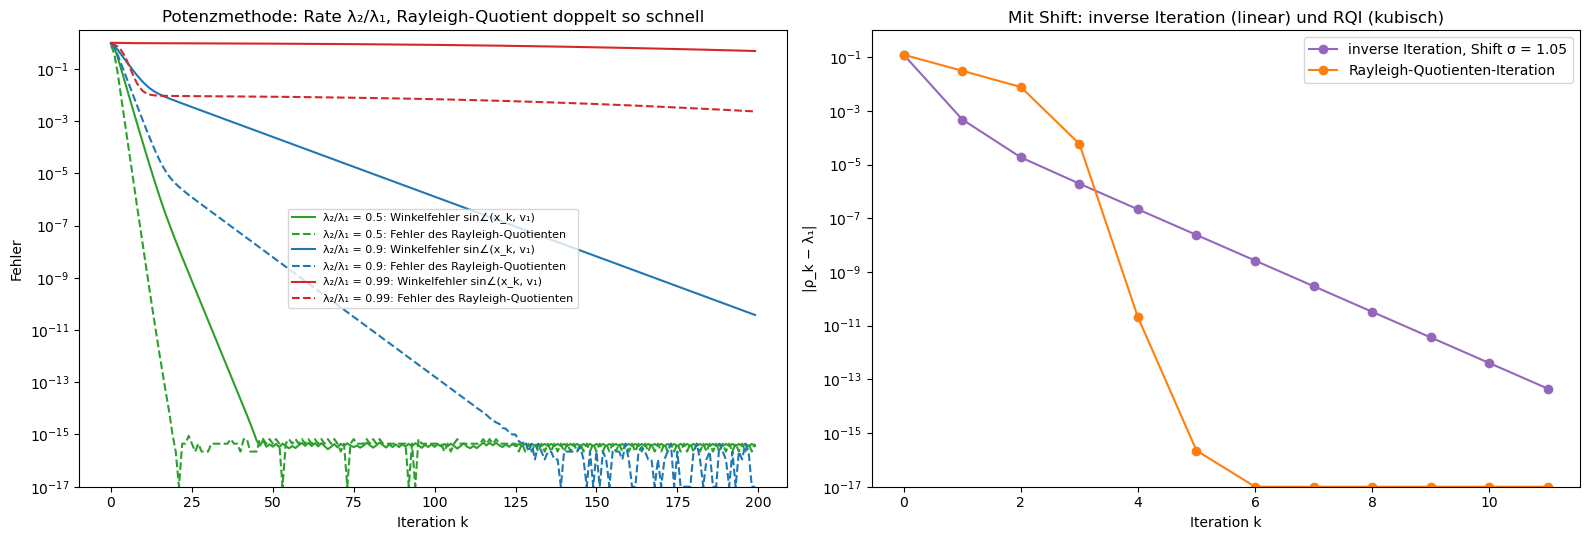

In [43]:
eigen.power_method()

**43. QR-Algorithmus: das Standardverfahren**

Der QR-Algorithmus zerlegt die Matrix in eine Drehung mal ein Dreieck und multipliziert in umgekehrter Reihenfolge; das wiederholt, ändert die Eigenwerte nicht und macht die Matrix dreieckig. So rechnen numpy und LAPACK.

Die Tridiagonalform bleibt erhalten, und die Nebendiagonale klingt geometrisch ab, am langsamsten zwischen nahe beieinanderliegenden Eigenwerten. Mit Verschiebungen (Shifts) wird die Konvergenz quadratisch bis kubisch.

|a_(2,1)|: Rate pro Iteration 0.7501, erwartet λ_2/λ_1 = 0.7500
|a_(3,2)|: Rate pro Iteration 0.4985, erwartet λ_3/λ_2 = 0.5000
|a_(4,3)|: Rate pro Iteration 0.8381, erwartet λ_4/λ_3 = 0.8333
|a_(5,4)|: Rate pro Iteration 0.3989, erwartet λ_5/λ_4 = 0.4000
|a_(6,5)|: Rate pro Iteration 0.5000, erwartet λ_6/λ_5 = 0.5000
Diagonale nach 60 Iterationen: [8.  6.  3.  2.5 1.  0.5]
|a_(m,m−1)| nach jedem Schritt mit Shift: 2e-02, 1e-06, 1e-18, 2e-05, 3e-18, 5e-03, 2e-08, 1e-24, 3e-13, 6e-40, 1e-17
mit Wilkinson-Shift: Eigenwerte [8.  6.  3.  2.5 1.  0.5], Iterationen pro Eigenwert [3, 2, 3, 2, 1] (zusammen 11)


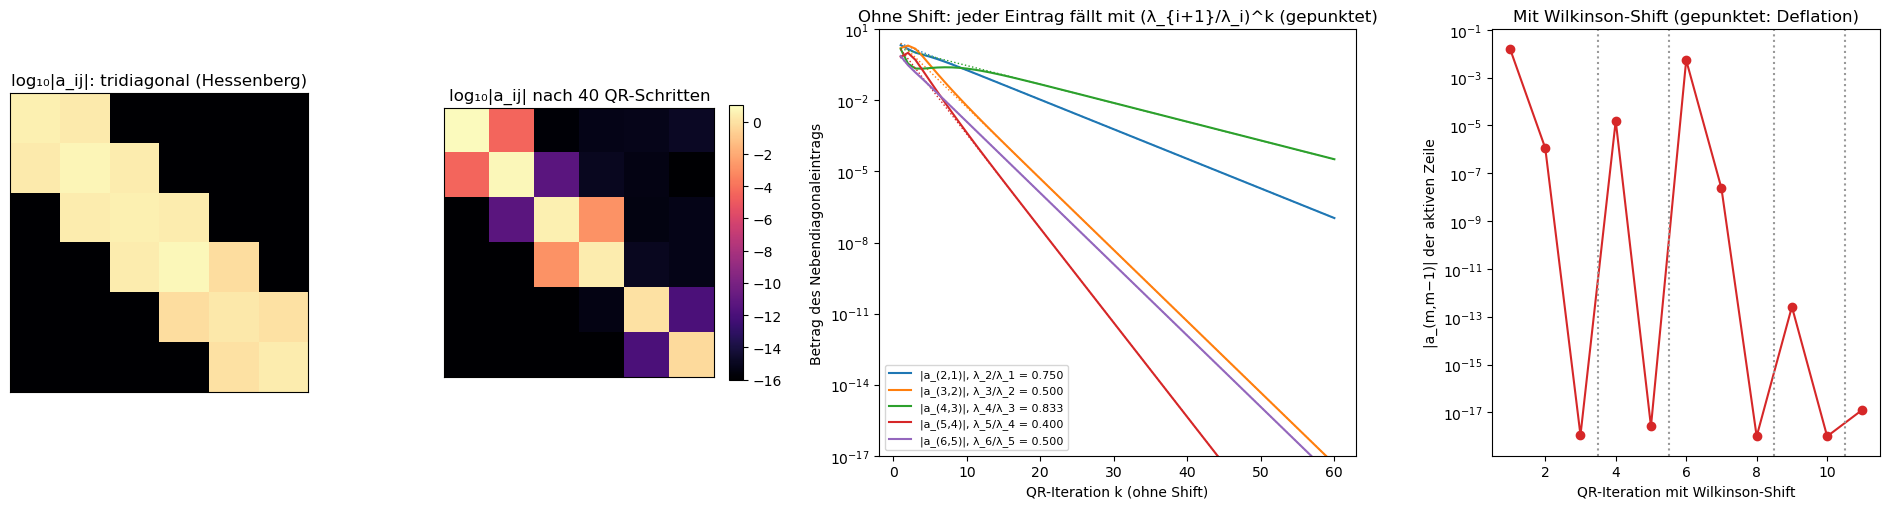

In [44]:
eigen.qr_algorithm()

**44. Lanczos: Eigenwerte riesiger dünnbesetzter Matrizen**

Eine Heisenberg-Spinkette mit 14 Spins hat eine Matrix mit 16 384 Zeilen, aber nur acht Einträgen pro Zeile. Lanczos braucht nur Matrix-Vektor-Produkte und findet die äußersten Eigenwerte in wenigen Dutzend Schritten.

Die acht kleinsten Eigenwerte kommen in Sekundenbruchteilen; die Grundzustandsenergie pro Spin (−0.4474) liegt nahe am Wert der unendlichen Kette (−0.4431). Nach 40 Schritten ist der Grundzustand auf Rundungsgenauigkeit bestimmt.

Heisenberg-Ring mit 14 Spins: Dimension 16384, 131072 Einträge ungleich null (4.9e-04 der Matrix; dicht wären es 2.1 GB)
scipy eigsh (ARPACK, implizit neugestartetes Lanczos): 8 kleinste Eigenwerte [-6.26355  -5.956444 -5.956444 -5.956444 -5.748063 -5.558563 -5.558563
 -5.558563] in 0.0 s
  E₀/N = -0.447396; unendlich lange Kette (Bethe-Ansatz): 1/4 − ln 2 = -0.443147
Lanczos: |Ritz₀ − E₀| = 1.9e-04 nach 20, 8.0e-15 nach 40, 1.8e-15 nach 60 Schritten
  verschiedene Eigenwerte unter den 8 kleinsten: [-6.26355  -5.956444 -5.748063 -5.558563]
  Ritz-Werte nach 60 Schritten bis -5.5586: [-6.26355  -5.956444 -5.748063 -5.558563]
  Ritz-Werte nach 120 Schritten bis -5.5586: [-6.26355  -5.956444 -5.956444 -5.748063 -5.558563 -5.558563]
  größter Eigenwert 3.500000 (= N/4, alle Spins parallel); Ritz_max nach 120 Schritten 3.500000


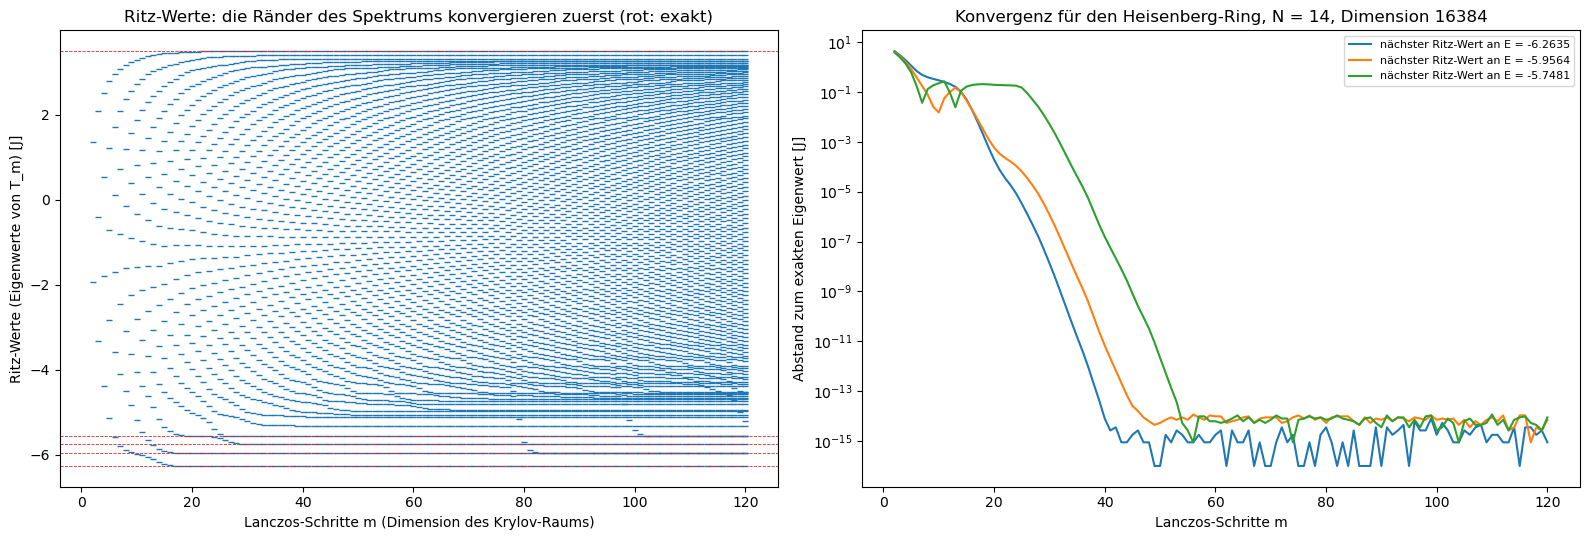

In [45]:
eigen.lanczos_method()

**45. Wie empfindlich sind Eigenwerte?**

Eine kleine Störung der Größe 10⁻⁸ an einer symmetrischen Matrix und an einem Jordan-Block.

Bei der symmetrischen Matrix verschieben sich die Eigenwerte höchstens um die Größe der Störung (Weyl). Beim Jordan-Block der Größe 8 springen sie auf einen Kreis vom Radius 10⁻⁸ hoch 1/8 = 0.1: zehn Millionen Mal mehr. Nicht diagonalisierbare und fast nicht diagonalisierbare Matrizen haben empfindliche Eigenwerte.

symmetrisch, ‖E‖ = 1e-8: größte Verschiebung eines Eigenwerts 7.3e-09 (Weyl: ≤ ‖E‖)
Jordan-Block 8×8, ‖E‖ = 1e-8: größte Verschiebung 0.093, (1e-8)^(1/8) = 0.100
Steigungen: symmetrisch 1.00, Jordan-Block 0.128 (erwartet 1 und 1/8 = 0.125)
obere Dreiecksmatrix mit Diagonale 1 … 8: κ(V) = 1.1e+02; größte Verschiebung bei ‖E‖ = 1e-8: 1.8e-07, Schranke κ(V)·‖E‖ = 1.1e-06 (symmetrisch: κ(V) = 1)


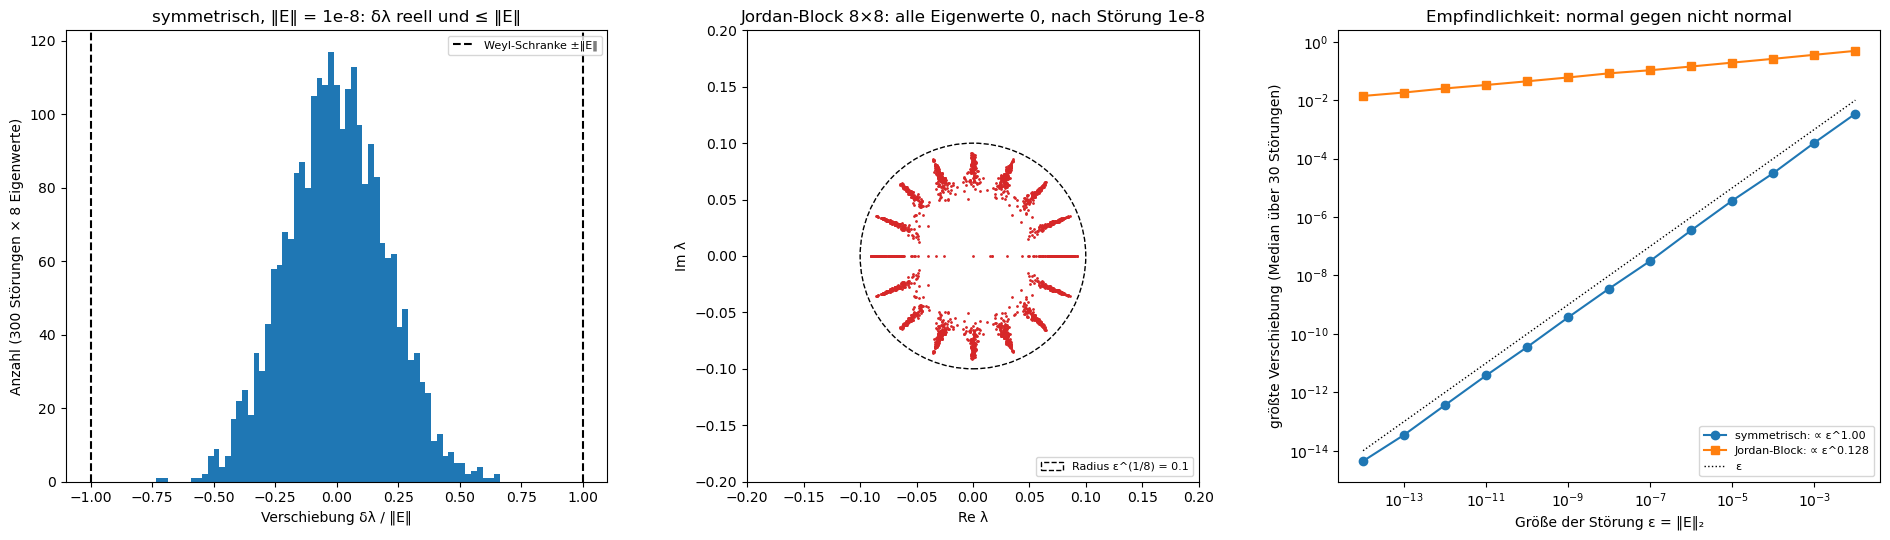

In [46]:
eigen.sensitivity()

**46. Quanten: Eigenwerte sind Messwerte**

Eine Observable ist eine symmetrische (hermitesche) Matrix; ihre Eigenwerte sind die möglichen Messwerte, die Diagonale der Dichtematrix in ihrer Eigenbasis die Born-Wahrscheinlichkeiten.

Für einen Spin 1 sind die Wahrscheinlichkeiten 0.024, 0.173 und 0.803. Dephasierung lässt die Diagonale unverändert und löscht die Nebendiagonale; 2000 simulierte Messungen ergeben nur die drei Eigenwerte, mit den vorhergesagten Häufigkeiten.

Eigenwerte von S_x: [-1.  0.  1.]; Born-Wahrscheinlichkeiten = Diagonale von ρ in der Eigenbasis: [0.0236 0.1735 0.8029]
⟨S_x⟩ = tr(ρ S_x) = +0.7793 = Σ a_k p_k = +0.7793
2000 Messungen: nur die Werte [-1.  0.  1.] kommen vor, Häufigkeiten [0.029  0.1795 0.7915]; Mittelwert +0.7625 ± 0.0109
Dephasierung: ⟨S_x⟩ bleibt +0.7793 … +0.7793, ⟨S_z⟩ fällt von +0.3673 auf +0.0067, Reinheit tr ρ² von 1.0000 auf 0.6754 (Σp_k² = 0.6753)
⟨a_k|S_z|a_k⟩ für die drei Eigenvektoren von S_x: [-0.  0.  0.]


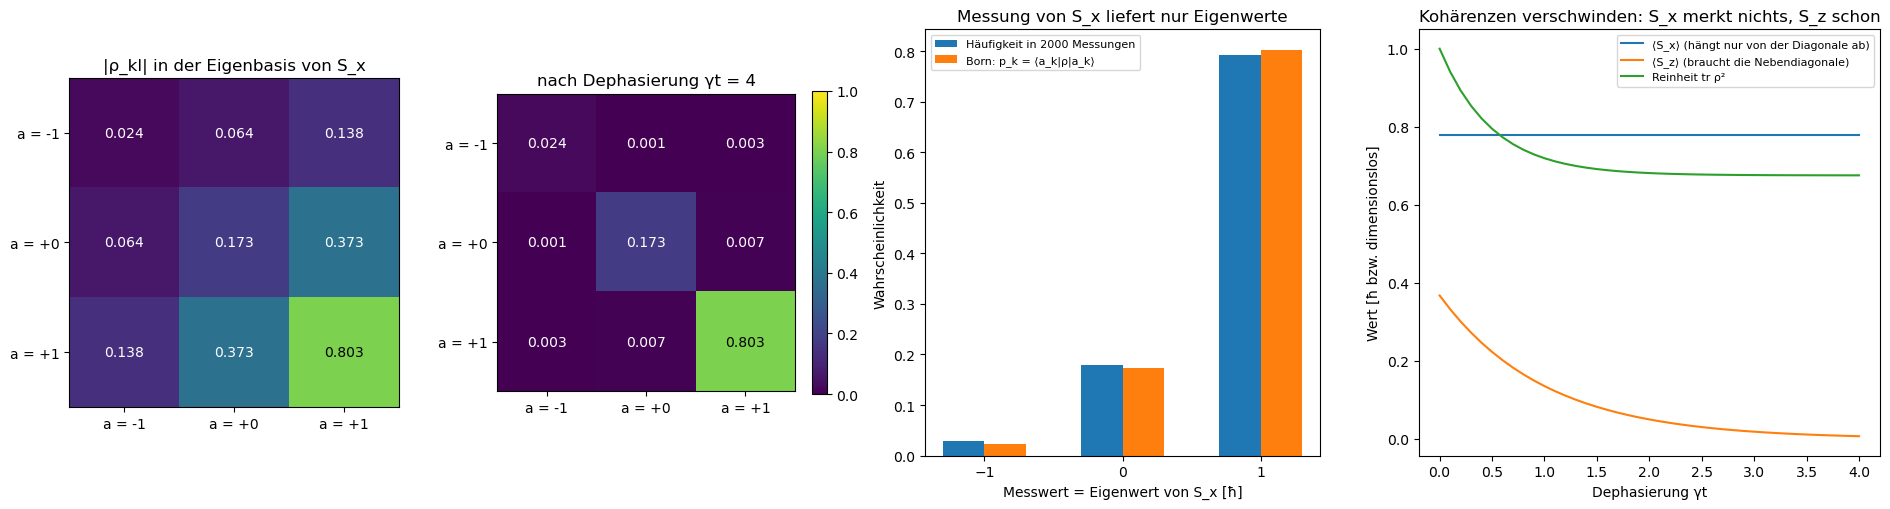

In [47]:
eigen.quantum_measurement()

**47. Spektroskopie auf dem Quantencomputer**

Der Hadamard-Test misst mit einem Hilfsqubit den Erwartungswert von e^(−iHt). Als Zeitreihe gemessen und Fourier-transformiert, zeigt er die Eigenwerte von H als Spitzen.

Die simulierte Schaltung trifft Real- und Imaginärteil genau. Die Zeitreihe aus je 400 Messungen ist verrauscht, ihre Fourier-Transformierte zeigt trotzdem die Eigenwerte an den richtigen Stellen; je länger die Zeitreihe, desto schärfer die Spitzen.

Eigenwerte von H: [-3.1067 -2.3682 -0.873  -0.1345  0.1345  0.873   2.3682  3.1067]
Gewichte |⟨E_j|000⟩|²: [5.895e-01 2.219e-01 2.290e-02 1.190e-01 1.340e-02 1.000e-04 1.580e-02
 1.730e-02]
Hadamard-Test (Re) bei t = 0.7: 2 P(0) − 1 = -0.214546, Re⟨ψ|U|ψ⟩ = -0.214546
Hadamard-Test (Im) bei t = 0.7: 2 P(0) − 1 = +0.699381, Im⟨ψ|U|ψ⟩ = +0.699381
256 Zeitpunkte, Δt = 0.25, je 400 Schüsse für Re und Im; Messrauschen pro Punkt 0.062
Auflösung 2π/(K Δt) = 0.098, Nyquist-Grenze ±π/Δt = ±12.57
Spitzen des gemessenen Spektrums bei ω = [-3.106 -2.37  -0.132]
Eigenwerte mit Gewicht über 5 %:        [-3.107 -2.368 -0.135]


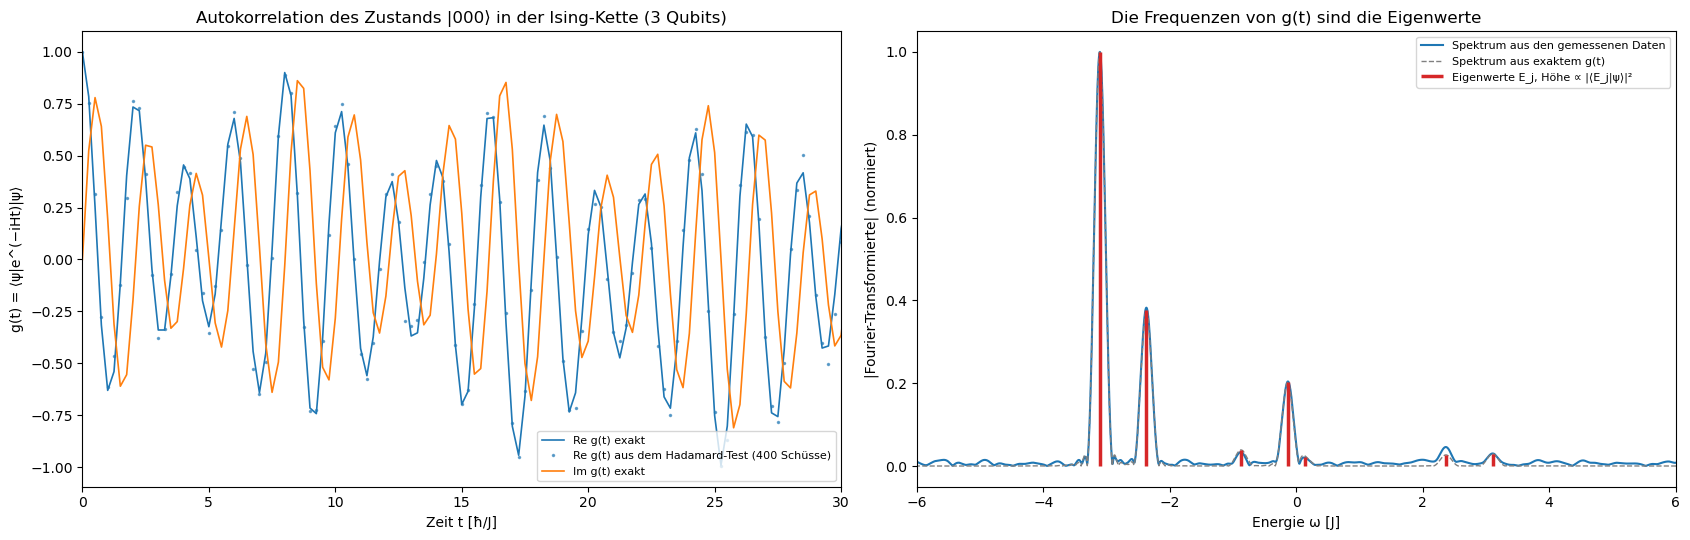

In [48]:
eigen.hadamard_test()

**48. Quantenphasenschätzung (QPE)**

Die Phasenschätzung schreibt die Phase eines Eigenwerts von U in ein Register von Qubits; mit t Qubits auf t Binärstellen genau.

Liegt die Phase genau auf dem Gitter, ist das Ergebnis sicher. Liegt sie genau dazwischen, trifft man den nächsten Gitterwert nur mit 0.406, einen der beiden nächsten mit 0.811, gerade über den Schranken 4/π² und 8/π². Für eine zuverlässige Schätzung nimmt man einige Qubits mehr.

φ = 10.0/32: P(nächster Gitterwert) = 1.0000, P(einer der zwei nächsten) = 1.0000
φ = 10.4/32: P(nächster Gitterwert) = 0.5731, P(einer der zwei nächsten) = 0.8279
φ = 10.5/32: P(nächster Gitterwert) = 0.4056, P(einer der zwei nächsten) = 0.8112
untere Schranke 4/π² = 0.4053 für den nächsten, 8/π² = 0.8106 für die zwei nächsten
Register zeigt 26/128 = 0.2031 (Phase 0.2): Wahrscheinlichkeit um die Spitze 0.663 (|c|² = 0.7), Überlapp des Systems danach mit dem Eigenvektor 0.999984
Register zeigt 83/128 = 0.6484 (Phase 0.65): Wahrscheinlichkeit um die Spitze 0.294 (|c|² = 0.3), Überlapp des Systems danach mit dem Eigenvektor 0.999849


Fehler gegen Zahl der Anwendungen von U: Hadamard-Test ∝ M^-0.51, QPE ∝ M^-0.99
  bei etwa 16 000 Anwendungen: Hadamard-Test 1.1e-03, QPE (t = 14) 1.7e-05


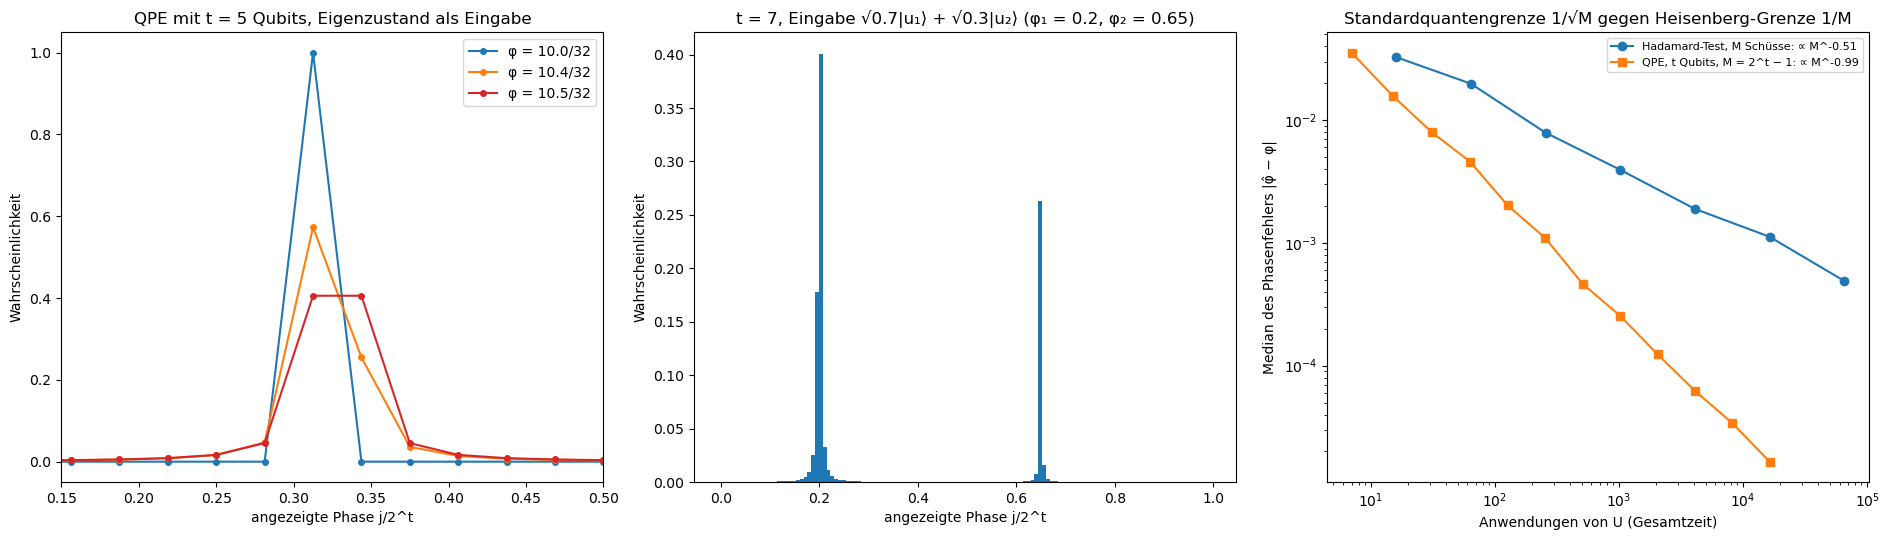

In [49]:
eigen.qpe()

**49. HHL: lineare Gleichungssysteme über die Eigenwerte**

Der HHL-Algorithmus löst A x = b auf dem Quantencomputer: Die Phasenschätzung zerlegt b nach Eigenwerten, eine Drehung teilt durch sie, und die Phasenschätzung wird rückgängig gemacht.

Nach der Phasenschätzung stehen die Gewichte genau bei den Eigenwerten 1, 2, 3, 4. Passen alle Eigenwerte auf das Gitter, ist die Lösung exakt, mit Erfolgswahrscheinlichkeit 0.50. Liegen sie dazwischen, sinkt die Treue; die Kondition der Matrix bestimmt den Aufwand.

Poisson: Eigenwerte [0.1206 0.4679 1.     1.6527 2.3473 3.     3.5321 3.8794], Kondition κ = 32.2
A (zufällig): Eigenwerte [1.7659 3.0744 3.3689 3.4622]
A mit Eigenwerten 1, 2, 3, 4: 1 − Treue für t = 3 … 10: 4e-16, 0e+00, 2e-16, 0e+00, 0e+00, 0e+00, 2e-16, 0e+00; Erfolgswahrscheinlichkeit bei t = 10: 0.4991
    erwartet für ideales HHL: Σ|β_j|²(C/λ_j)² = ‖C A⁻¹ b‖² = 0.4991
A mit zufälligen Eigenwerten in [1, 4]: 1 − Treue für t = 3 … 10: 6e-04, 8e-05, 1e-05, 5e-06, 4e-06, 1e-06, 8e-08, 5e-09; Erfolgswahrscheinlichkeit bei t = 10: 0.0905
    erwartet für ideales HHL: Σ|β_j|²(C/λ_j)² = ‖C A⁻¹ b‖² = 0.0904
Poisson-Matrix 8×8 (3 Qubits): 1 − Treue für t = 3 … 10: 1e+00, 7e-01, 2e-02, 2e-06, 3e-06, 3e-06, 2e-06, 1e-07; Erfolgswahrscheinlichkeit bei t = 10: 0.7103
    erwartet für ideales HHL: Σ|β_j|²(C/λ_j)² = ‖C A⁻¹ b‖² = 0.7247


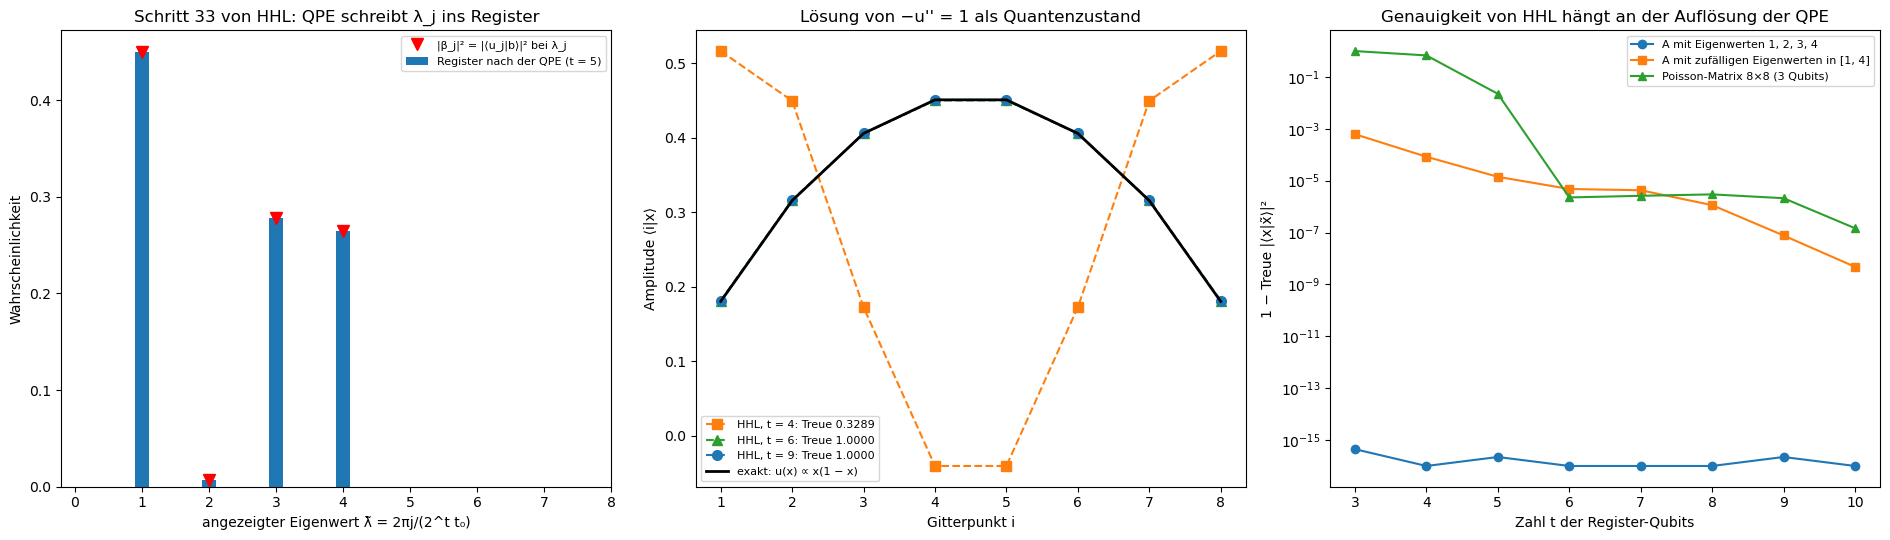

In [50]:
eigen.hhl_solver()

**50. Variational Quantum Eigensolver (VQE)**

Ein parametrisierter Schaltkreis erzeugt Zustände, ein klassischer Optimierer sucht die Parameter mit der kleinsten Energie. Verglichen werden exakte Erwartungswerte (COBYLA) und verrauschte Messungen (SPSA).

Mit exakten Werten endet die Suche 6.6·10⁻⁴ über der Grundzustandsenergie, mit 99.99 % Überlapp. Mit Messrauschen kommt SPSA langsamer voran und endet 0.034 darüber. Ohne Rauschen ist VQE genau, mit Rauschen kostet jede Stelle viele Messungen.

Ising-Kette mit 4 Spins, h = 1.0: E₀ = -4.758770, E₁ = -4.064178


VQE exakt (COBYLA): E = -4.758111, Fehler 6.6e-04, Überlapp mit dem Grundzustand 0.999879, 3000 Auswertungen


VQE mit SPSA und Schüssen: wahre Energie am Ende -4.7248 (Fehler 0.034)  Schüsse insgesamt 2 400 000
unter E₁ nach 14 Auswertungen (COBYLA) bzw. 38 Auswertungen (SPSA)
gemessene SPSA-Schätzungen unter E₀: 9 von 600; Streuung der Schätzungen in den letzten 100 Schritten 0.063
Variationsprinzip: kleinste wahre Energie aller Auswertungen -4.758111 ≥ E₀ = -4.758770
Einzelschüsse am Optimum: Σ Z_iZ_(i+1) ∈ [-3, -1, 1, 3], Σ X_i ∈ [-4, 0, 4]


Streuung der Energieschätzung: [0.7559 0.3731 0.2384 0.1346 0.0699 0.0371 0.0234]; Formel √((Var ZZ + Var X)/n) bei n = 1000: 0.0712


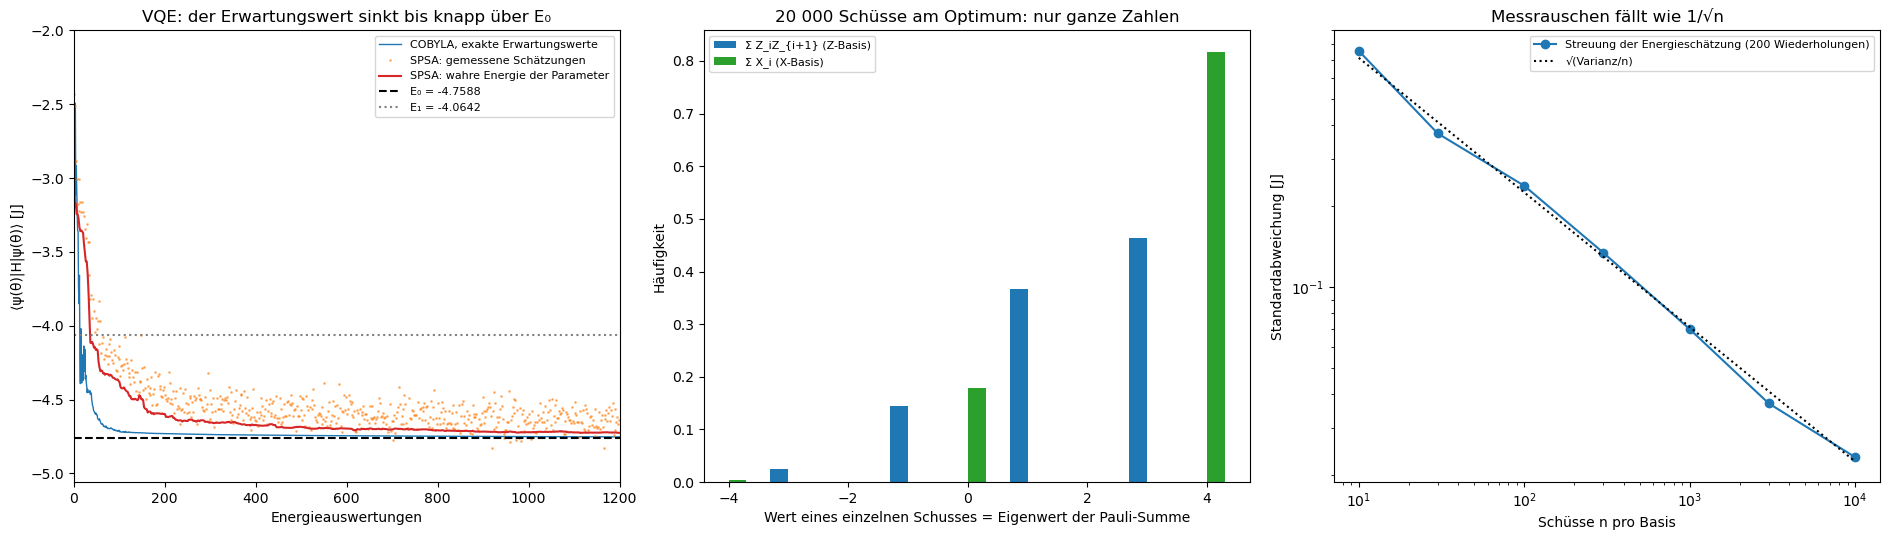

Laufzeit des ganzen Notebooks bis hier: 8 s


In [51]:
eigen.vqe()

**51. Lie-Theorie: Werkzeuge**

Eine Lie-Gruppe ist eine Gruppe, deren Elemente von kontinuierlichen Parametern abhängen, etwa die Drehungen des Raums. Weil man in ihr differenzieren kann, hat sie eine Lie-Algebra: die infinitesimalen Elemente nahe der Eins, mit dem Kommutator [X, Y] = XY − YX. Die Lie-Algebra ist ein Vektorraum, also lineare Algebra, und enthält fast die ganze Information über die Gruppe; die Exponentialabbildung führt zurück. Bereitgestellt werden Kommutator, Drehungen, Operatoren auf Qubit-Ketten, Spin-Matrizen, Gell-Mann-Matrizen, Killing-Form und Charaktertafeln.

Die Ausgabe meldet die Werkzeuge bereit.

In [52]:
lie.load()

Werkzeuge bereit: Kommutator, so(3) und Rodrigues, Qubit-Operatoren, Spin j, Gell-Mann, Killing-Form, Charaktertafel


**52. Von der Gruppe zur Algebra: der Tangentialraum an der Eins**

Jede Matrixgruppe ist durch Gleichungen definiert, etwa gᵀg = 1 für die Drehungen. Linearisiert an der Eins ergeben sie den Tangentialraum, die Lie-Algebra; gezählt wird ihre Dimension.

Für SO(2) ist die Algebra die Tangente an den Einheitskreis; Tangente und Kreis liegen nur für kleine Winkel nahe beieinander. Die gezählten Dimensionen treffen die Formeln, etwa n(n − 1)/2 für SO(n) und n² − 1 für SL(n).

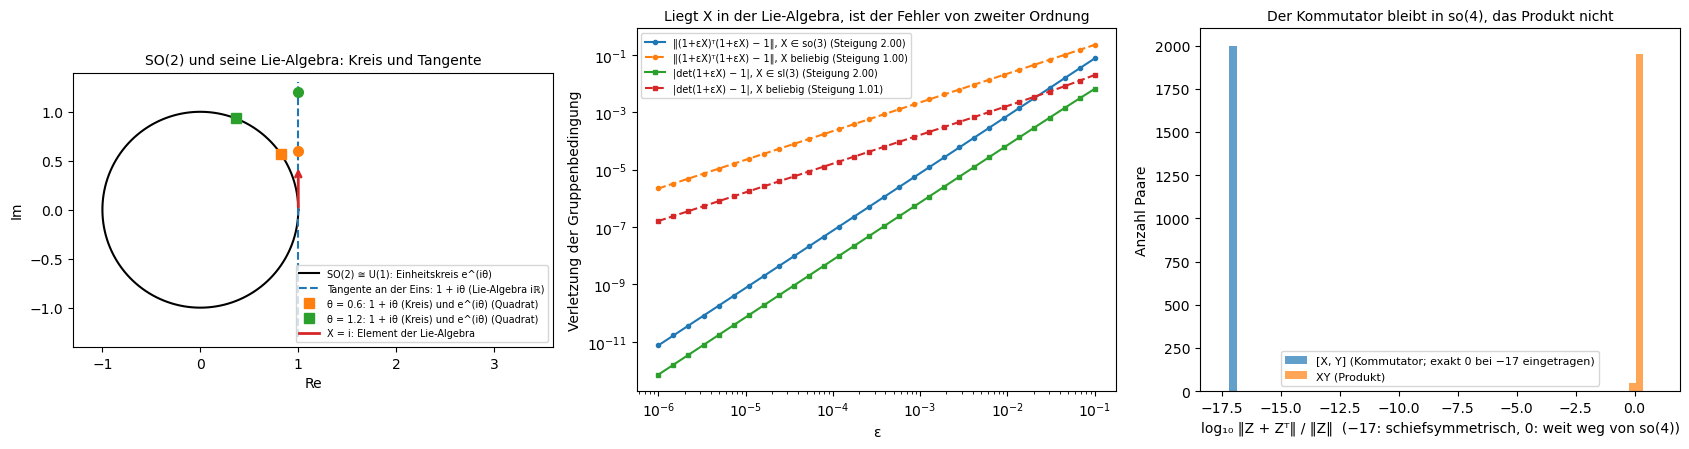

Dimension des Tangentialraums (numerisch) und Formel, n = 2, 3, 4, 5:
  SO(n)     [1, 3, 6, 10]   Formel [1, 3, 6, 10]
  SL(n,ℝ)   [3, 8, 15, 24]   Formel [3, 8, 15, 24]
  U(n)      [4, 9, 16, 25]   Formel [4, 9, 16, 25]
  SU(n)     [3, 8, 15, 24]   Formel [3, 8, 15, 24]
  Sp(2n,ℝ)  [10, 21, 36, 55]   Formel [10, 21, 36, 55]
  SO(1,3)   6   (3 Drehungen + 3 Boosts)
Kommutator: größter Abstand von so(4) 0.0e+00;  Produkt: kleinster Abstand 0.78


In [53]:
lie.tangent_space()

**53. Die Exponentialabbildung**

Die Exponentialreihe führt von der Algebra in die Gruppe. Wie viele Terme braucht man, und wie genau ist das Ergebnis?

Die Terme wachsen zuerst und fallen dann schneller als exponentiell; bei kleiner Norm reichen 14 Terme für 10⁻¹⁰. Bei Norm 20 wird der größte Term 4·10⁷, und die Auslöschung kostet acht der sechzehn Stellen. Deshalb skalieren gute Verfahren die Matrix erst klein und quadrieren danach.

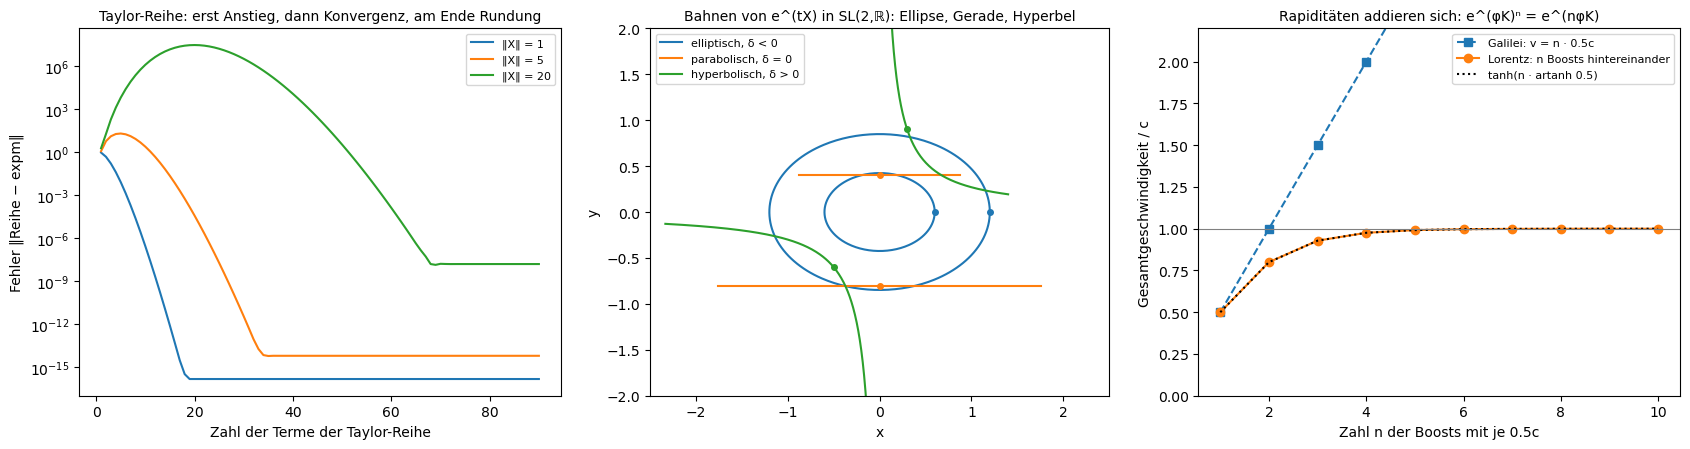

‖X‖ =  1: größter Term ‖X‖ᵏ/k! = 1.0e+00, Fehler < 1e-10: ab 14 Termen, bester Fehler 1.3e-16 (nach 19 Termen)
‖X‖ =  5: größter Term ‖X‖ᵏ/k! = 2.6e+01, Fehler < 1e-10: ab 29 Termen, bester Fehler 5.8e-15 (nach 35 Termen)
‖X‖ = 20: größter Term ‖X‖ᵏ/k! = 4.3e+07, Fehler < 1e-10: nie, bester Fehler 1.4e-08 (nach 69 Termen)
Vier Wege für ‖X‖ = 1: |Taylor(30) − expm| = 1.1e-16, |Eigenzerlegung − expm| = 6.7e-16, |Differentialgleichung − expm| = 5.0e-13
Formel cosh√δ·1 + sinh√δ/√δ·X für 500 zufällige X ∈ sl(2,ℝ): größte Abweichung 1.2e-12;  Rodrigues gegen expm: 3.3e-16
det e^X = e^(tr X): 4.039331 = 4.039331;  e^(sX)e^(tX) = e^((s+t)X): True;  e^(X+Y) = e^X e^Y für nicht vertauschende X, Y: False
Zwei Boosts mit 0.5c: 0.8000c (Formel (0.5 + 0.5)/(1 + 0.25) = 0.8c), zehn Boosts: 0.999966c


In [54]:
lie.exponential()

**54. Grenzen der Exponentialabbildung**

Nicht jedes Gruppenelement ist ein Exponential. In SL(2, ℝ) hat jedes e^X eine Spur von mindestens −2.

20 000 zufällige Exponentiale haben eine Spur von mindestens −1.9999. diag(−2, −½) mit Spur −2.5 ist deshalb kein Exponential; man erreicht es aber als Produkt von zwei. Die Exponentialabbildung ist in zusammenhängenden kompakten Gruppen surjektiv, in anderen nicht.

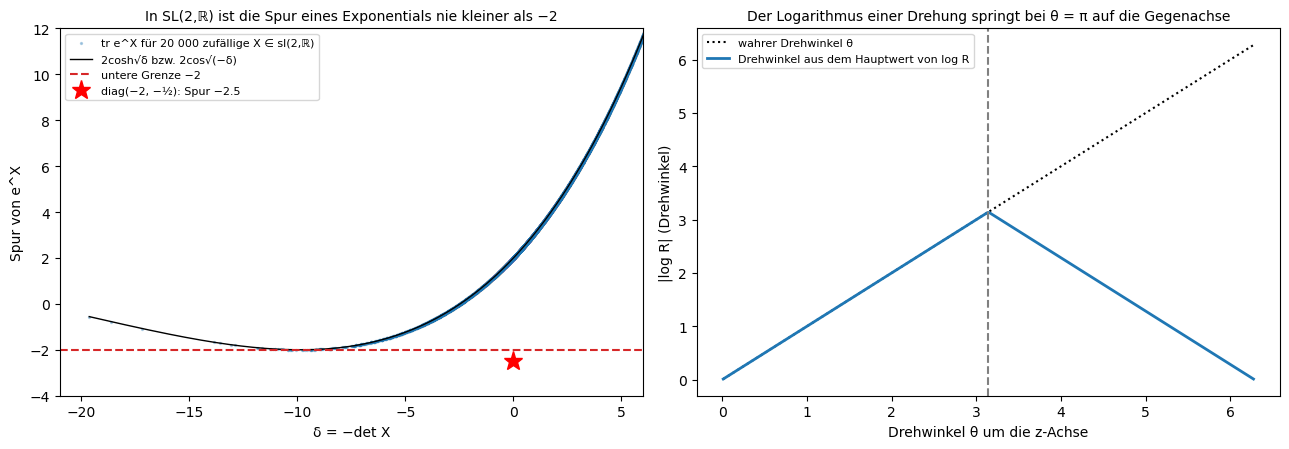

Kleinste Spur unter 20 000 Exponentialen: -1.9999 (Grenze −2);  Formel und expm stimmen überein: True
logm(diag(−2, −½)) = [[(0.6931+3.1416j), 0j], [0j, (-0.6931+3.1416j)]]: reell? False
Aber diag(−2, −½) = e^(πJ) · e^(diag(ln 2, −ln 2)): True;  e^(2πJ) = 1: True
Haar-zufällige U ∈ U(4): |e^(log U) − U| ≤ 4.7e-15, log U antihermitesch bis auf 7.4e-15
Drehwinkel aus dem Logarithmus bei θ = 0.9π, 1.1π, 1.5π: [0.9, 0.9, 0.5] · π


In [55]:
lie.exp_limits()

**55. Die Baker-Campbell-Hausdorff-Formel**

Für Matrizen ist e^A e^B ≠ e^(A+B), wenn A und B nicht vertauschen. Die BCH-Formel schreibt das Produkt als e^C, mit C = A + B + ½[A, B] + …, nur aus Kommutatoren.

Jede weitere Ordnung senkt den Fehler um eine Potenz: Die gemessenen Steigungen sind 2.0, 3.0, 4.0 und 5.0. Jenseits von ‖A‖ + ‖B‖ = ln 2 konvergiert die Reihe nicht mehr sicher, und die Kurven rücken zusammen.

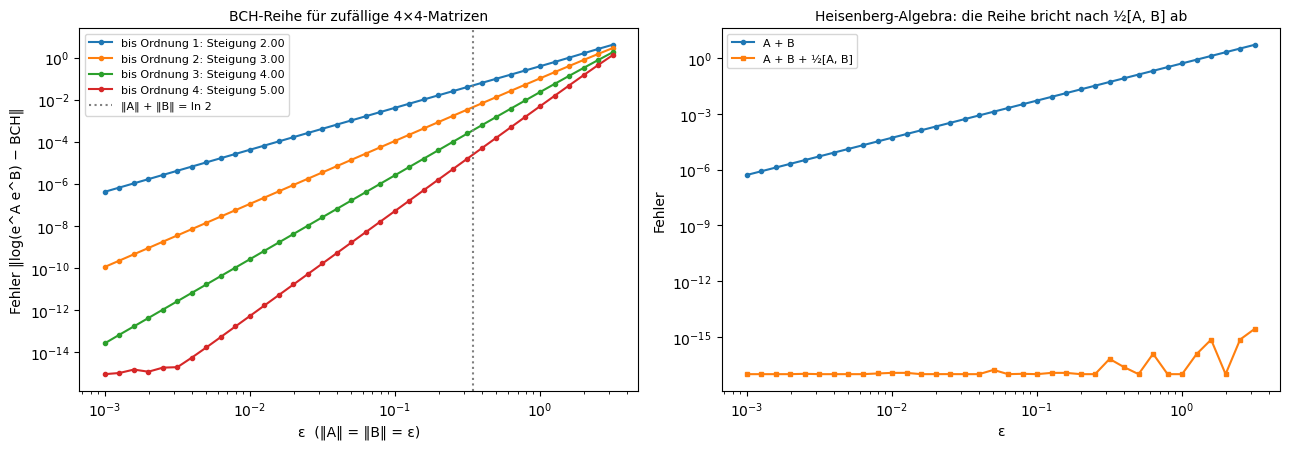

Steigungen für ε < 0.1, Fehler > 1e-12 (Theorie: Ordnung + 1): {1: 1.999, 2: 2.999, 3: 3.998, 4: 4.999}
Fehler bei ε = 0.100: ['4.1e-03', '1.1e-04', '2.5e-06', '5.0e-08'];  bei ε = 2.00: ['1.6e+00', '7.7e-01', '3.2e-01', '1.5e-01']
Heisenberg: größter Fehler mit ½[A, B] 2.7e-15, ohne 5.2e+00;  [A, B] vertauscht mit A und B: True


In [56]:
lie.bch_formula()

**56. Trotter-Produktformeln**

Ein Quantencomputer kann e^(−i(A+B)t) nicht direkt ausführen, wohl aber e^(−iAt) und e^(−iBt). Trotter zerlegt die Zeit in kleine Schritte; Strang und Suzuki machen die Zerlegung symmetrisch und genauer.

Verdoppelt man die Schritte, halbiert sich der Fehler der Lie-Trotter-Formel, viertelt sich der der Strang-Formel und fällt der der Suzuki-Formel um den Faktor 16. Die übliche Fehlerschranke liegt sechsfach über der Messung; sie ist eine obere Grenze.

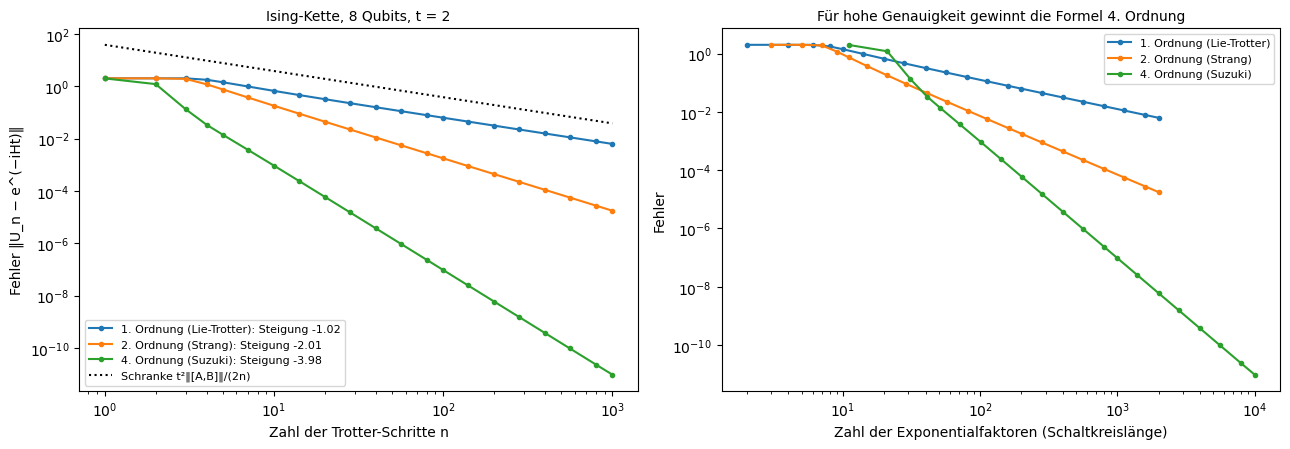

Steigungen: {'1. Ordnung (Lie-Trotter)': -1.02, '2. Ordnung (Strang)': -2.01, '4. Ordnung (Suzuki)': -3.98}
1. Ordnung (Lie-Trotter)   n = 10: 6.63e-01, n = 20: 3.19e-01 (Faktor 2.1);  Faktoren für Fehler < 1e-6: mehr als 2000 (bei n = 1000 noch 6.2e-03)
2. Ordnung (Strang)        n = 10: 1.79e-01, n = 20: 4.41e-02 (Faktor 4.1);  Faktoren für Fehler < 1e-6: mehr als 2001 (bei n = 1000 noch 1.8e-05)
4. Ordnung (Suzuki)        n = 10: 9.25e-04, n = 20: 5.92e-05 (Faktor 15.6);  Faktoren für Fehler < 1e-6: 561
‖[A, B]‖ = 19.04;  Schranke 1. Ordnung bei n = 100: 0.381, gemessen 0.063


In [57]:
lie.trotter_formulas()

**57. Lie-Gruppen-Integratoren**

Ein Kreisel dreht sich; seine Lage ist eine Drehmatrix. Gewöhnliche Integratoren verlassen die Gruppe der Drehungen, Lie-Gruppen-Verfahren rechnen in der Algebra und bleiben in ihr.

Nach 30 s hat das Euler-Verfahren eine Matrix mit Determinante 5.4, keine Drehung mehr. Runge-Kutta verlässt die Gruppe langsam (10⁻⁸), die Lie-Verfahren bleiben auf Rundungsgenauigkeit (10⁻¹³).

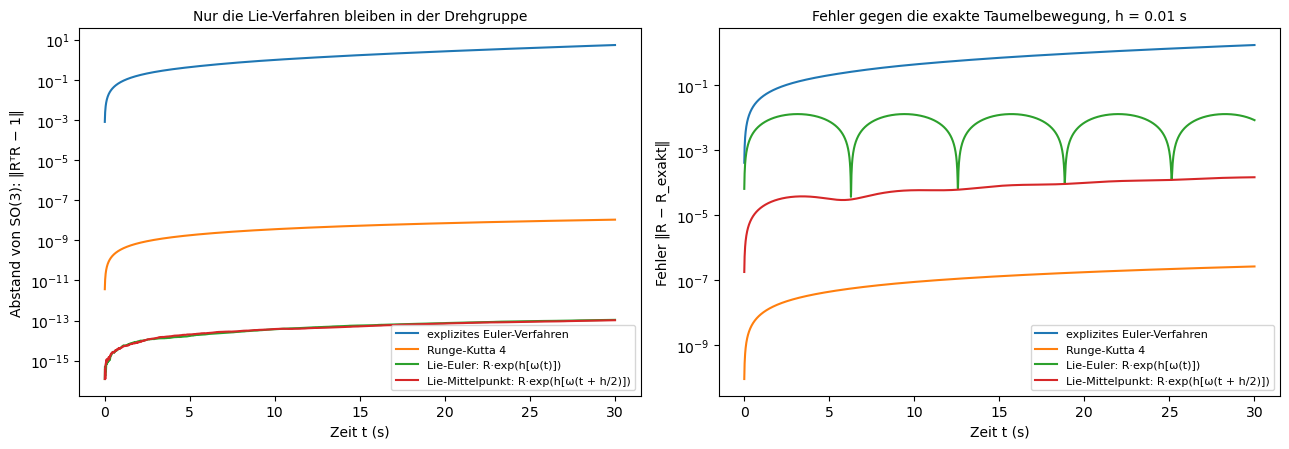

|ω| = 2.377 rad/s für alle t (Schwankung 0e+00); nur die Richtung im Körper ändert sich
explizites Euler-Verfahren               nach 30 s: Abstand von SO(3) 5.4e+00, Fehler 1.7e+00, det R = 5.444040
Runge-Kutta 4                            nach 30 s: Abstand von SO(3) 1.1e-08, Fehler 2.6e-07, det R = 1.000000
Lie-Euler: R·exp(h[ω(t)])                nach 30 s: Abstand von SO(3) 1.1e-13, Fehler 8.3e-03, det R = 1.000000
Lie-Mittelpunkt: R·exp(h[ω(t + h/2)])    nach 30 s: Abstand von SO(3) 1.0e-13, Fehler 1.4e-04, det R = 1.000000
Lie-Euler: R·exp(h[ω(t)])                halbe Schrittweite: Fehler 4.14e-03, Verhältnis 2.00
Lie-Mittelpunkt: R·exp(h[ω(t + h/2)])    halbe Schrittweite: Fehler 3.62e-05, Verhältnis 4.00
Euler: det R wächst pro Schritt um 1 + h²|ω|²; Vorhersage (1 + h²|ω|²)^3000 = 5.444, gemessen 5.444; Singulärwerte [2.201, 2.191, 1.129]


In [58]:
lie.integrators()

**58. Strukturkonstanten, adjungierte Darstellung und Killing-Form**

Die Kommutatoren der Basiselemente legen die Algebra fest (Strukturkonstanten). Die Eigenwerte der adjungierten Wirkung sind die Wurzeln; die Killing-Form, aus Spuren gebildet, unterscheidet kompakte von nichtkompakten Algebren.

Für su(3) liegen die Wurzeln auf einem regelmäßigen Sechseck, dazu zweimal 0. Die Killing-Form ist für so(3), su(2), su(3) und so(4) negativ definit, die Gruppen sind kompakt; für sl(2, ℝ) und die Lorentz-Algebra so(1,3) ist sie indefinit, für nicht halbeinfache Algebren wie die Heisenberg-Algebra entartet.

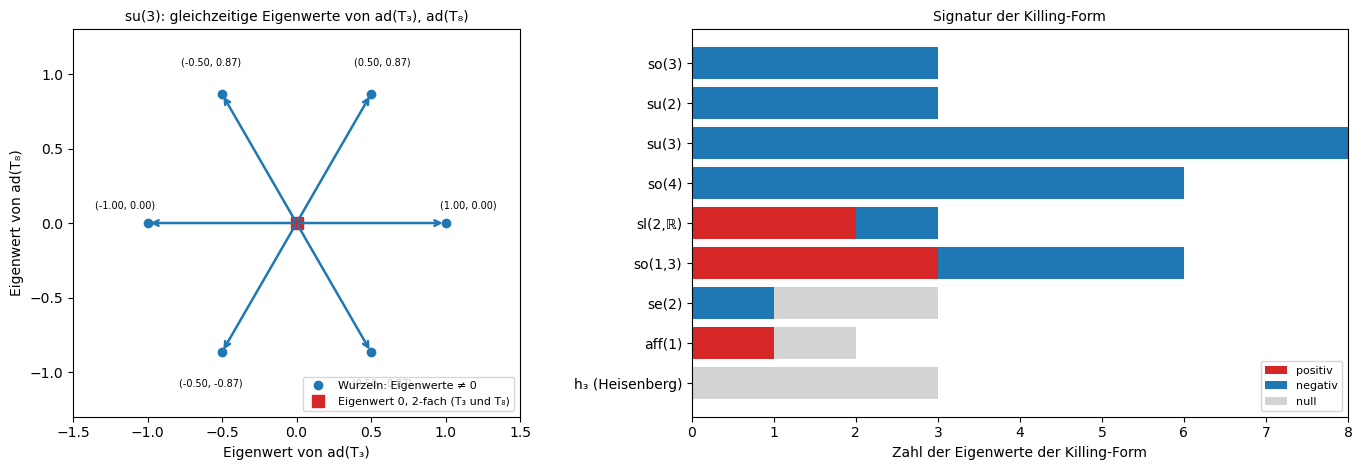

Algebra          dim  Signatur (+,−,0)  halbeinfach  kompakt  abgeleitete Reihe  Zentralreihe  Zentrum  Jacobi-Fehler
so(3)              3  (0, 3, 0)         True         True     [3]                [3]                0   0e+00
su(2)              3  (0, 3, 0)         True         True     [3]                [3]                0   0e+00
su(3)              8  (0, 8, 0)         True         True     [8]                [8]                0   0e+00
so(4)              6  (0, 6, 0)         True         True     [6]                [6]                0   0e+00
sl(2,ℝ)            3  (2, 1, 0)         True         False    [3]                [3]                0   0e+00
so(1,3)            6  (3, 3, 0)         True         False    [6]                [6]                0   0e+00
se(2)              3  (0, 1, 2)         False        False    [3, 2, 0]          [3, 2]             0   0e+00
aff(1)             2  (1, 0, 1)         False        False    [2, 1, 0]          [2, 1]             0   0e+00
h₃

In [59]:
lie.killing_form()

**59. Wurzelsysteme, Dynkin-Diagramme und E₈**

Die einfachen Lie-Algebren werden durch ihre Wurzelsysteme klassifiziert: endliche Mengen von Vektoren, die bei Spiegelung an jeder Wurzel in sich übergehen.

In zwei Dimensionen gibt es vier: A₁ × A₁ mit 4 Wurzeln, A₂ mit 6, B₂ mit 8 und G₂ mit 12. Die 240 Wurzeln von E₈, in eine Ebene projiziert, bilden acht Ringe zu je 30 Punkten mit 30-zähliger Symmetrie.

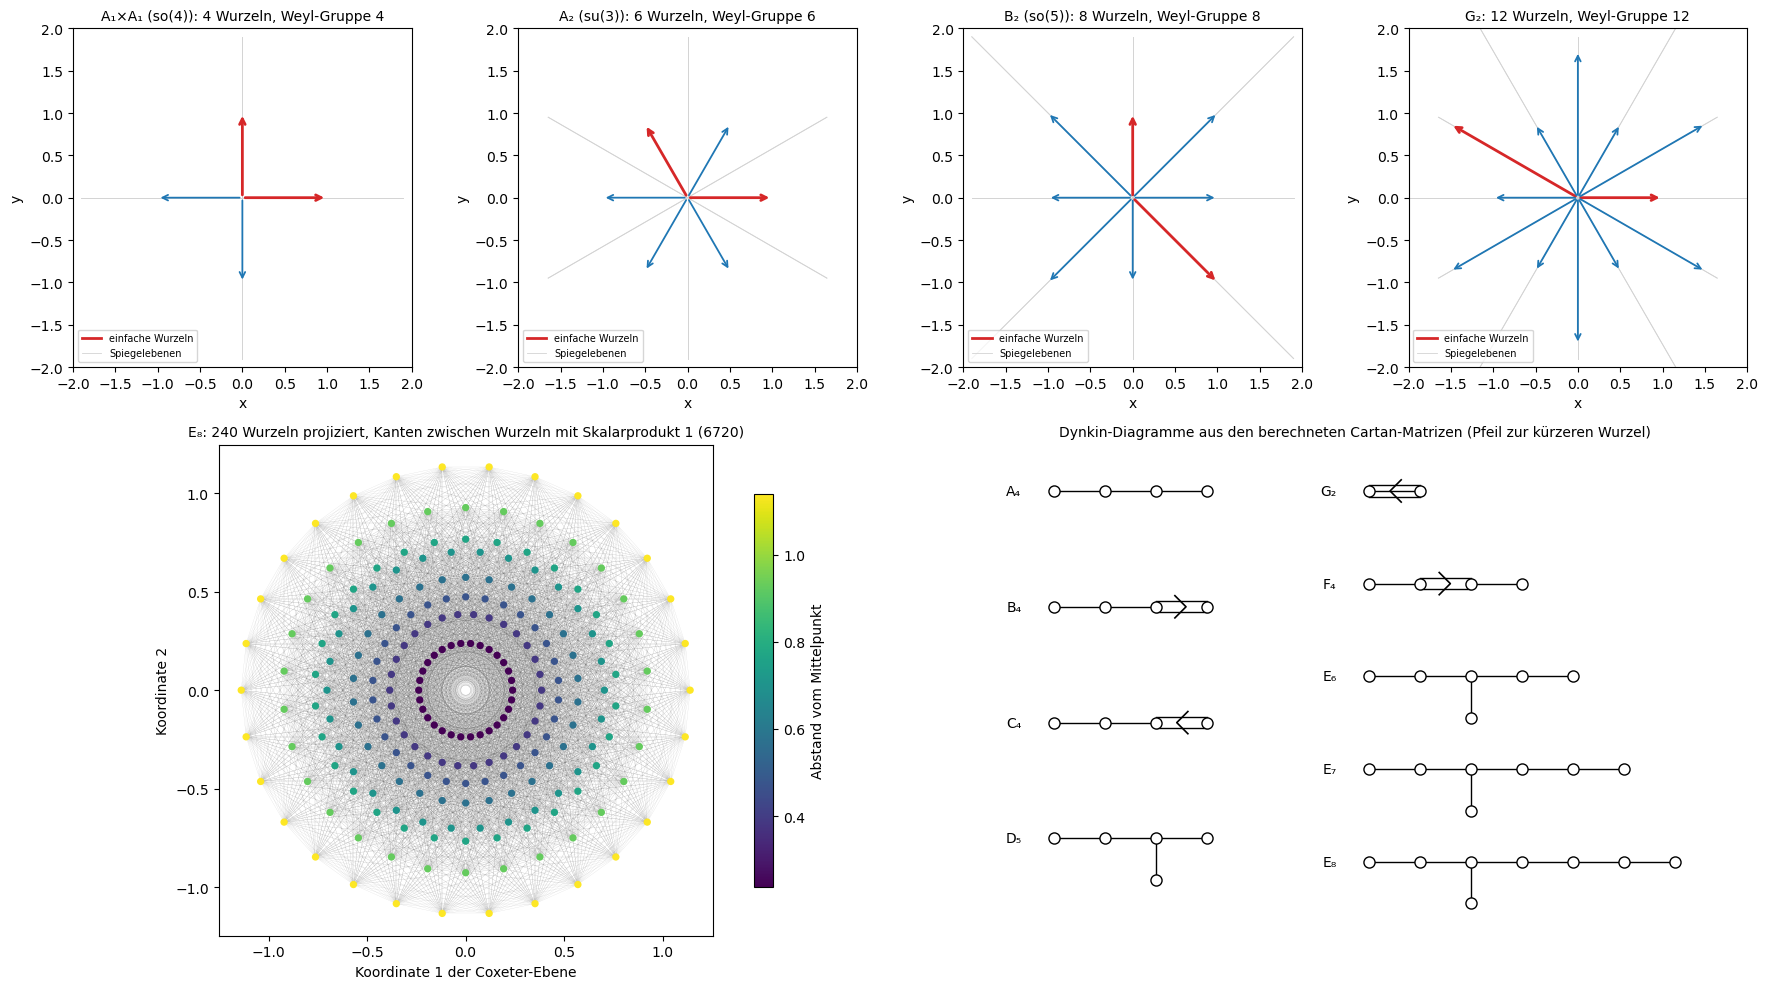

Typ  Rang  Wurzeln  Dimension  |W| (Bahn)   Produkt der Grade  h = Wurzeln/Rang  größter Grad  Cartan-Matrix = sympy
A4      4       20         24          120                120                 5             5   True
B4      4       32         36          384                384                 8             8   True
C4      4       32         36          384                384                 8             8   True
D5      5       40         45        1 920              1 920                 8             8   True
G2      2       12         14           12                 12                 6             6   True
F4      4       48         52        1 152              1 152                12            12   True
E6      6       72         78       51 840             51 840                12            12   True
E7      7      126        133            –          2 903 040                18            18   True
E8      8      240        248            –        696 729 600              

In [60]:
lie.root_systems()

**60. Dynamische Lie-Algebren**

Welche Operationen ein Quantenschaltkreis erreicht, hängt von der Lie-Algebra ab, die seine Generatoren erzeugen. Wächst sie exponentiell mit der Zahl der Qubits, drohen Barren Plateaus: flache Landschaften, in denen das Training scheitert.

Mit X- und ZZ-Termen wächst die Algebra nur quadratisch (91 Dimensionen bei 7 Qubits auf einer Linie), mit Z dazu exponentiell (16 383). Eine einzige zusätzliche Drehung kann aus einer kleinen Algebra die volle machen.

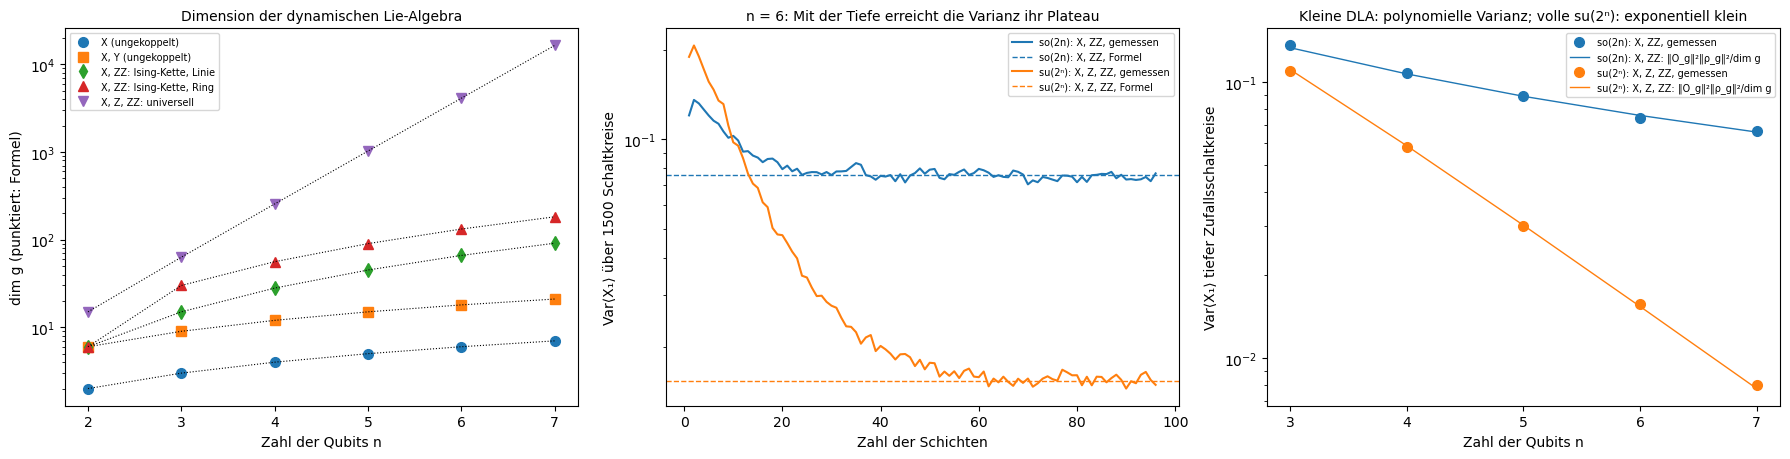

dim g für n = 2 … 7:
  X (ungekoppelt)              [2, 3, 4, 5, 6, 7]   Formel [2, 3, 4, 5, 6, 7]
  X, Y (ungekoppelt)           [6, 9, 12, 15, 18, 21]   Formel [6, 9, 12, 15, 18, 21]
  X, ZZ: Ising-Kette, Linie    [6, 15, 28, 45, 66, 91]   Formel [6, 15, 28, 45, 66, 91]
  X, ZZ: Ising-Kette, Ring     [6, 30, 56, 90, 132, 182]   Formel [6, 30, 56, 90, 132, 182]
  X, Z, ZZ: universell         [15, 63, 255, 1023, 4095, 16383]   Formel [15, 63, 255, 1023, 4095, 16383]
Varianz, n = 3 … 7:
  so(2n): X, ZZ      gemessen ['0.1358', '0.1081', '0.0889', '0.0745', '0.0663']
                     Formel   ['0.1333', '0.1071', '0.0889', '0.0758', '0.0659']
  su(2ⁿ): X, Z, ZZ   gemessen ['0.1099', '0.0584', '0.0301', '0.0157', '0.0080']
                     Formel   ['0.1111', '0.0588', '0.0303', '0.0154', '0.0078']
Verhältnis der Varianzen bei n = 7: 8.3


In [61]:
lie.dynamical_lie_algebras()

**61. Charaktertafeln endlicher Gruppen**

Die Charaktertafel fasst die irreduziblen Darstellungen einer Gruppe zusammen: eine Zeile je Darstellung, eine Spalte je Konjugationsklasse, als Eintrag die Spur.

Für alle sechs Gruppen gilt Σ dᵢ² = |G|, jeder Grad teilt |G|, Zeilen und Spalten sind orthogonal. S₄ hat 5 Klassen und damit 5 irreduzible Darstellungen mit den Graden 1, 1, 2, 3, 3; 1 + 1 + 4 + 9 + 9 = 24.

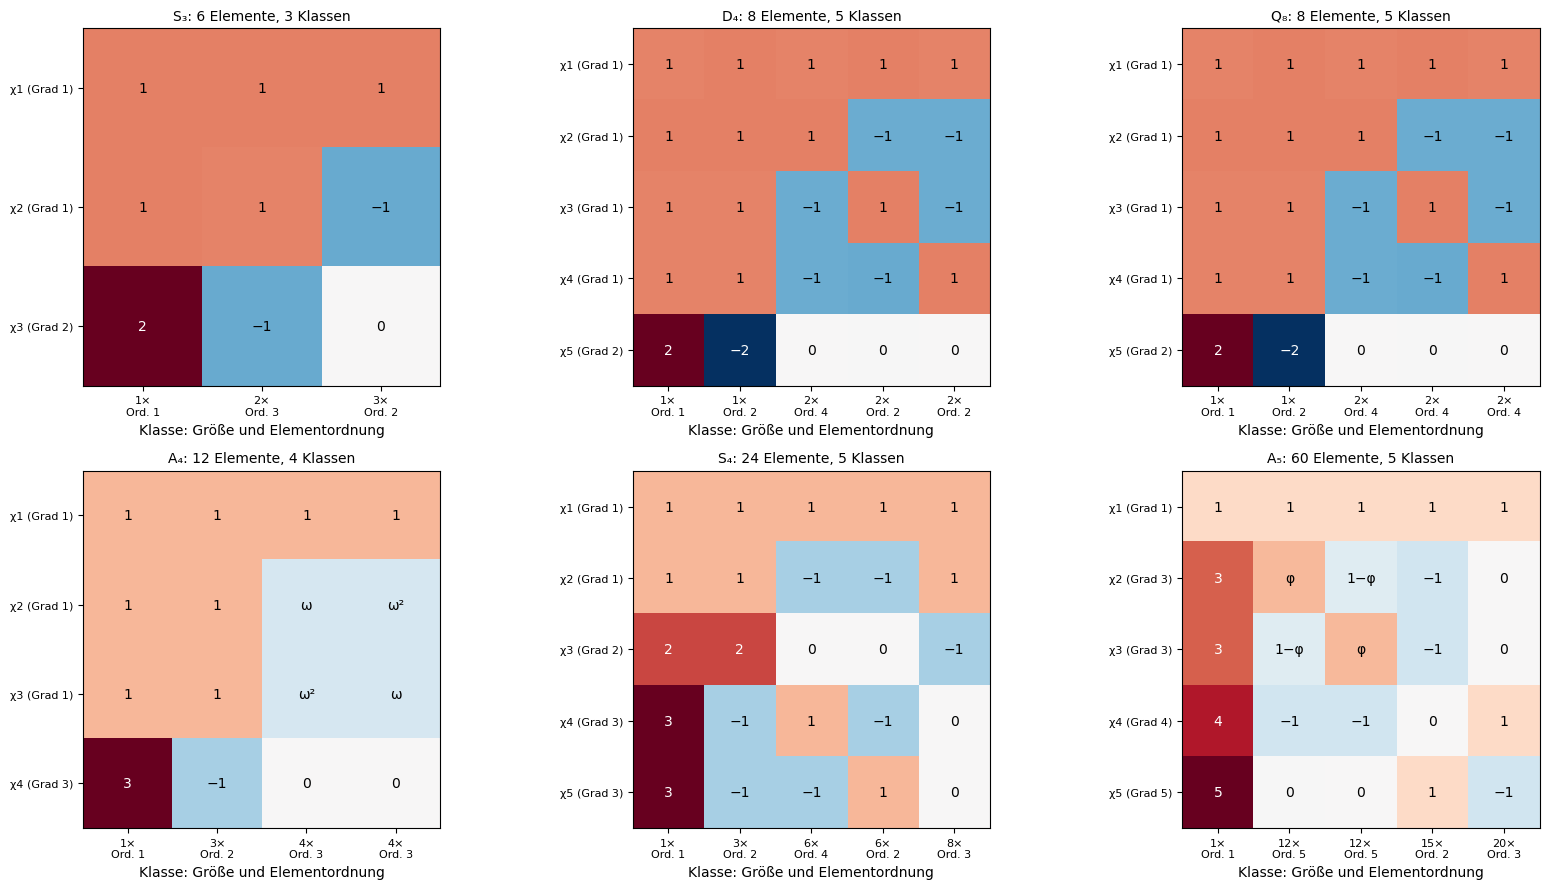

S₃: Grade [1, 1, 2], Σd² = 6 = |G| = 6, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 3
D₄: Grade [1, 1, 1, 1, 2], Σd² = 8 = |G| = 8, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 5
Q₈: Grade [1, 1, 1, 1, 2], Σd² = 8 = |G| = 8, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 1
A₄: Grade [1, 1, 1, 3], Σd² = 12 = |G| = 12, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 3
S₄: Grade [1, 1, 2, 3, 3], Σd² = 24 = |G| = 24, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 9
A₅: Grade [1, 3, 3, 4, 5], Σd² = 60 = |G| = 60, Grade teilen |G|: True, Zeilen orthonormal: True, Spalten orthogonal: True, Elemente der Ordnung 2: 15
Tafeln von D₄ und Q₈ gleich: True
S₄ auf 4 Ecken     : Charakter [4, 0, 0, 2, 1], Vielfachheiten der irreduziblen 

In [62]:
lie.character_tables()

**62. Molekülschwingungen: Auswahlregeln aus der Charaktertafel**

Mit der Charaktertafel der Punktgruppe zerfallen die Schwingungen eines Moleküls in Darstellungen; daraus folgt, welche im Infrarot- und welche im Raman-Spektrum sichtbar sind.

Wasser hat drei Schwingungen, alle in beiden Spektren aktiv. Methan hat 9 Schwingungen, aber nur 4 verschiedene Frequenzen. Bei Molekülen mit Inversionszentrum ist keine Schwingung in beiden Spektren aktiv (Alternativverbot): Benzol hat 4 im Infrarot-, 7 im Raman-Spektrum und 9 stumme.

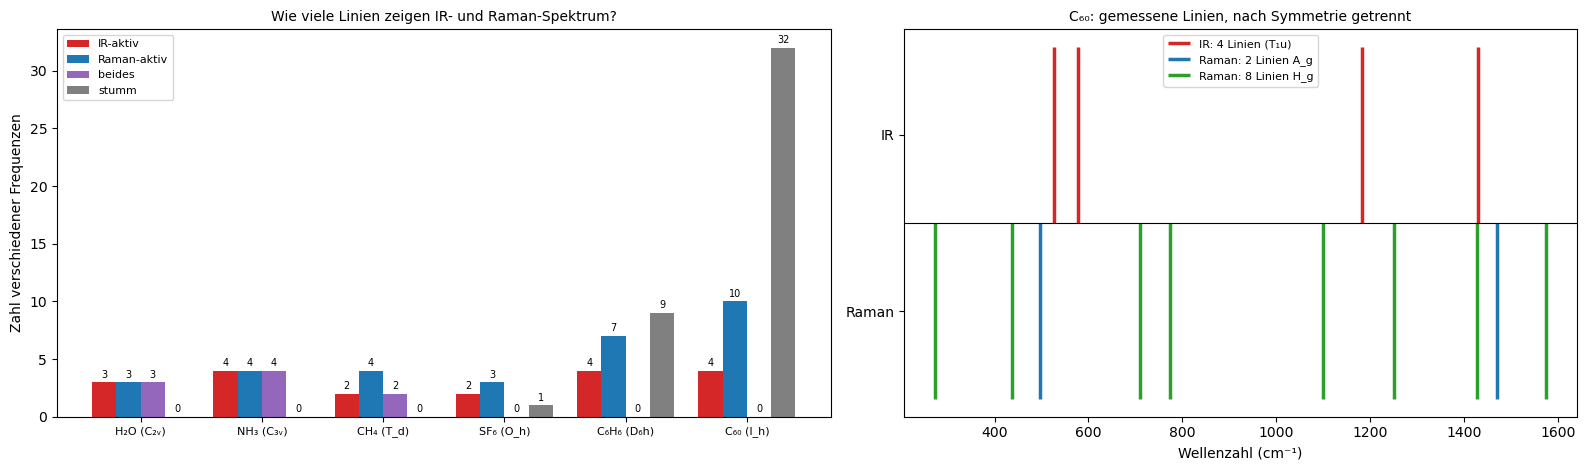

H₂O (C₂ᵥ)    Gruppe   4: Γ_vib = 2A₁ + B₂  (3 Schwingungen, 3 Frequenzen); IR: A₁, B₂; Raman: A₁, B₂
NH₃ (C₃ᵥ)    Gruppe   6: Γ_vib = 2A₁ + 2E  (6 Schwingungen, 4 Frequenzen); IR: A₁, E; Raman: A₁, E
CH₄ (T_d)    Gruppe  24: Γ_vib = A₁ + E + 2T₂  (9 Schwingungen, 4 Frequenzen); IR: T₂; Raman: A₁, E, T₂
SF₆ (O_h)    Gruppe  48: Γ_vib = A₁g + Eg + T₂g + 2T₁u + T₂u  (15 Schwingungen, 6 Frequenzen); IR: T₁u; Raman: A₁g, Eg, T₂g
C₆H₆ (D₆h)   Gruppe  24: Γ_vib = 2A₁g + A₂g + 2B₁u + 2B₂u + A₂u + 2B₂g + 4E₂g + 3E₁u + 2E₂u + E₁g  (30 Schwingungen, 20 Frequenzen); IR: A₂u, E₁u; Raman: A₁g, E₂g, E₁g
C₆₀ (I_h)    Gruppe 120: Γ_vib = 2Ag + Au + 3T₁g + 4T₂g + 4T₁u + 5T₂u + 6Gg + 6Gu + 8Hg + 7Hu  (174 Schwingungen, 46 Frequenzen); IR: T₁u; Raman: Ag, Hg

Charaktertafel von T_d, aus den Symmetrieoperationen von CH₄ berechnet:
            1E    3C2     6σ    6S4    8C3
A₁           1      1      1      1      1
A₂           1      1     −1     −1      1
E            2      2      0      0     −1
T₂    

In [63]:
lie.molecular_vibrations()

**63. Spin j: die Darstellungen von SU(2)**

Zu jedem halbzahligen oder ganzzahligen j gibt es genau eine irreduzible Darstellung der Dimension 2j + 1. Gezeigt sind die Wigner-Matrix für j = 10 und ein gedrehter Spin im Stern-Gerlach-Versuch.

Nach einer Drehung um 90° verteilt sich ein Zustand auf viele m; die hellen Ränder liegen dort, wo die klassischen Bahnen eines Kreisels sich häufen, das Schachbrettmuster ist Interferenz. Die Verteilung des um 60° gedrehten Spins ist genau binomial.

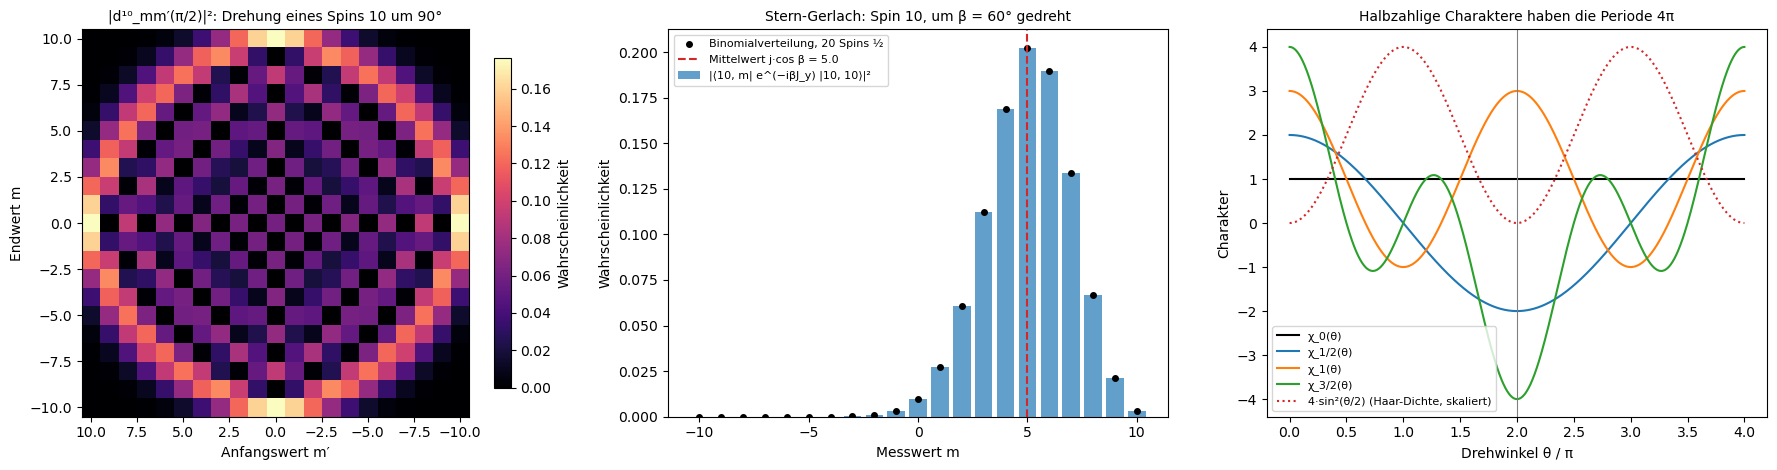

  j  dim  |[Jx,Jy] − iJz|   |J² − j(j+1)|   e^(−2πiJz)   |d − sympy|
 0.5    2         0.0e+00         0.0e+00          -1   5.6e-17
 1.0    3         2.2e-16         4.4e-16          +1   1.7e-16
 1.5    4         2.2e-16         0.0e+00          -1   1.1e-16
 2.0    5         5.6e-16         8.9e-16          +1   1.7e-16
 5.0   11         4.0e-15         3.6e-15          +1   –
Stern-Gerlach: wahrscheinlichstes m = 5 (P = 0.202), Mittelwert 5.0000, |P − Binomial| ≤ 1.4e-16
Charaktere χ_j, j = 0 … 3, orthonormal mit der Dichte sin²(θ/2)/π: größte Abweichung von der Einheitsmatrix 8.0e-15


In [64]:
lie.spin_j()

**64. Clebsch-Gordan-Koeffizienten und Auswahlregeln**

Zwei Drehimpulse koppeln zu einem Gesamtdrehimpuls; die Clebsch-Gordan-Koeffizienten schreiben die gekoppelten Zustände in der Produktbasis. Nach Wigner-Eckart folgen daraus die Auswahlregeln der Atomphysik.

Für zwei Spins 1 sind die Zustände mit Gesamtspin 2 und 0 symmetrisch, die mit Spin 1 antisymmetrisch. Übergänge mit einem Photon ändern den Drehimpuls um höchstens 1; das folgt allein aus der Symmetrie.

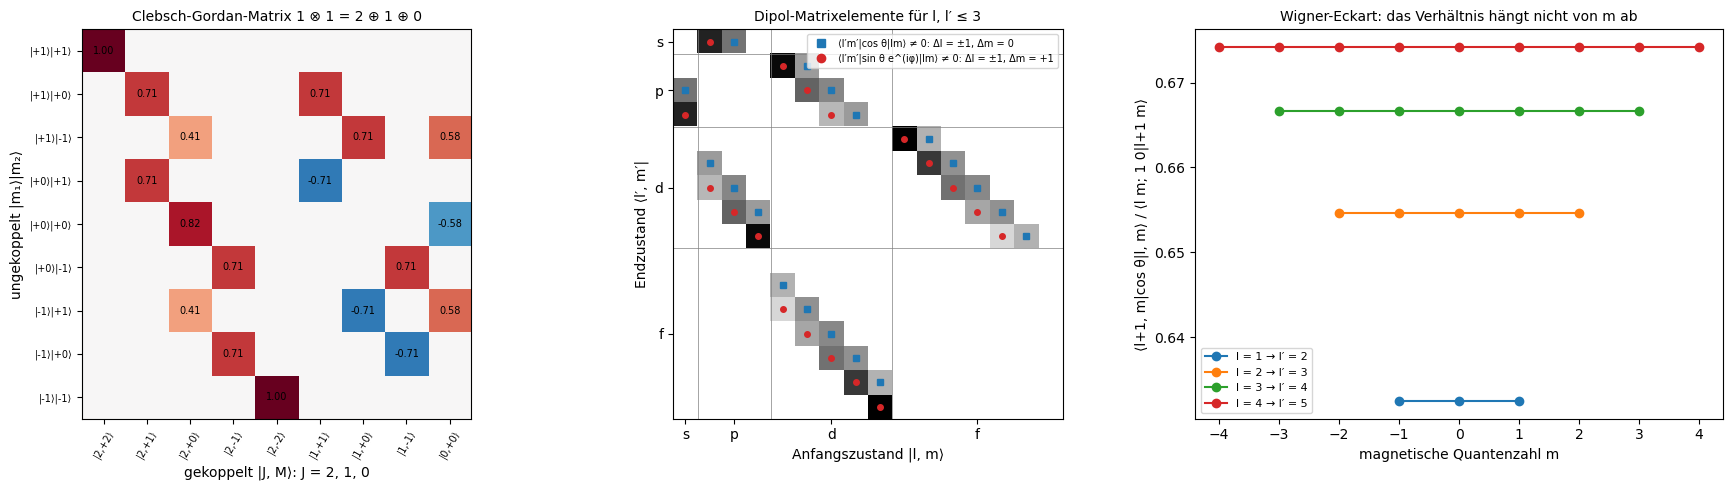

1/2 ⊗ 1/2: 4 Zustände = Σ(2J+1) über J = 0, 1;  größte Abweichung von sympy 1.1e-16
1 ⊗ 1: 9 Zustände = Σ(2J+1) über J = 0, 1, 2;  größte Abweichung von sympy 1.4e-16
3/2 ⊗ 1: 12 Zustände = Σ(2J+1) über J = 1/2, 3/2, 5/2;  größte Abweichung von sympy 3.3e-16
2 ⊗ 3/2: 20 Zustände = Σ(2J+1) über J = 1/2, 3/2, 5/2, 7/2;  größte Abweichung von sympy 6.7e-16
Kugelflächenfunktionen bis l = 3 orthonormal (Quadratur): True
cos θ: 18 von 256 Matrixelementen ≠ 0, alle mit Δl = ±1 und Δm = 0: True;  sin θ e^(iφ): 18 ≠ 0, alle mit Δl = ±1, Δm = +1: True
Reduzierte Matrixelemente (Verhältnis, Streuung über m): {1: (0.632456, 4.9e-15), 2: (0.654654, 7e-15), 3: (0.666667, 8.6e-15), 4: (0.6742, 9.7e-15)}
Beispiel ⟨1,0|cos θ|0,0⟩ = 0.577350 (Formel 1/√3 = 0.577350);  ⟨0,0|cos θ|0,0⟩ = 5.6e-17


In [65]:
lie.cg_coefficients()

**65. SU(3) und der Achtfache Weg**

1961 ordneten Gell-Mann und Ne'eman die Hadronen nach den Darstellungen von SU(3): Quarks im Triplett, Baryonen im Oktett und im Dekuplett.

Die Quarks u, d, s bilden ein Dreieck, das Oktett ein Sechseck mit zwei Zuständen in der Mitte (Σ⁰ und Λ), das Dekuplett ein Dreieck mit dem Ω⁻ an der Spitze. Die Ladungen aus Q = T₃ + Y/2 stimmen mit den Teilchen überein; das Ω⁻ wurde 1962 vorhergesagt und 1964 gefunden.

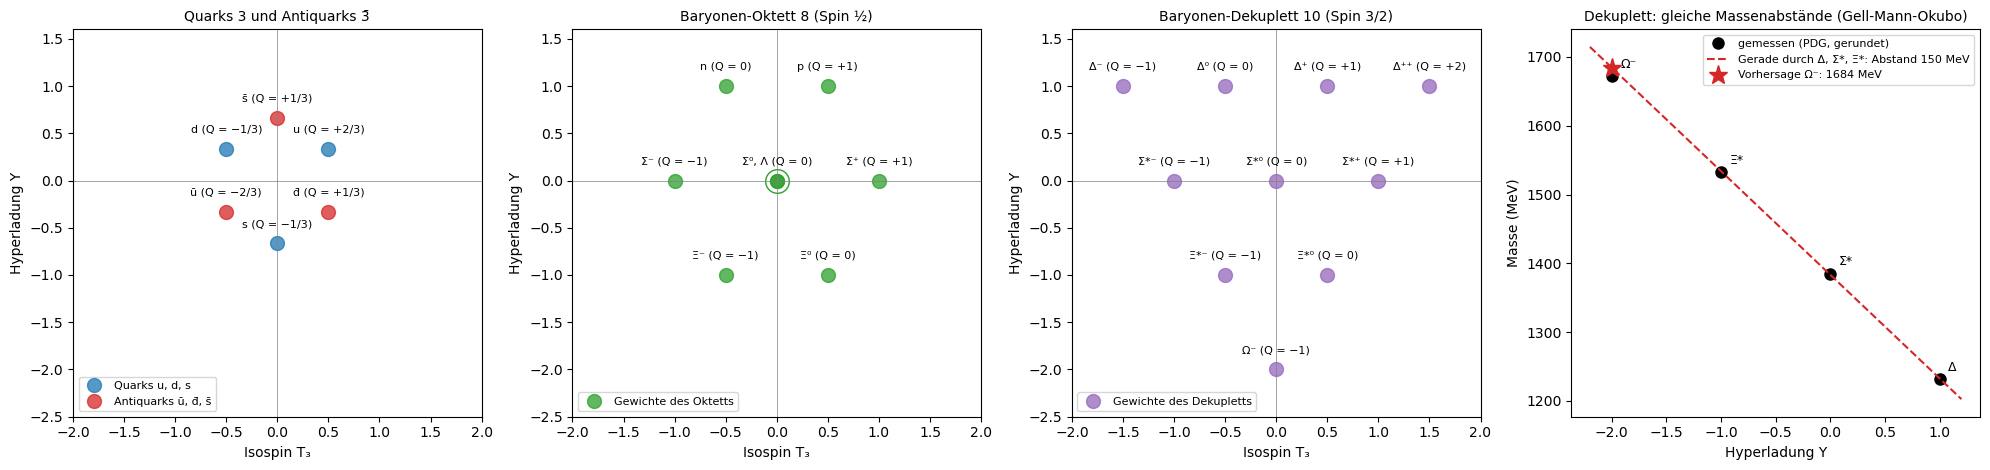

3     : Vertauschungsfehler 1e-16;  Zerlegung über C₂: 3 bzw. 3̄
3̄    : Vertauschungsfehler 1e-16;  Zerlegung über C₂: 3 bzw. 3̄
8     : Vertauschungsfehler 3e-16;  Zerlegung über C₂: 8
3⊗3̄  : Vertauschungsfehler 3e-16;  Zerlegung über C₂: 1 ⊕ 8
3⊗3   : Vertauschungsfehler 2e-16;  Zerlegung über C₂: 3 bzw. 3̄ ⊕ 6 bzw. 6̄
3⊗3⊗3 : Vertauschungsfehler 7e-16;  Zerlegung über C₂: 1 ⊕ 2×8 ⊕ 10
Dimensionsformel (p+1)(q+1)(p+q+2)/2: (1,0) → 3, (1,1) → 8, (2,0) → 6, (3,0) → 10, (2,2) → 27, (3,3) → 64
Strukturkonstanten: f₁₂₃ = 1.0000, f₁₄₇ = 0.5000, f₄₅₈ = 0.8660 (√3/2 = 0.8660)
Dekuplett: 10 Zustände; Massenabstände [153, 148, 139] MeV; Vorhersage Ω⁻ 1684 MeV, gemessen 1672 MeV
Oktett, Gell-Mann-Okubo (N + Ξ)/2 = 1128.5 MeV gegen (3Λ + Σ)/4 = 1135.2 MeV


In [66]:
lie.su3()

**66. Schur-Weyl-Dualität**

Die Zustände von n Qubits zerfallen gleichzeitig nach dem Gesamtspin (SU(2)) und nach Vertauschungen der Qubits (Sₙ). Daraus folgen die Vielfachheiten jedes Spins und die Mittelung über zufällige Unitäre.

In 10 Qubits kommt Spin 5 einmal vor (der symmetrische Unterraum), Spin 0 42-mal. Für n = 1 bis 8 stimmen die gezählten Vielfachheiten mit der Formel und mit den Dimensionen der Darstellungen von Sₙ überein.

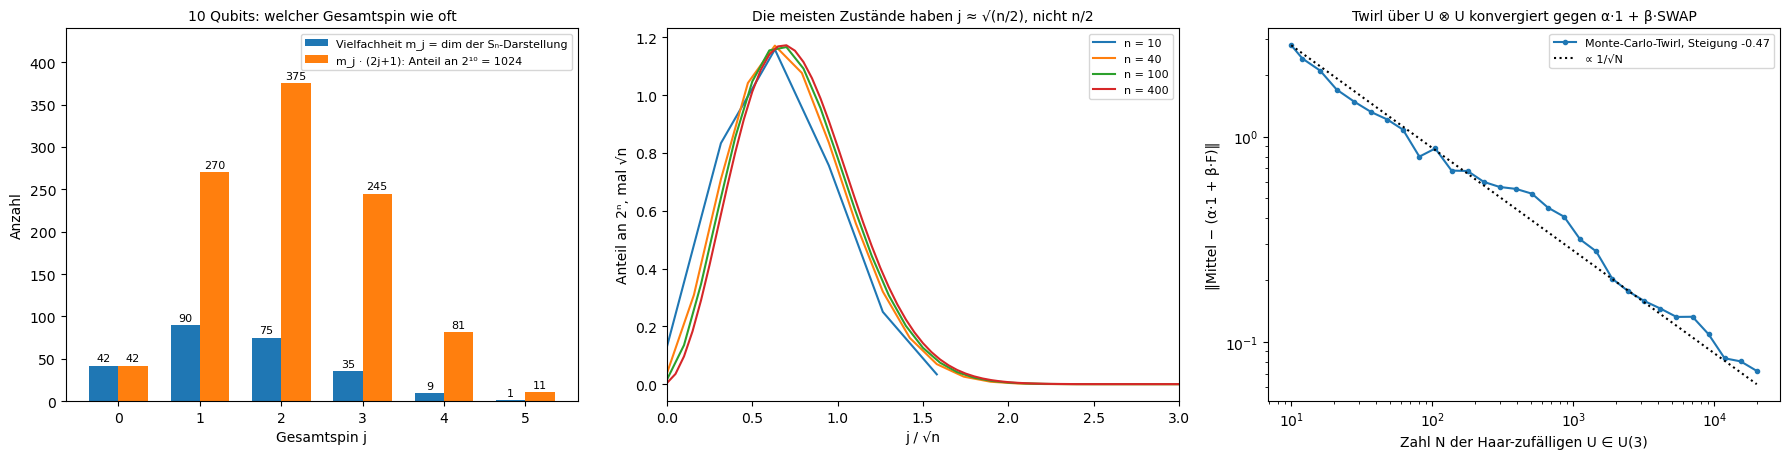

n = 1: Vielfachheiten {0.5: 1}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 2: Vielfachheiten {1.0: 1, 0.0: 1}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 3: Vielfachheiten {1.5: 1, 0.5: 2}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 4: Vielfachheiten {2.0: 1, 1.0: 3, 0.0: 2}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 5: Vielfachheiten {2.5: 1, 1.5: 4, 0.5: 5}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 6: Vielfachheiten {3.0: 1, 2.0: 5, 1.0: 9, 0.0: 5}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 7: Vielfachheiten {3.5: 1, 2.5: 6, 1.5: 14, 0.5: 14}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 8: Vielfachheiten {4.0: 1, 3.0: 7, 2.0: 20, 1.0: 28, 0.0: 14}  = Formel = Hakenlänge: True,  Σ m_j(2j+1) = 2ⁿ: True
n = 10: [1, 9, 35, 75, 90, 42] für j = [5.0, 4.0, 3.0, 2.0, 1.0, 0.0]
Twirl auf zwei Qutrits: α = -0.1879, β = -0.4066;  nach 20000 Stichproben Abweichung 0.0723 (Steigung -0.47), Spur bl

In [67]:
lie.schur_weyl()